# Exploratory Data Analysis: NBA Draft Combine

**Author:** Rasheed Martin

This notebook provides a comprehensive exploratory analysis of the NBA Draft Combine dataset, focusing on uncovering key relationships between physical measurements, combine performance, and NBA career outcomes. The workflow includes:

- **Data Extraction & Cleaning:** Loading combine stats, NBA performance metrics, and award information for thousands of players and seasons.
- **Univariate & Bivariate Analysis:** Summarizing distributions, missingness, and correlations among physical and performance features.
- **Visualization:** Using barplots, heatmaps, pairplots, and boxplots to reveal trends by position, season, and award status.
- **Key Insights:** Identifying which combine metrics are most predictive of NBA success, and how standout physical traits relate to accolades such as All-Star, All-NBA, and Defensive Team selections.

This analysis supports downstream modeling and provides actionable insights for scouting, player development, and understanding the impact of draft combine results on NBA careers.

### Required Imports

This notebook uses the following libraries for data analysis and visualization:

- **duckdb**: Efficient SQL querying and database connection.
- **polars**: Fast DataFrame operations for data manipulation.
- **pathlib**: File and directory path management.
- **matplotlib.pyplot**: Plotting and visualization.
- **seaborn**: Advanced statistical visualizations.
- **numpy**: Numerical computations and array operations.
- **IPython.display**: Enhanced display of dataframes and outputs.
- **scipy.stats**: Statistical analysis and probability plots.

These imports enable efficient data extraction, transformation, and visualization throughout the NBA Draft Combine exploratory analysis workflow.

In [246]:
import duckdb
import polars as pl
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from IPython.display import display
from scipy.stats import probplot



In [247]:
# Set Visualization Path
visualization_path = Path.cwd().parent.parent / "visualizations/draft_combine/exploratory_analysis"
visualization_path.mkdir(parents=True, exist_ok=True)

### Connect to the Database

To begin our analysis, we establish a connection to the NBA Draft Combine database using DuckDB. This enables efficient querying and data extraction for subsequent exploration.

**Workflow:**
- Use the `get_duckdb_connection()` function to connect to the database.
- Verify the connection by running a simple query (e.g., list players born in 1990).
- If the query returns expected results, the setup is complete and ready for further analysis.

This step ensures our data pipeline is working and that we can reliably access the NBA Draft Combine data for all downstream tasks.

In [248]:
def get_duckdb_connection(db_path=None, read_only=True):
    if db_path is None:
        db_path = Path.cwd().parent.parent / "data/refined_raw_data/nba_data.duckdb"
    
    if not db_path.exists():
        raise FileNotFoundError(f"DuckDB database not found at {db_path}")
    print(f"Connected to: {db_path.resolve()}")
    return duckdb.connect(db_path, read_only=read_only)

## Test the Database Connection

To verify our connection to the NBA Draft Combine database, we run a simple query that lists all players born in 1990. This quick test ensures the database is accessible and that queries return expected results before proceeding with deeper analysis.

**Example Output:**
- Paul George
- Gordon Hayward
- Hassan Whiteside
- ...

If the query executes successfully and returns player names, our connection setup is complete and ready for further data exploration.

In [249]:
with get_duckdb_connection() as con:
    try:
        result = con.execute("SELECT p.name from main.players p where birth_year=1990;").fetchall()
        for row in result:
            print("-", row[0])
    except Exception as e:
        print("Failed to connect or query:", e)

Connected to: /Users/rashe/PycharmProjects/PredictingNBACareers/data/refined_raw_data/nba_data.duckdb
- Travis Wear
- John Henson
- Al-Farouq Aminu
- Mason Plumlee
- Damian Lillard
- Sean Kilpatrick
- Ricky Rubio
- JaMychal Green
- Marshall Plumlee
- Reggie Jackson
- Nikola Vucevic
- Jeff Withey
- John Wall
- Draymond Green
- Tyler Zeller
- Tim Frazier
- Lorenzo Brown
- Gorgui Dieng
- Jae Crowder
- Avery Bradley
- Darius Miller
- Paul George
- Kyle O'Quinn
- Jrue Holiday
- Greg Monroe
- Gordon Hayward
- Quincy Acy
- Robert Covington
- DeMarcus Cousins
- Klay Thompson
- Lance Stephenson
- Matthew Dellavedova
- Iman Shumpert
- Shelvin Mack
- Erik Murphy
- Henry Sims
- Jan Vesely
- Seth Curry
- James Southerland
- Tyshawn Taylor
- Ognjen Kuzmic
- Arnett Moultrie
- James Nunnally
- Donatas Motiejunas
- Carrick Felix
- Chris Babb
- Justin Hamilton
- Daniel Orton
- Peyton Siva
- Casper Ware
- Scott Machado
- Travis Leslie
- Malcolm Lee
- Tyler Honeycutt
- Kostas Papanikolaou
- Cory Jefferson

### Exploring Data

Let's begin our exploration by loading the NBA Draft Combine data. Key columns include player name, season, stat name, and stat value—these form the foundation for our analysis. By focusing on these attributes, we can investigate trends in player performance, physical measurements, and how these metrics relate to NBA outcomes.

We'll start by querying and displaying the combine dataset, then progressively transform and analyze the data to uncover meaningful insights. This workflow will help us understand the distribution of combine stats, identify missing values, and prepare the data for deeper statistical analysis and visualization.

In [250]:
query = """
SELECT p.name as Player, s.label as Season, st.name as Stat, csv.value as Value, csv.player_id as Id, po.name as Position
FROM nba_data.main.combine_stat_values csv
JOIN players p ON csv.player_id = p.player_id
FULL OUTER JOIN player_positions pp ON pp.player_id = p.player_id
FULL OUTER JOIN positions po on po.position_id = pp.position_id
JOIN seasons s ON csv.season_id = s.season_id
JOIN stats st on csv.stat_id = st.stat_id
"""
with get_duckdb_connection() as con:
    df_combine = pl.from_arrow(con.execute(query).arrow())
    display(df_combine.head())

Connected to: /Users/rashe/PycharmProjects/PredictingNBACareers/data/refined_raw_data/nba_data.duckdb


Player,Season,Stat,Value,Id,Position
str,str,str,f32,i32,str
"""Eric Gordon""","""2008-09""","""Height""",74.0,412,"""SF"""
"""Udonis Haslem""","""2002-03""","""Lane_Agility_Time""",11.8,233,"""PF"""
"""Zeke Nnaji""","""2020-21""","""Length_x_Width_Hand""",94.5,1837,"""PF"""
"""Andrew Goudelock""","""2011-12""","""Lane_Agility_Time""",10.33,1657,"""PG"""
"""Cleanthony Early""","""2014-15""","""Weight""",209.399994,1735,"""SF"""


### Transforming Data: Pivoting from Long to Wide Format

To facilitate analysis and visualization, we convert the combine dataset from long format (where each row is a single stat for a player-season) to wide format (where each row contains all stats for a player-season). This is accomplished using a pivot table, which spreads each statistic into its own column. The resulting wide dataframe allows for easier computation of correlations, summary statistics, and advanced visualizations across all combine metrics.

In [251]:
# Group by all columns except position, and join the positions
df_combine = df_combine.group_by(
    ['Id', 'Player', 'Season', 'Value', 'Stat'],  # all other columns
).agg(pl.col("Position").unique().sort().alias("Position"))

df_combine = df_combine.with_columns(
    pl.col("Position").list.join("/")
)
df_combine.height

30204

In [252]:
df_wide_view: pl.DataFrame = df_combine.pivot(
    values="Value",
    index=["Position", "Player", "Season"],
    on="Stat"
)
df_wide_view.head()

Position,Player,Season,Lane_Agility_Time,Standing_Reach_Max_Vertical,Length_of_Hand,Weight,Width_of_Hand,Max_Vertical_Leap,Height,Ration_of_Wingspan,Standing_Reach,Wingspan,Standing_Reach_Vertical,Max_Bench_Press,3_Quarter_Sprint,Shuttle_Run,Length_x_Width_Hand,Bmi,Standing_Vertical,Body_Fat
str,str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""PG/SG""","""Duane Washington Jr""","""2021-22""",11.5,136.5,8.25,196.800003,8.8,35.5,74.25,1.074,101.0,79.75,130.5,null,3.17,3.06,72.199997,25.1,29.5,0.051
"""SF""","""Kris Joseph""","""2012-13""",null,139.0,9.0,215.0,9.0,35.0,78.0,1.064,104.0,83.0,132.5,6.0,3.46,null,81.0,24.799999,28.5,0.086
"""PF/SF""","""OG Anunoby""","""2017-18""",null,null,9.25,232.399994,9.5,null,78.25,1.102,107.5,86.25,null,null,null,null,87.900002,26.700001,null,0.068
"""SF""","""Chase Budinger""","""2009-10""",11.08,139.5,null,206.399994,null,38.5,78.25,1.01,101.0,79.0,130.5,10.0,3.24,null,null,23.700001,29.5,0.1
"""""","""J'Covan Brown""","""2012-13""",11.68,125.5,7.75,202.399994,8.3,29.5,73.0,1.058,96.0,77.25,122.0,3.0,3.47,null,63.900002,26.700001,26.0,0.125


### Season Distribution Across Records

In the following section, we examine how player records are distributed across NBA Draft Combine seasons. Understanding the representation per season helps identify trends in combine participation, data completeness, and shifts in player profiles over time. We will visualize the number of player records for each season and discuss notable patterns or anomalies in the dataset.

In [253]:
len(df_wide_view["Player"].unique())

1677

In [254]:
df_wide_view.height

1678

A quick note on the player count: There is one extra record because PJ Washington attended the NBA Draft Combine twice—once in 2018 and again in 2019. This is a fun fact, as he was eventually drafted in 2019. For this analysis, both records are kept since each corresponds to a different season and reflects separate combine performances. This approach ensures we capture all available data on player development and combine participation.

In [255]:
df_wide_view.filter(df_wide_view["Player"].is_duplicated())

Position,Player,Season,Lane_Agility_Time,Standing_Reach_Max_Vertical,Length_of_Hand,Weight,Width_of_Hand,Max_Vertical_Leap,Height,Ration_of_Wingspan,Standing_Reach,Wingspan,Standing_Reach_Vertical,Max_Bench_Press,3_Quarter_Sprint,Shuttle_Run,Length_x_Width_Hand,Bmi,Standing_Vertical,Body_Fat
str,str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""PF""","""PJ Washington""","""2018-19""",11.39,141.0,9.0,223.0,10.3,34.0,78.5,1.102,107.0,86.5,134.0,3.0,3.2,3.43,92.300003,25.4,27.0,0.069
"""PF""","""PJ Washington""","""2019-20""",null,null,9.0,230.399994,10.3,null,78.5,1.099,106.5,86.25,null,null,null,null,92.300003,26.299999,null,0.086


Only 1,677 NBA players are represented in this dataset, meaning many NBA athletes are missing from the combine records. This limited coverage should be considered when interpreting results, as some trends may not generalize to all NBA players. 

Let's visualize how player records are distributed across seasons to better understand participation rates and data completeness over time.

In [256]:
df_wide_view.null_count()

Position,Player,Season,Lane_Agility_Time,Standing_Reach_Max_Vertical,Length_of_Hand,Weight,Width_of_Hand,Max_Vertical_Leap,Height,Ration_of_Wingspan,Standing_Reach,Wingspan,Standing_Reach_Vertical,Max_Bench_Press,3_Quarter_Sprint,Shuttle_Run,Length_x_Width_Hand,Bmi,Standing_Vertical,Body_Fat
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,198,190,733,5,733,189,4,4,5,3,190,604,197,1061,733,5,189,441


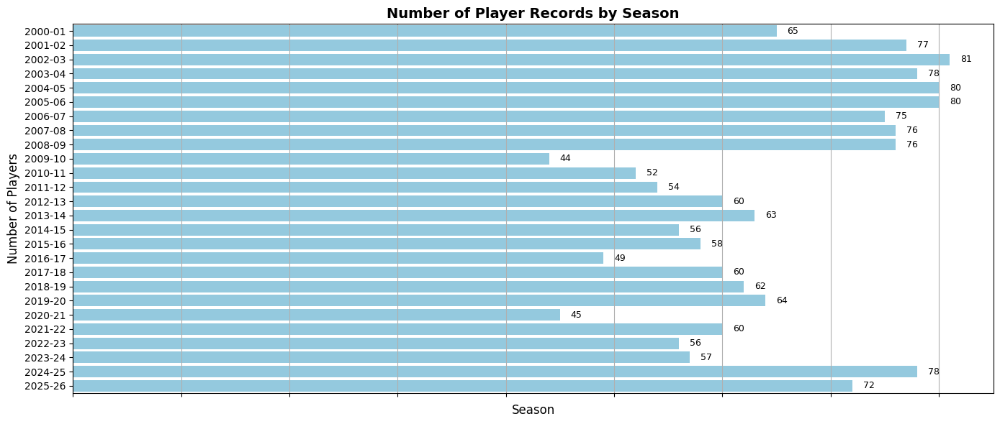

In [257]:
plt.figure(figsize=(14, 6))
ax = sns.countplot(df_wide_view["Season"], color="skyblue", order=sorted(df_wide_view["Season"].unique()))
# Add value labels on top of bars
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{int(width)}",  # label
                (width + 1, p.get_y() + p.get_height() / 2),  # position
                ha='left', va='center', fontsize=9)

# Showing the distribution across seasons
plt.title("Number of Player Records by Season", fontsize=14, weight='bold')
plt.ylabel("Number of Players", fontsize=12)
plt.xlabel("Season", fontsize=12)
ax.yaxis.grid(False)
ax.xaxis.grid(False)
ax.set_xticklabels([])
plt.grid(axis="x")
plt.tight_layout()
plt.savefig(visualization_path / "Season_Distribution_countplot.png")
plt.show()

As observed above, the number of NBA Draft Combine records per season fluctuates rather than following a linear trend. Prior to 2009, participation consistently exceeded 70 players per season, but since then, attendance has varied considerably. This could reflect changes in data collection, combine invitation policies, or shifts in player interest.

To better understand these patterns, let's visualize the trend in combine participation over time using a line graph. This will help us identify periods of high and low attendance and assess the overall trajectory of combine involvement across seasons.

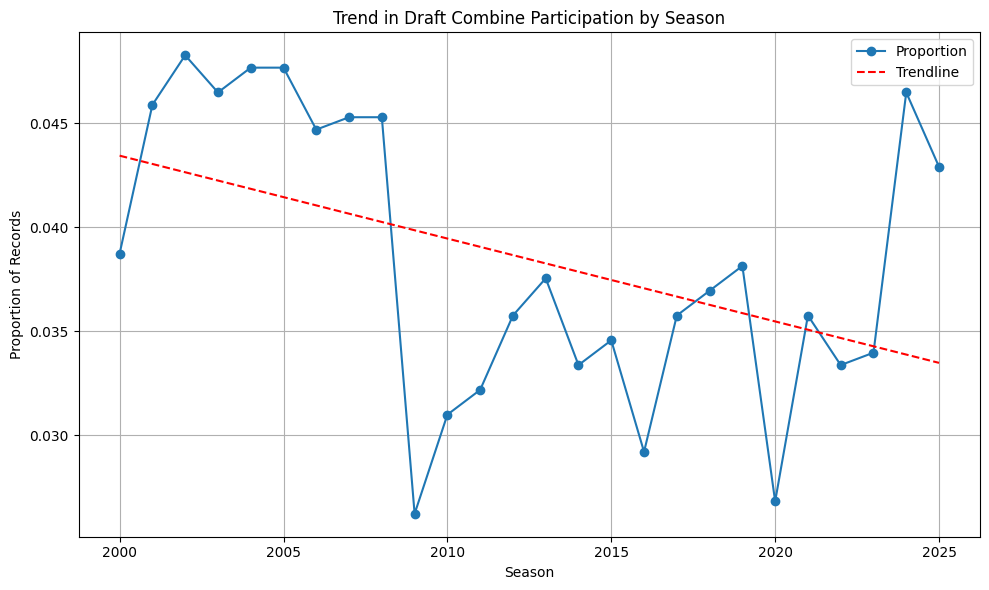

In [184]:
# 1. Get number of total records
total_seasons = len(df_wide_view)

# 2. Compute relative frequency or counts by season (As a record counts as attendance)
avg_attendance = (
    df_wide_view
    .group_by("Season")
    .agg((pl.len() / total_seasons).alias("Proportion"))
    .sort("Season")
)

# 3. Convert season to numeric for trendline
seasons_str = avg_attendance["Season"].to_list()
try:
    seasons = [int(s[:4]) for s in seasons_str]  # Because format "2003-04"
except:
    seasons = list(range(len(seasons_str)))      # fallback

values = avg_attendance["Proportion"].to_list()

# 4. Fit linear regression
coeffs = np.polyfit(seasons, values, 1)
trend = np.poly1d(coeffs)

# 5. Plot
plt.figure(figsize=(10, 6))
plt.plot(seasons, values, marker='o', label="Proportion")
plt.plot(seasons, trend(seasons), linestyle="--", color="red", label="Trendline")

plt.title("Trend in Draft Combine Participation by Season")
plt.xlabel("Season")
plt.ylabel("Proportion of Records")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(visualization_path / "Season_Distribution_lineplot.png")
plt.show()


#### Insights from the Season Distribution Plot

- **Combine Participation is Limited:** The NBA Draft Combine consistently attracts fewer than 100 players per season, with participation rates fluctuating rather than following a clear upward or downward trend.
- **No Linear Trend:** There is no steady increase or decrease in attendance over the years. Instead, some seasons see spikes or drops, likely due to changes in invitation policies, draft class size, or data collection practices.
- **Recent Variability:** In more recent years, attendance appears more variable, suggesting that the combine may be less standardized or that external factors (e.g., league changes, pandemic disruptions) have influenced participation.
- **Implications for Analysis:** The limited and inconsistent coverage means that combine data may not represent all NBA prospects equally. Insights drawn from this dataset should be interpreted with caution, as trends may not generalize to the entire player pool.

Overall, while the combine provides valuable physical and athletic measurements, its selective nature and fluctuating participation highlight the importance of considering sample bias in downstream analysis.

In [185]:
df_wide_view.null_count()

Position,Player,Season,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Bmi,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Weight,Lane_Agility_Time,3_Quarter_Sprint,Length_of_Hand,Height,Wingspan,Width_of_Hand,Length_x_Width_Hand,Shuttle_Run,Body_Fat,Standing_Reach
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,190,190,189,5,604,189,4,5,198,197,733,4,3,733,733,1061,441,5


## Summary of Numerical Features

Below is a summary of the NBA Draft Combine dataset's numerical features. This overview provides key statistics for each metric, including count, mean, standard deviation, minimum, maximum, and quantiles. These statistics help identify the central tendency, spread, and potential outliers for each feature, guiding further data cleaning and analysis.

- **Count:** Number of non-missing values for each feature.
- **Mean & Std:** Average and variability, indicating typical values and dispersion.
- **Min & Max:** Range of observed values, useful for spotting outliers or data entry errors.
- **Quantiles (25%, 50%, 75%):** Distribution percentiles, showing how values are spread.

Features with high missingness (e.g., Shuttle_Run, Length_x_Width_Hand, Length_of_Hand, Width_of_Hand, Max_Bench_Press, Body_Fat) may require imputation or exclusion in downstream analysis. Most features display reasonable means and medians, with some showing skewness or heavy tails.

Use the table below to quickly assess the quality and distribution of each combine metric:


In [186]:
df_wide_view.select(pl.exclude(["Id", "Position", "Season", "Player"])).describe()

statistic,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Bmi,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Weight,Lane_Agility_Time,3_Quarter_Sprint,Length_of_Hand,Height,Wingspan,Width_of_Hand,Length_x_Width_Hand,Shuttle_Run,Body_Fat,Standing_Reach
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1488.0,1488.0,1489.0,1673.0,1074.0,1489.0,1674.0,1673.0,1480.0,1481.0,945.0,1674.0,1675.0,945.0,945.0,617.0,1237.0,1673.0
"""null_count""",190.0,190.0,189.0,5.0,604.0,189.0,4.0,5.0,198.0,197.0,733.0,4.0,3.0,733.0,733.0,1061.0,441.0,5.0
"""mean""",132.6465,137.983337,29.23358,25.003109,10.354749,34.561787,1.060891,214.953674,11.394094,3.266097,8.7291,77.656448,82.377792,9.453016,82.479263,3.060519,0.075306,103.523911
"""std""",4.733643,4.531623,3.099428,2.089067,5.556441,3.687227,0.028591,26.53393,0.582157,0.145154,0.472243,3.352874,3.991217,0.694404,9.324908,0.237889,0.029386,4.849736
"""min""",117.0,121.5,19.5,0.0,0.0,21.0,0.977,0.0,9.65,2.91,7.5,67.75,70.0,7.0,52.5,0.0,0.026,88.5
"""25%""",129.5,135.5,27.0,23.700001,6.0,32.0,1.041,196.199997,11.0,3.18,8.5,75.5,79.75,9.0,76.5,2.98,0.054,100.0
"""50%""",133.0,138.5,29.0,24.9,10.0,34.5,1.061,213.0,11.32,3.26,8.75,78.0,82.5,9.5,81.0,3.06,0.067,104.0
"""75%""",136.0,141.0,31.5,26.200001,14.0,37.0,1.08,232.800003,11.72,3.35,9.0,80.25,85.25,10.0,87.900002,3.19,0.089,107.0
"""max""",146.0,150.5,41.5,34.5,27.0,48.0,1.177,334.0,14.45,4.0,10.5,89.25,98.25,12.0,117.0,3.76,0.231,122.5


## Univariate Analysis

Univariate analysis examines each feature in the NBA Draft Combine dataset individually to understand its distribution, central tendency, spread, and potential outliers. This step is crucial for identifying data quality issues, skewness, and the presence of missing values before proceeding to more complex analyses.

**Key steps in this section:**
- Visualize the distribution of each numerical feature using histograms, boxplots, and QQ plots.
- Calculate summary statistics such as mean, median, standard deviation, skewness, and kurtosis.
- Identify features with high missingness or unusual distributions that may require special handling.
- Highlight outliers and data entry errors (e.g., minimum values of zero in physical measurements).

This foundational analysis provides insights into the typical physical and athletic profiles of NBA prospects, reveals which features are well-behaved, and flags variables that may need cleaning or imputation. The results guide further data preparation and inform downstream modeling and bivariate analysis.

In [ ]:
def univariate_eda(df: pl.DataFrame, columns=None, bins=30):
    """
    Perform univariate analysis on specified numerical columns.
    If columns is None, all numeric columns will be analyzed.
    """
    if columns is None:
        columns = df.select(pl.exclude(pl.String)).columns

    for col in columns:
        print(f"\n--- {col} ---")
        print(df[col].describe())
        print(f"Skewness: {df[col].skew():.2f}")
        print(f"Kurtosis: {df[col].kurtosis():.2f}")
        
        fig, axes = plt.subplots(1, 3, figsize=(18, 4))

        # Histogram + KDE
        sns.histplot(df[col], bins=bins, kde=True, ax=axes[0], color='skyblue')
        axes[0].set_title(f"{col} Distribution")

        # Boxplot
        sns.boxplot(x=df[col], ax=axes[1], color='salmon')
        axes[1].set_title(f"{col} Boxplot")

        # QQ Plot for normality check
        
        probplot(df[col].drop_nulls(), dist="norm", plot=axes[2])
        axes[2].set_title(f"{col} QQ Plot")

        plt.tight_layout()
        temp = visualization_path / f"univariate"
        temp.mkdir(parents=True, exist_ok=True)
        plt.savefig(temp / f"Univariate_{col}.png")
        plt.show()




--- Standing_Reach_Vertical ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 1488.0   │
│ null_count ┆ 190.0    │
│ mean       ┆ 132.6465 │
│ std        ┆ 4.733643 │
│ min        ┆ 117.0    │
│ 25%        ┆ 129.5    │
│ 50%        ┆ 133.0    │
│ 75%        ┆ 136.0    │
│ max        ┆ 146.0    │
└────────────┴──────────┘
Skewness: -0.34
Kurtosis: 0.00


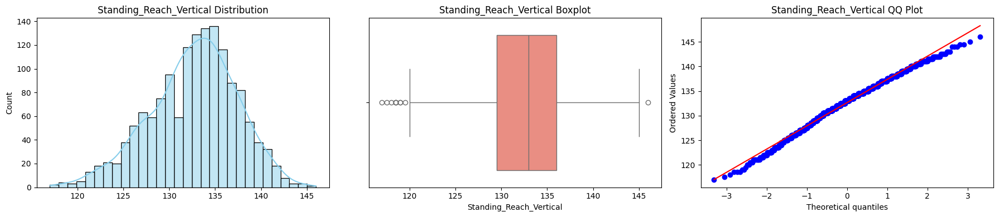


--- Standing_Reach_Max_Vertical ---
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 1488.0     │
│ null_count ┆ 190.0      │
│ mean       ┆ 137.983337 │
│ std        ┆ 4.531623   │
│ min        ┆ 121.5      │
│ 25%        ┆ 135.5      │
│ 50%        ┆ 138.5      │
│ 75%        ┆ 141.0      │
│ max        ┆ 150.5      │
└────────────┴────────────┘
Skewness: -0.47
Kurtosis: 0.38


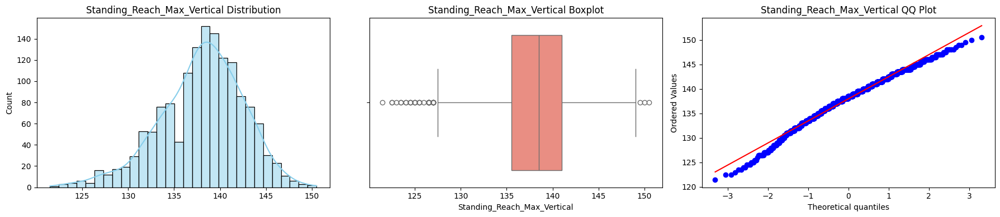


--- Standing_Vertical ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 1489.0   │
│ null_count ┆ 189.0    │
│ mean       ┆ 29.23358 │
│ std        ┆ 3.099428 │
│ min        ┆ 19.5     │
│ 25%        ┆ 27.0     │
│ 50%        ┆ 29.0     │
│ 75%        ┆ 31.5     │
│ max        ┆ 41.5     │
└────────────┴──────────┘
Skewness: 0.11
Kurtosis: 0.04


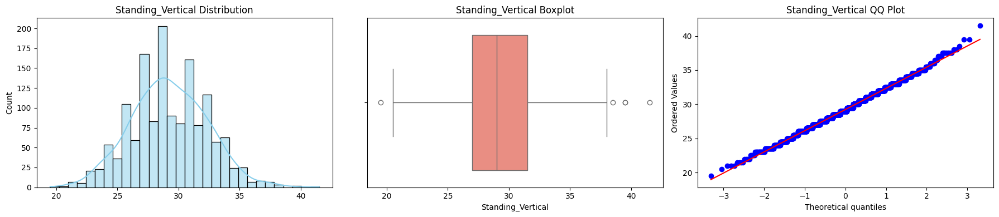


--- Bmi ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 1673.0    │
│ null_count ┆ 5.0       │
│ mean       ┆ 25.003109 │
│ std        ┆ 2.089067  │
│ min        ┆ 0.0       │
│ 25%        ┆ 23.700001 │
│ 50%        ┆ 24.9      │
│ 75%        ┆ 26.200001 │
│ max        ┆ 34.5      │
└────────────┴───────────┘
Skewness: -0.50
Kurtosis: 12.79


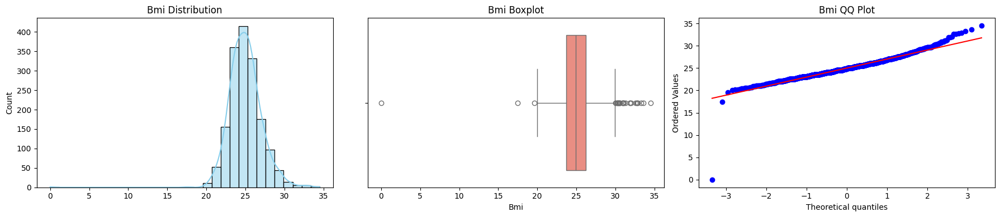


--- Max_Bench_Press ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 1074.0    │
│ null_count ┆ 604.0     │
│ mean       ┆ 10.354749 │
│ std        ┆ 5.556441  │
│ min        ┆ 0.0       │
│ 25%        ┆ 6.0       │
│ 50%        ┆ 10.0      │
│ 75%        ┆ 14.0      │
│ max        ┆ 27.0      │
└────────────┴───────────┘
Skewness: 0.15
Kurtosis: -0.34


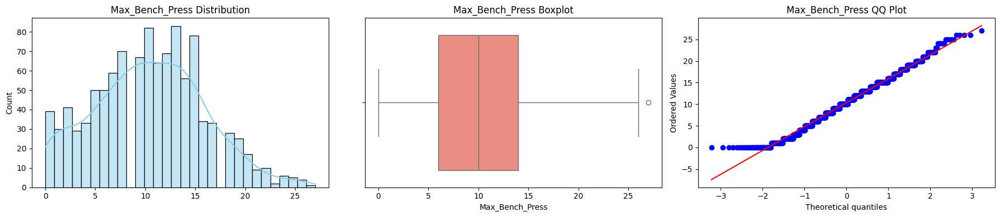


--- Max_Vertical_Leap ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 1489.0    │
│ null_count ┆ 189.0     │
│ mean       ┆ 34.561787 │
│ std        ┆ 3.687227  │
│ min        ┆ 21.0      │
│ 25%        ┆ 32.0      │
│ 50%        ┆ 34.5      │
│ 75%        ┆ 37.0      │
│ max        ┆ 48.0      │
└────────────┴───────────┘
Skewness: 0.04
Kurtosis: -0.09


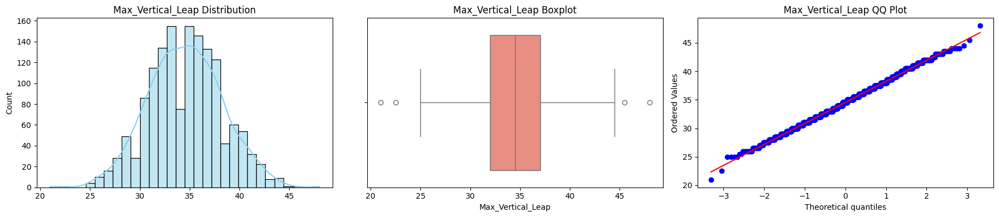


--- Ration_of_Wingspan ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 1674.0   │
│ null_count ┆ 4.0      │
│ mean       ┆ 1.060891 │
│ std        ┆ 0.028591 │
│ min        ┆ 0.977    │
│ 25%        ┆ 1.041    │
│ 50%        ┆ 1.061    │
│ 75%        ┆ 1.08     │
│ max        ┆ 1.177    │
└────────────┴──────────┘
Skewness: -0.03
Kurtosis: -0.24


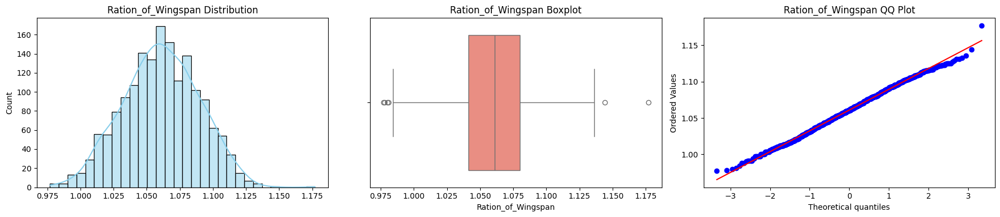


--- Weight ---
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 1673.0     │
│ null_count ┆ 5.0        │
│ mean       ┆ 214.953674 │
│ std        ┆ 26.53393   │
│ min        ┆ 0.0        │
│ 25%        ┆ 196.199997 │
│ 50%        ┆ 213.0      │
│ 75%        ┆ 232.800003 │
│ max        ┆ 334.0      │
└────────────┴────────────┘
Skewness: 0.11
Kurtosis: 2.60


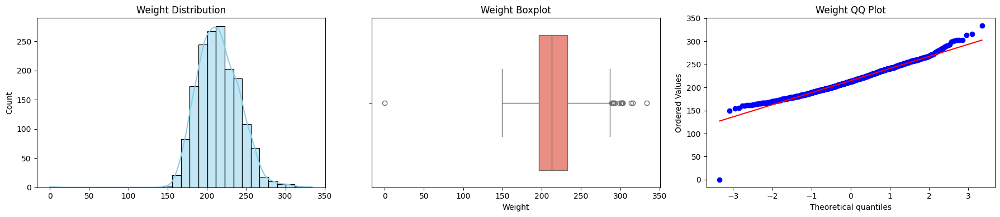


--- Lane_Agility_Time ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 1480.0    │
│ null_count ┆ 198.0     │
│ mean       ┆ 11.394094 │
│ std        ┆ 0.582157  │
│ min        ┆ 9.65      │
│ 25%        ┆ 11.0      │
│ 50%        ┆ 11.32     │
│ 75%        ┆ 11.72     │
│ max        ┆ 14.45     │
└────────────┴───────────┘
Skewness: 0.81
Kurtosis: 1.30


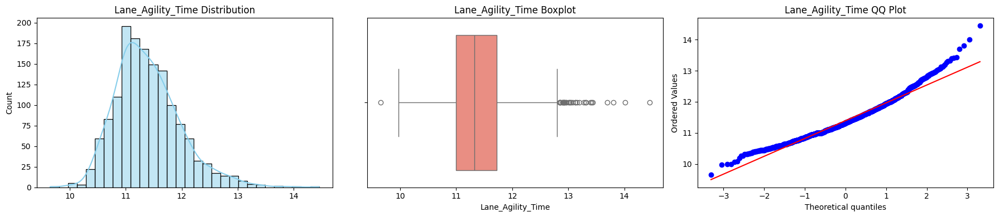


--- 3_Quarter_Sprint ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 1481.0   │
│ null_count ┆ 197.0    │
│ mean       ┆ 3.266097 │
│ std        ┆ 0.145154 │
│ min        ┆ 2.91     │
│ 25%        ┆ 3.18     │
│ 50%        ┆ 3.26     │
│ 75%        ┆ 3.35     │
│ max        ┆ 4.0      │
└────────────┴──────────┘
Skewness: 0.50
Kurtosis: 0.90


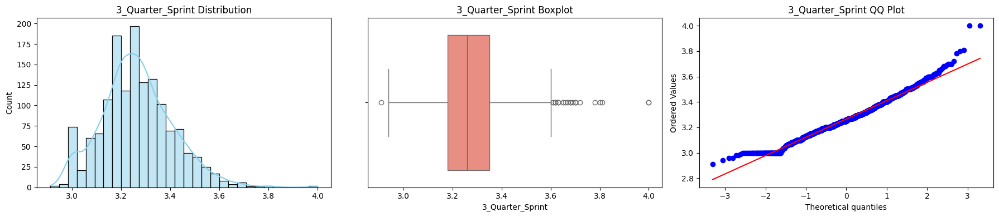


--- Length_of_Hand ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 945.0    │
│ null_count ┆ 733.0    │
│ mean       ┆ 8.7291   │
│ std        ┆ 0.472243 │
│ min        ┆ 7.5      │
│ 25%        ┆ 8.5      │
│ 50%        ┆ 8.75     │
│ 75%        ┆ 9.0      │
│ max        ┆ 10.5     │
└────────────┴──────────┘
Skewness: 0.16
Kurtosis: 0.16


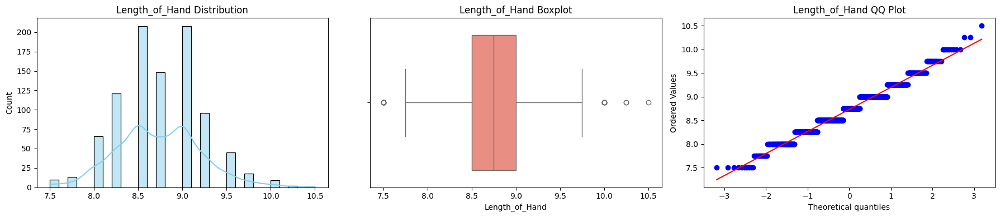


--- Height ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 1674.0    │
│ null_count ┆ 4.0       │
│ mean       ┆ 77.656448 │
│ std        ┆ 3.352874  │
│ min        ┆ 67.75     │
│ 25%        ┆ 75.5      │
│ 50%        ┆ 78.0      │
│ 75%        ┆ 80.25     │
│ max        ┆ 89.25     │
└────────────┴───────────┘
Skewness: -0.19
Kurtosis: -0.27


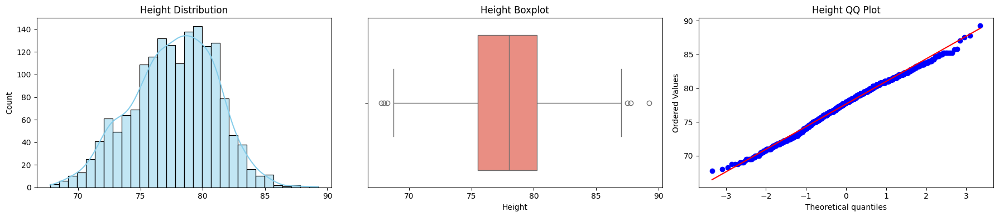


--- Wingspan ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 1675.0    │
│ null_count ┆ 3.0       │
│ mean       ┆ 82.377792 │
│ std        ┆ 3.991217  │
│ min        ┆ 70.0      │
│ 25%        ┆ 79.75     │
│ 50%        ┆ 82.5      │
│ 75%        ┆ 85.25     │
│ max        ┆ 98.25     │
└────────────┴───────────┘
Skewness: -0.19
Kurtosis: -0.08


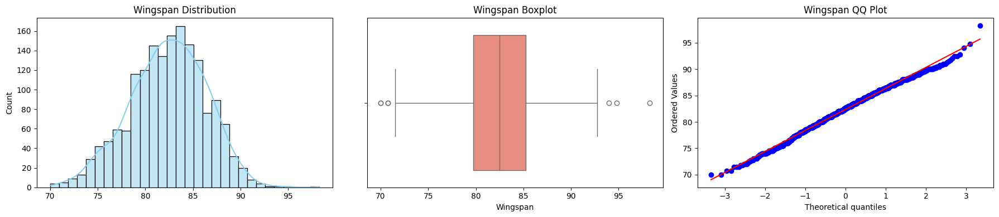


--- Width_of_Hand ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 945.0    │
│ null_count ┆ 733.0    │
│ mean       ┆ 9.453016 │
│ std        ┆ 0.694404 │
│ min        ┆ 7.0      │
│ 25%        ┆ 9.0      │
│ 50%        ┆ 9.5      │
│ 75%        ┆ 10.0     │
│ max        ┆ 12.0     │
└────────────┴──────────┘
Skewness: 0.13
Kurtosis: 0.29


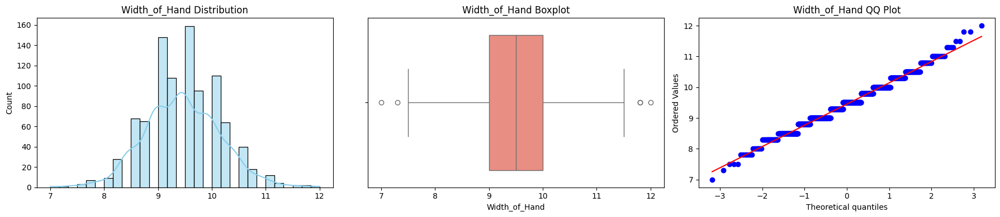


--- Length_x_Width_Hand ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 945.0     │
│ null_count ┆ 733.0     │
│ mean       ┆ 82.479263 │
│ std        ┆ 9.324908  │
│ min        ┆ 52.5      │
│ 25%        ┆ 76.5      │
│ 50%        ┆ 81.0      │
│ 75%        ┆ 87.900002 │
│ max        ┆ 117.0     │
└────────────┴───────────┘
Skewness: 0.40
Kurtosis: 0.40


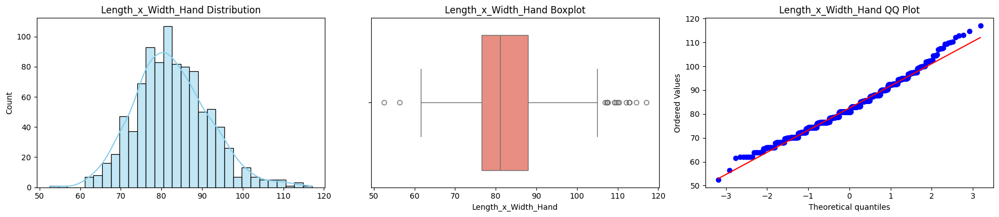


--- Shuttle_Run ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 617.0    │
│ null_count ┆ 1061.0   │
│ mean       ┆ 3.060519 │
│ std        ┆ 0.237889 │
│ min        ┆ 0.0      │
│ 25%        ┆ 2.98     │
│ 50%        ┆ 3.06     │
│ 75%        ┆ 3.19     │
│ max        ┆ 3.76     │
└────────────┴──────────┘
Skewness: -3.70
Kurtosis: 44.05


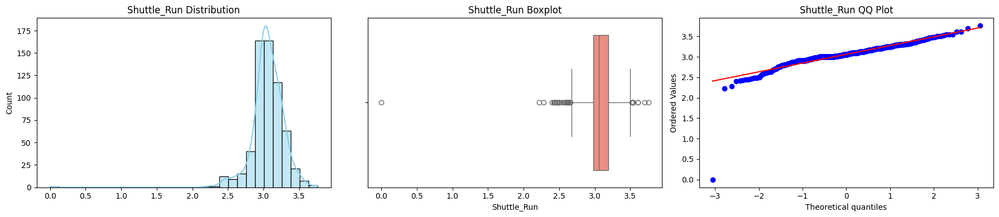


--- Body_Fat ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 1237.0   │
│ null_count ┆ 441.0    │
│ mean       ┆ 0.075306 │
│ std        ┆ 0.029386 │
│ min        ┆ 0.026    │
│ 25%        ┆ 0.054    │
│ 50%        ┆ 0.067    │
│ 75%        ┆ 0.089    │
│ max        ┆ 0.231    │
└────────────┴──────────┘
Skewness: 1.38
Kurtosis: 2.42


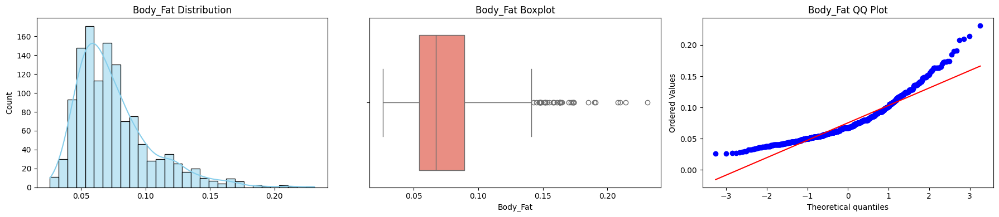


--- Standing_Reach ---
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 1673.0     │
│ null_count ┆ 5.0        │
│ mean       ┆ 103.523911 │
│ std        ┆ 4.849736   │
│ min        ┆ 88.5       │
│ 25%        ┆ 100.0      │
│ 50%        ┆ 104.0      │
│ 75%        ┆ 107.0      │
│ max        ┆ 122.5      │
└────────────┴────────────┘
Skewness: -0.20
Kurtosis: -0.28


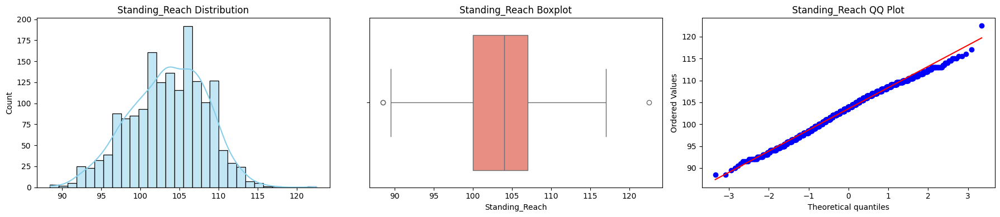

In [188]:
univariate_eda(df_wide_view)

## Univariate EDA Summary

The univariate analysis of this dataset reveals generally clean and well-behaved features, with a few exceptions that merit closer inspection. Most variables have low missingness; however, several require attention due to significant null values. Specifically, `Shuttle_Run` (63% missing), `Length_x_Width_Hand`, `Length_of_Hand`, `Width_of_Hand` (each ~44% missing), and `Max_Bench_Press` (~36% missing) may need imputation or exclusion depending on our analysis goals. `Body_Fat` also shows moderate missingness (~26%).

Many variables display near-normal distributions, including `Standing_Vertical`, `Max_Vertical_Leap`, `Wingspan`, `Height`, `Standing_Reach`, and `Standing_Reach_Vertical`, with skewness and kurtosis values close to zero. Mild right-skew is observed in `Lane_Agility_Time`, `3_Quarter_Sprint`, and `Length_x_Width_Hand`, while `Bmi`, `Standing_Reach_Max_Vertical`, and especially `Shuttle_Run` are left-skewed. `Shuttle_Run` in particular exhibits extreme skewness (−3.70) and kurtosis (44.05), indicating outliers or a long tail. Likewise, `Bmi` shows high kurtosis (12.79), suggesting sharp peaks and heavier tails.

Potential data quality issues are evident in variables like `Bmi`, `Weight`, and `Shuttle_Run`, where minimum values of 0 likely reflect errors or invalid entries. Central tendency metrics are reasonable across most variables, with means and medians closely aligned. For example, `Wingspan` (mean ≈ 82.4 in) and `Height` (mean ≈ 77.7 in) suggest consistent body proportions, further reinforced by the `Ratio_of_Wingspan` (mean ≈ 1.06). Vertical leap metrics (`Standing_Vertical` and `Max_Vertical_Leap`) average 29 and 34.5 inches respectively—values that align with athletic expectations.

Body composition variables highlight a lean cohort, with `Body_Fat` averaging ~7.5% but exhibiting strong right-skewness. `Bmi` centers around 25, the upper limit of the healthy range, but its peaked distribution indicates potential outliers. Strength metrics such as `Max_Bench_Press` show considerable variation (0–27 reps), with a median of 10 reps.

In summary, most features appear statistically robust and well-distributed. A few variables require outlier treatment or missing value handling to ensure high-quality modeling. Attention to these factors will support stronger insights and more reliable downstream analysis.


## Bivariate Analysis

This section explores relationships between numerical features and the two main categorical variables in the dataset: **position** and **season**.

- **Numerical vs. Numerical:**  
    We analyze correlations among all combine metrics to identify which physical and athletic measurements are most strongly related. This includes visualizing the correlation matrix and highlighting the strongest feature pairs.

- **Numerical vs. Categorical:**  
    We examine how each combine statistic varies by player position (PG, SG, SF, PF, C) and by draft season. This involves:
    - Comparing means and distributions of key metrics across positions using barplots, boxplots, and statistical tests (ANOVA, t-tests).
    - Visualizing trends in combine measurements over time to uncover shifts in player profiles or combine participation.

These analyses help reveal which physical and performance traits distinguish player roles, how combine metrics have evolved, and which features are most predictive of NBA success.

### Numerical vs Numerical

In [189]:
df_wide_view

Position,Player,Season,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Bmi,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Weight,Lane_Agility_Time,3_Quarter_Sprint,Length_of_Hand,Height,Wingspan,Width_of_Hand,Length_x_Width_Hand,Shuttle_Run,Body_Fat,Standing_Reach
str,str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""SG""","""Keith Langford""","""2005-06""",133.0,130.5,32.0,25.9,8.0,29.5,1.091,203.199997,11.38,3.23,null,74.25,81.0,null,null,null,null,101.0
"""""","""Matthew Mayer""","""2022-23""",130.5,136.5,25.5,23.799999,null,31.5,1.031,216.399994,10.74,3.39,9.0,80.0,82.5,10.3,92.300003,null,0.111,105.0
"""""","""David Simon""","""2005-06""",136.0,141.0,28.0,28.4,18.0,33.0,1.094,258.799988,11.98,3.44,null,80.0,87.5,null,null,null,null,108.0
"""SF/SG""","""Lance Stephenson""","""2010-11""",130.0,136.0,27.0,27.299999,10.0,33.0,1.078,227.0,11.39,3.38,9.0,76.5,82.5,10.3,92.300003,null,0.093,103.0
"""""","""JR Reynolds""","""2007-08""",122.5,129.5,27.5,25.5,15.0,34.5,1.045,188.0,11.69,3.24,null,72.0,75.25,null,null,null,0.082,95.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""""","""Wendell Moore""","""2022-23""",133.5,139.5,32.5,26.299999,null,38.5,1.108,217.199997,10.94,3.3,8.75,76.25,84.5,10.3,89.699997,3.21,0.075,101.0
"""PG/SG""","""Landry Shamet""","""2018-19""",131.0,139.5,31.0,23.0,8.0,39.5,1.036,188.600006,11.26,3.11,8.0,76.0,78.75,9.0,72.0,3.21,0.049,100.0
"""""","""Gerry McNamara""","""2006-07""",119.5,124.5,27.0,24.200001,3.0,32.0,1.014,177.0,11.28,3.4,null,71.75,72.75,null,null,null,0.128,92.5


In [190]:
corr_matrix = df_wide_view.drop(["Position", "Season", "Player"]).drop_nulls().corr()

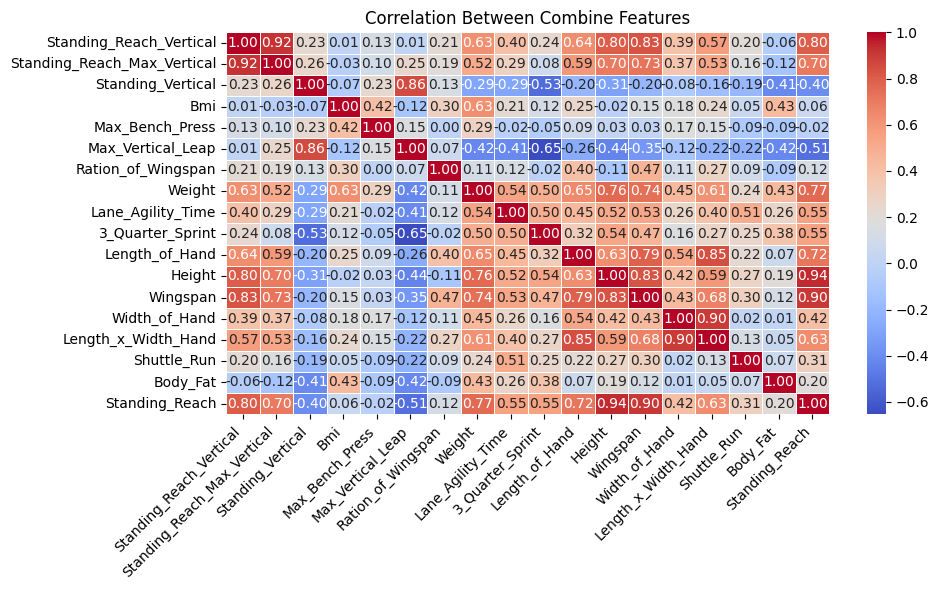

In [191]:
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", 
            cmap="coolwarm", linewidths=0.5,
            xticklabels=corr_matrix.columns,
            yticklabels=corr_matrix.columns
            )

plt.title("Correlation Between Combine Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate"
temp.mkdir(parents=True, exist_ok=True)
plt.savefig(temp / "Correlation_Between_Combine_Features.png")
plt.show()

This is a really nice correlation diagram! However, with so many features, it can be difficult to interpret. To improve readability, we isolate the upper triangle of the correlation matrix and apply an absolute correlation threshold of 0.5. This highlights only the strongest relationships between features, making the diagram much clearer and more actionable for analysis.

In [192]:
corr_matrix

Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Bmi,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Weight,Lane_Agility_Time,3_Quarter_Sprint,Length_of_Hand,Height,Wingspan,Width_of_Hand,Length_x_Width_Hand,Shuttle_Run,Body_Fat,Standing_Reach
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1.0,0.916236,0.22665,0.013464,0.125315,0.012474,0.21386,0.625899,0.399785,0.241524,0.636208,0.799932,0.829261,0.392118,0.571104,0.201596,-0.057473,0.803115
0.916236,1.0,0.261528,-0.034227,0.10391,0.249988,0.193158,0.515381,0.285486,0.077816,0.591962,0.698462,0.728342,0.36857,0.5324,0.162122,-0.122264,0.702892
0.22665,0.261528,1.0,-0.070116,0.228382,0.857786,0.130106,-0.289123,-0.289331,-0.52575,-0.196141,-0.306393,-0.200314,-0.078549,-0.156398,-0.191393,-0.411585,-0.398293
0.013464,-0.034227,-0.070116,1.0,0.416272,-0.116954,0.302583,0.629018,0.214098,0.120104,0.245618,-0.021471,0.151681,0.17711,0.236144,0.049092,0.433167,0.055573
0.125315,0.10391,0.228382,0.416272,1.0,0.15493,0.002754,0.286243,-0.02112,-0.054144,0.08533,0.028066,0.026475,0.17134,0.148969,-0.088647,-0.094382,-0.021695
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.392118,0.36857,-0.078549,0.17711,0.17134,-0.123308,0.106115,0.44633,0.260859,0.163098,0.539861,0.422876,0.433837,1.0,0.902193,0.017005,0.014745,0.417335
0.571104,0.5324,-0.156398,0.236144,0.148969,-0.21988,0.272643,0.61429,0.395929,0.270071,0.848039,0.591862,0.678002,0.902193,1.0,0.126215,0.045924,0.633522
0.201596,0.162122,-0.191393,0.049092,-0.088647,-0.222172,0.094738,0.242534,0.507534,0.251101,0.222428,0.271038,0.297876,0.017005,0.126215,1.0,0.072652,0.30694


In [193]:
# Melt into long format and filter

corr_long = (
    corr_matrix.unpivot(
        variable_name="Feature1",
        value_name="Correlation"
    )
    .with_columns([
        pl.repeat(corr_matrix.columns, corr_matrix.height).explode().alias("Feature2")
    ])
)
corr_filtered = (
    corr_long
    .filter(pl.col("Feature1") != pl.col("Feature2")) # remove self pairs
    .filter(pl.col("Feature1") < pl.col("Feature2")) # locks in on upper triangle
)

corr_final = corr_filtered.with_columns(
    pl.col("Correlation").abs().alias("AbsCorrelation")
)
# Show the top 10 correlated features so we can see the strongest relationships
display(corr_final.sort("AbsCorrelation", descending=True).head(10))

Feature1,Correlation,Feature2,AbsCorrelation
str,f64,str,f64
"""Height""",0.940784,"""Standing_Reach""",0.940784
"""Standing_Reach_Max_Vertical""",0.916236,"""Standing_Reach_Vertical""",0.916236
"""Standing_Reach""",0.903511,"""Wingspan""",0.903511
"""Length_x_Width_Hand""",0.902193,"""Width_of_Hand""",0.902193
"""Max_Vertical_Leap""",0.857786,"""Standing_Vertical""",0.857786
"""Length_of_Hand""",0.848039,"""Length_x_Width_Hand""",0.848039
"""Standing_Reach_Vertical""",0.829261,"""Wingspan""",0.829261
"""Height""",0.826723,"""Wingspan""",0.826723
"""Standing_Reach""",0.803115,"""Standing_Reach_Vertical""",0.803115


Weight,Wingspan,Standing_Reach_Vertical,Standing_Vertical,Standing_Reach,Shuttle_Run,Max_Vertical_Leap,Lane_Agility_Time,Height,Standing_Reach_Max_Vertical,Width_of_Hand,Length_x_Width_Hand,Length_of_Hand
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.625899,0.829261,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
0.515381,0.728342,0.916236,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
0.629018,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
0.0,0.0,0.0,0.857786,-0.512998,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
0.0,0.737763,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


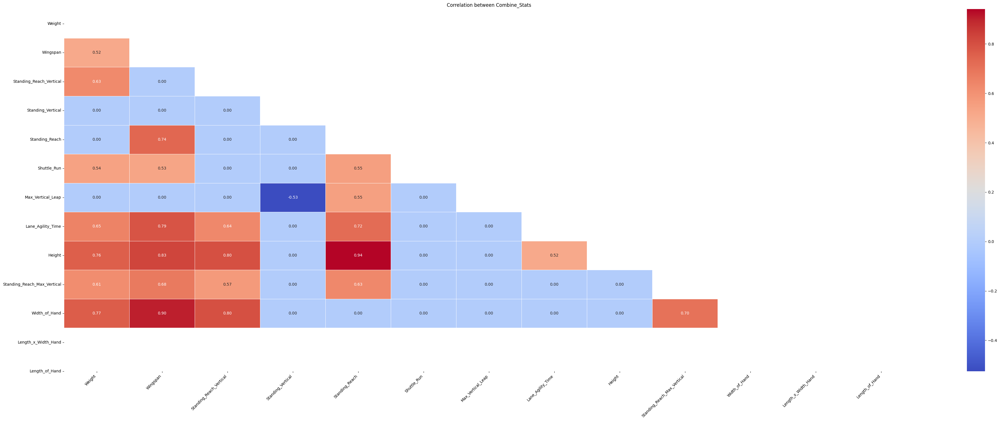

In [194]:

# Absolute value and threshold
top_corr = corr_final.filter(corr_final["AbsCorrelation"] > 0.5)
# Pivot the DataFrame for heatmap
# This will create a matrix where rows are Feature1, columns are Feature2, and values are the correlation coefficients
pivot_corr = top_corr.pivot(index="Feature1", on="Feature2", values="Correlation").drop("Feature1")
pivot_corr = pivot_corr.fill_null(0)
mask = np.triu(np.ones_like(pivot_corr, dtype=bool))
display(pivot_corr.head())
plt.figure(figsize=(40, 15))
sns.heatmap(pivot_corr, annot=True, fmt=".2f", 
            cmap="coolwarm", linewidths=0.5,
            xticklabels=pivot_corr.columns,
            yticklabels=pivot_corr.columns,
            mask=mask
            )

plt.title("Correlation between Combine_Stats")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate"
temp.mkdir(parents=True, exist_ok=True)
plt.savefig(temp / "Correlation_between_Combine_Stats.png")
plt.show()

In [195]:
corr_final.sort("AbsCorrelation", descending=True).head(10)

Feature1,Correlation,Feature2,AbsCorrelation
str,f64,str,f64
"""Height""",0.940784,"""Standing_Reach""",0.940784
"""Standing_Reach_Max_Vertical""",0.916236,"""Standing_Reach_Vertical""",0.916236
"""Standing_Reach""",0.903511,"""Wingspan""",0.903511
"""Length_x_Width_Hand""",0.902193,"""Width_of_Hand""",0.902193
"""Max_Vertical_Leap""",0.857786,"""Standing_Vertical""",0.857786
"""Length_of_Hand""",0.848039,"""Length_x_Width_Hand""",0.848039
"""Standing_Reach_Vertical""",0.829261,"""Wingspan""",0.829261
"""Height""",0.826723,"""Wingspan""",0.826723
"""Standing_Reach""",0.803115,"""Standing_Reach_Vertical""",0.803115


This is insightful! It's fascinating to see how these features interrelate—attributes like height, standing reach, wingspan, and weight are all closely connected. The taller the player, the higher the standing reach and typically the greater the wingspan and weight. These physical traits naturally influence performance metrics such as rebounding and blocking, as confirmed by the strong correlations observed. Understanding these relationships helps explain why certain combine measurements are so predictive of NBA success. Let's continue to explore how these attributes impact player outcomes and career achievements.

Feature1,Correlation,Feature2,AbsCorrelation
str,f64,str,f64
"""Height""",0.940784,"""Standing Reach""",0.940784
"""Standing Reach Max Vertical""",0.916236,"""Standing Reach Vertical""",0.916236
"""Standing Reach""",0.903511,"""Wingspan""",0.903511
"""Length X Width Hand""",0.902193,"""Width Of Hand""",0.902193
"""Max Vertical Leap""",0.857786,"""Standing Vertical""",0.857786
…,…,…,…
"""Length Of Hand""",0.788021,"""Wingspan""",0.788021
"""Standing Reach""",0.76632,"""Weight""",0.76632
"""Height""",0.761868,"""Weight""",0.761868


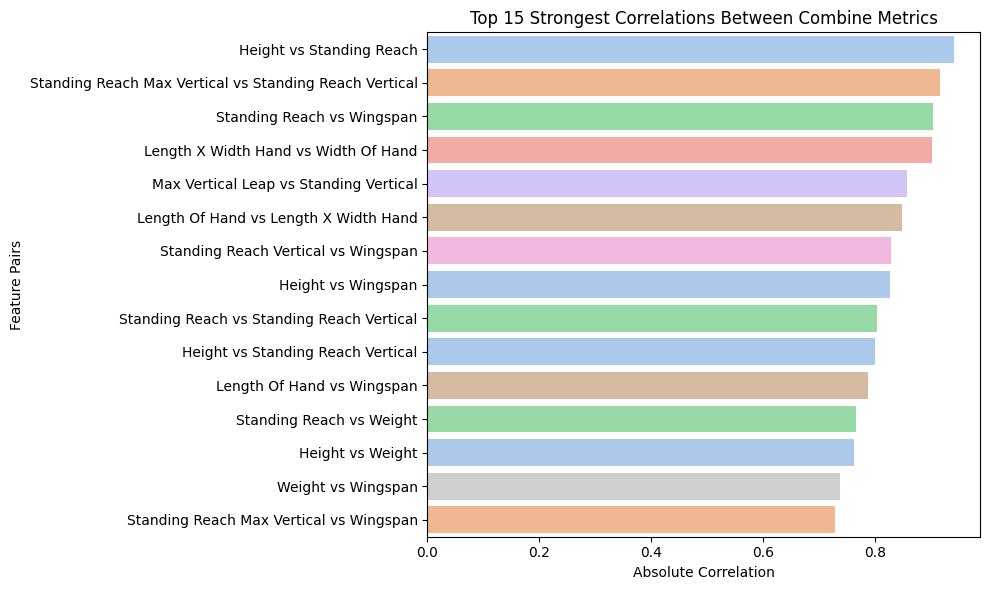

In [196]:
top_corrs = corr_final.sort("AbsCorrelation", descending=True).head(15)

top_corrs = top_corrs.with_columns(
    pl.col("Feature1").str.replace_all("_", " ").str.to_titlecase().alias("Feature1"),
    pl.col("Feature2").str.replace_all("_", " ").str.to_titlecase().alias("Feature2")
)
display(top_corrs)
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_corrs,
    x="AbsCorrelation",
    y=top_corrs["Feature1"] + " vs " + top_corrs["Feature2"],
    palette="pastel",
    hue=top_corrs["Feature1"],
    legend=False
)
plt.title(f"Top {15} Strongest Correlations Between Combine Metrics")
plt.xlabel("Absolute Correlation")
plt.ylabel("Feature Pairs")
plt.tight_layout()
temp = visualization_path / f"bivariate"
temp.mkdir(parents=True, exist_ok=True)
plt.savefig(temp / "Top_15_Strongest_Correlation.png")
plt.show()

In [197]:
df_wide_view

Position,Player,Season,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Bmi,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Weight,Lane_Agility_Time,3_Quarter_Sprint,Length_of_Hand,Height,Wingspan,Width_of_Hand,Length_x_Width_Hand,Shuttle_Run,Body_Fat,Standing_Reach
str,str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""SG""","""Keith Langford""","""2005-06""",133.0,130.5,32.0,25.9,8.0,29.5,1.091,203.199997,11.38,3.23,null,74.25,81.0,null,null,null,null,101.0
"""""","""Matthew Mayer""","""2022-23""",130.5,136.5,25.5,23.799999,null,31.5,1.031,216.399994,10.74,3.39,9.0,80.0,82.5,10.3,92.300003,null,0.111,105.0
"""""","""David Simon""","""2005-06""",136.0,141.0,28.0,28.4,18.0,33.0,1.094,258.799988,11.98,3.44,null,80.0,87.5,null,null,null,null,108.0
"""SF/SG""","""Lance Stephenson""","""2010-11""",130.0,136.0,27.0,27.299999,10.0,33.0,1.078,227.0,11.39,3.38,9.0,76.5,82.5,10.3,92.300003,null,0.093,103.0
"""""","""JR Reynolds""","""2007-08""",122.5,129.5,27.5,25.5,15.0,34.5,1.045,188.0,11.69,3.24,null,72.0,75.25,null,null,null,0.082,95.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""""","""Wendell Moore""","""2022-23""",133.5,139.5,32.5,26.299999,null,38.5,1.108,217.199997,10.94,3.3,8.75,76.25,84.5,10.3,89.699997,3.21,0.075,101.0
"""PG/SG""","""Landry Shamet""","""2018-19""",131.0,139.5,31.0,23.0,8.0,39.5,1.036,188.600006,11.26,3.11,8.0,76.0,78.75,9.0,72.0,3.21,0.049,100.0
"""""","""Gerry McNamara""","""2006-07""",119.5,124.5,27.0,24.200001,3.0,32.0,1.014,177.0,11.28,3.4,null,71.75,72.75,null,null,null,0.128,92.5


In [198]:
# Lets do the numerical to numerical tests:
import sys
sys.path.append(str(Path.cwd().parent.parent))  # Add project root to sys.path

from utils.stat_helper import perform_statistical_tests

numeric_cols = df_wide_view.select(pl.exclude(["Position", "Season", "Player"])).columns


# Perform tests for each pair of columns
results = []
for i in range(len(numeric_cols)):
    for j in range(i + 1, len(numeric_cols)):
        col1 = numeric_cols[i]
        col2 = numeric_cols[j]
        test_results = perform_statistical_tests(df_wide_view, col1, col2)
        results.append({
            "col1": col1,
            "col2": col2,
            **test_results
        })

stat_df = pl.from_dicts(results).sort("p_value_ttest", descending=True).filter((pl.col("p_value_ttest")  < 0.05) & (pl.col("col1") != pl.col("col2")) & ((pl.col("pearson_corr") > 0.5) | (pl.col("pearson_corr") < -0.5)))
display(stat_df)


col1,col2,t_stat,p_value_ttest,u_stat,p_value_mannwhitney,pearson_corr
str,str,f64,f64,f64,f64,f64
"""Height""","""Length_x_Width_Hand""",-14.939446,2.7404e-46,287110.0,7.8295e-41,0.554747
"""Length_of_Hand""","""Width_of_Hand""",-26.499931,2.2094e-129,166484.5,9.4676e-125,0.541559
"""Standing_Reach_Vertical""","""Standing_Reach_Max_Vertical""",-31.374482,7.8882e-187,448223.0,3.7012e-173,0.909159
"""Height""","""Wingspan""",-37.03847,7.9551e-251,515141.5,2.3889e-220,0.831728
"""Standing_Vertical""","""Max_Vertical_Leap""",-42.648548,1.1722e-308,297805.0,3.8119e-261,0.843192
…,…,…,…,…,…,…
"""Length_of_Hand""","""Standing_Reach""",-615.545802,0.0,0.0,0.0,0.638143
"""Height""","""Standing_Reach""",-179.492159,0.0,2.0,0.0,0.919512
"""Wingspan""","""Standing_Reach""",-137.874215,0.0,678.0,0.0,0.899459


### Insights from Statistical Tests on NBA Draft Combine Metrics

- **Strong Feature Relationships:** Many combine metrics show statistically significant relationships, confirmed by extremely low p-values in both t-tests and Mann-Whitney tests. For example, Height and Weight (p ≈ 0), Standing Reach and Wingspan (p ≈ 0), and Length_x_Width_Hand and Width_of_Hand (p ≈ 0) are highly correlated, reflecting underlying physical connections.

- **Physical Traits Cluster Together:** Features related to size—Height, Weight, Wingspan, Standing Reach—consistently exhibit strong positive correlations (Pearson r > 0.7). This means taller players tend to have longer wingspans, greater reach, and higher body mass.

- **Performance Metrics Interlinked:** Athletic performance stats such as Max Vertical Leap and Standing Vertical are tightly coupled (r ≈ 0.85), indicating that explosive leaping ability is captured by multiple combine measures.

- **Hand Measurements:** Length_x_Width_Hand, Width_of_Hand, and Length_of_Hand are all strongly correlated (r > 0.8), suggesting that players with larger hands tend to score high across all hand-related metrics.

- **Agility and Speed:** Lane Agility Time and 3_Quarter_Sprint show moderate correlations with other physical metrics, but less so with size-related features, highlighting their distinct measurement of quickness and speed.

- **Statistically Significant Differences:** Nearly all tested feature pairs with p-values < 0.05 indicate meaningful differences or associations, supporting the reliability of combine metrics for distinguishing player physical profiles.

- **Implications for Scouting:** The strongest statistical relationships reinforce the value of combine measurements in predicting player archetypes and potential NBA performance, especially for positions requiring size and athleticism.

These results validate the use of NBA Draft Combine data for player evaluation, modeling, and understanding how physical attributes translate to on-court success.

In [199]:
df_wide_view.columns

['Position',
 'Player',
 'Season',
 'Standing_Reach_Vertical',
 'Standing_Reach_Max_Vertical',
 'Standing_Vertical',
 'Bmi',
 'Max_Bench_Press',
 'Max_Vertical_Leap',
 'Ration_of_Wingspan',
 'Weight',
 'Lane_Agility_Time',
 '3_Quarter_Sprint',
 'Length_of_Hand',
 'Height',
 'Wingspan',
 'Width_of_Hand',
 'Length_x_Width_Hand',
 'Shuttle_Run',
 'Body_Fat',
 'Standing_Reach']

### Categorical vs Numerical

In this section, we compare NBA Draft Combine statistics against categorical variables such as player position and season. By visualizing how physical and performance metrics vary across positions (PG, SG, SF, PF, C) and over different draft years, we can uncover patterns and trends in player attributes and combine results.

**Key analyses include:**
- Bar plots and error bars showing the mean and standard deviation of combine stats by position.
- Facet and line plots illustrating how combine metrics change across seasons.
- Boxplots and pairplots to highlight differences in combine stats for award recipients (e.g., All-Star, All-NBA Team, Defensive Team) versus non-recipients.

These visualizations help reveal which physical traits are most common for each position, how combine results have evolved over time, and whether standout measurements are associated with NBA accolades. This bivariate analysis provides actionable insights for scouting, player development, and understanding the impact of physical attributes on career outcomes.

In [200]:
df_wide_view_positions = df_wide_view.with_columns(
    pl.when(pl.col("Position").str.contains("/", literal=True))
    .then(pl.col("Position").str.split("/"))
    .otherwise(pl.col("Position").map_elements(lambda x: [x], return_dtype=pl.List(pl.String)))
    .replace("", None)
    .alias("Position")
).explode("Position")
df_wide_view_positions

Position,Player,Season,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Bmi,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Weight,Lane_Agility_Time,3_Quarter_Sprint,Length_of_Hand,Height,Wingspan,Width_of_Hand,Length_x_Width_Hand,Shuttle_Run,Body_Fat,Standing_Reach
str,str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""SG""","""Keith Langford""","""2005-06""",133.0,130.5,32.0,25.9,8.0,29.5,1.091,203.199997,11.38,3.23,null,74.25,81.0,null,null,null,null,101.0
null,"""Matthew Mayer""","""2022-23""",130.5,136.5,25.5,23.799999,null,31.5,1.031,216.399994,10.74,3.39,9.0,80.0,82.5,10.3,92.300003,null,0.111,105.0
null,"""David Simon""","""2005-06""",136.0,141.0,28.0,28.4,18.0,33.0,1.094,258.799988,11.98,3.44,null,80.0,87.5,null,null,null,null,108.0
"""SF""","""Lance Stephenson""","""2010-11""",130.0,136.0,27.0,27.299999,10.0,33.0,1.078,227.0,11.39,3.38,9.0,76.5,82.5,10.3,92.300003,null,0.093,103.0
"""SG""","""Lance Stephenson""","""2010-11""",130.0,136.0,27.0,27.299999,10.0,33.0,1.078,227.0,11.39,3.38,9.0,76.5,82.5,10.3,92.300003,null,0.093,103.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""SG""","""Landry Shamet""","""2018-19""",131.0,139.5,31.0,23.0,8.0,39.5,1.036,188.600006,11.26,3.11,8.0,76.0,78.75,9.0,72.0,3.21,0.049,100.0
null,"""Gerry McNamara""","""2006-07""",119.5,124.5,27.0,24.200001,3.0,32.0,1.014,177.0,11.28,3.4,null,71.75,72.75,null,null,null,0.128,92.5
"""C""","""Walker Kessler""","""2022-23""",null,null,null,25.4,null,null,1.047,256.0,null,null,8.5,84.25,88.25,8.5,72.300003,null,0.147,113.0


In [201]:
df_wide_view_positions.null_count()

Position,Player,Season,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Bmi,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Weight,Lane_Agility_Time,3_Quarter_Sprint,Length_of_Hand,Height,Wingspan,Width_of_Hand,Length_x_Width_Hand,Shuttle_Run,Body_Fat,Standing_Reach
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
543,0,0,248,249,247,5,737,248,4,5,260,258,941,4,3,941,941,1375,503,5


There are 543 null values in the `Position` column, indicating that these players either did not get drafted or did not play in the NBA. This missingness highlights the distinction between combine participants who made it to the league and those who did not, and is important to consider in downstream analyses.

In [202]:
undrafted_no_nba_df = df_wide_view_positions.filter(pl.col("Position").is_null())
df_wide_view_positions = df_wide_view_positions.drop_nulls("Position")

In [203]:
numeric_cols = df_wide_view_positions.select([pl.col(pl.Float32), pl.col(pl.Float64), pl.col(pl.Int64)]).columns

df_summary = df_wide_view_positions.group_by("Position").agg(
    [
        *(pl.col(col).mean().alias(f"{col}_mean") for col in numeric_cols),
        *(pl.col(col).std().alias(f"{col}_std") for col in numeric_cols)
    ]
)
df_summary

Position,Standing_Reach_Vertical_mean,Standing_Reach_Max_Vertical_mean,Standing_Vertical_mean,Bmi_mean,Max_Bench_Press_mean,Max_Vertical_Leap_mean,Ration_of_Wingspan_mean,Weight_mean,Lane_Agility_Time_mean,3_Quarter_Sprint_mean,Length_of_Hand_mean,Height_mean,Wingspan_mean,Width_of_Hand_mean,Length_x_Width_Hand_mean,Shuttle_Run_mean,Body_Fat_mean,Standing_Reach_mean,Standing_Reach_Vertical_std,Standing_Reach_Max_Vertical_std,Standing_Vertical_std,Bmi_std,Max_Bench_Press_std,Max_Vertical_Leap_std,Ration_of_Wingspan_std,Weight_std,Lane_Agility_Time_std,3_Quarter_Sprint_std,Length_of_Hand_std,Height_std,Wingspan_std,Width_of_Hand_std,Length_x_Width_Hand_std,Shuttle_Run_std,Body_Fat_std,Standing_Reach_std
str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""SF""",133.972031,139.547745,30.088425,24.797955,10.283898,35.664516,1.062642,214.393066,11.277265,3.248474,8.752315,77.985283,82.856422,9.409267,82.202751,3.082609,0.067588,103.927406,2.944841,3.168736,2.849911,1.798122,5.194096,3.341225,0.027323,15.188764,0.472817,0.117179,0.376637,1.472926,2.20706,0.617728,7.808844,0.174834,0.021223,2.446338
"""PF""",135.875534,140.792328,29.363914,25.510836,11.371542,34.273006,1.065312,230.881668,11.450554,3.299784,8.973176,79.799202,84.994591,9.711597,87.096138,3.115858,0.077416,106.668297,3.123149,3.176418,2.889952,2.06159,5.468189,3.098984,0.027859,17.346436,0.488786,0.124093,0.38852,1.635164,2.302653,0.67772,8.50385,0.197338,0.027044,2.622063
"""PG""",128.044357,134.289078,30.185354,24.56642,8.4153,36.418068,1.062842,189.295898,11.022996,3.197471,8.348266,73.614204,78.233398,9.081508,75.654305,3.016923,0.062449,97.974541,3.515159,3.753733,2.840714,2.296232,4.940546,3.371294,0.027744,18.845734,0.420151,0.101282,0.382802,2.076422,2.764105,0.557094,6.682992,0.231105,0.020696,3.193079
"""SG""",131.072052,137.068497,29.989862,24.496414,9.072519,35.986301,1.061756,200.966492,11.139034,3.227253,8.540798,75.949295,80.62912,9.219108,78.623276,3.040513,0.064493,101.121246,3.525728,3.719856,2.862582,1.703393,5.009425,3.326728,0.027473,15.281934,0.441489,0.122121,0.366655,1.888225,2.603145,0.58941,7.012119,0.296474,0.019594,2.941894
"""C""",137.264328,141.703293,28.401409,25.669384,11.389221,32.840374,1.065041,241.795898,11.767265,3.348113,9.134482,81.414703,86.691864,9.835177,89.703407,3.142728,0.08562,109.020821,3.097404,3.11311,3.142398,2.248242,4.996204,3.381814,0.029333,19.976648,0.560862,0.149306,0.406139,1.839901,2.440395,0.690162,8.515203,0.205984,0.034372,2.744162


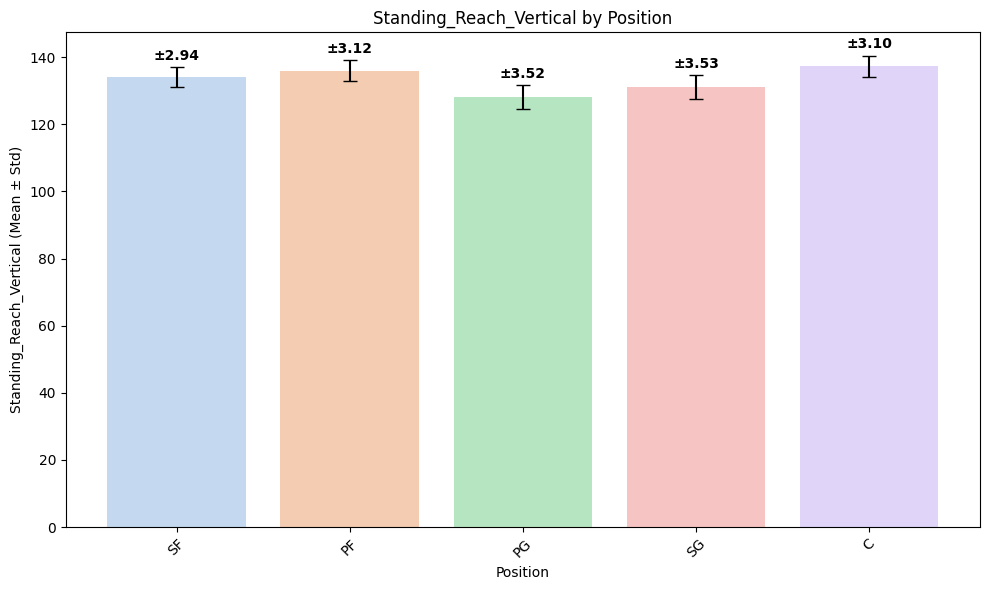

shape: (5, 3)
┌──────────┬──────────────────────────────┬─────────────────────────────┐
│ Position ┆ Standing_Reach_Vertical_mean ┆ Standing_Reach_Vertical_std │
│ ---      ┆ ---                          ┆ ---                         │
│ str      ┆ f32                          ┆ f32                         │
╞══════════╪══════════════════════════════╪═════════════════════════════╡
│ SF       ┆ 133.972031                   ┆ 2.944841                    │
│ PF       ┆ 135.875534                   ┆ 3.123149                    │
│ PG       ┆ 128.044357                   ┆ 3.515159                    │
│ SG       ┆ 131.072052                   ┆ 3.525728                    │
│ C        ┆ 137.264328                   ┆ 3.097404                    │
└──────────┴──────────────────────────────┴─────────────────────────────┘


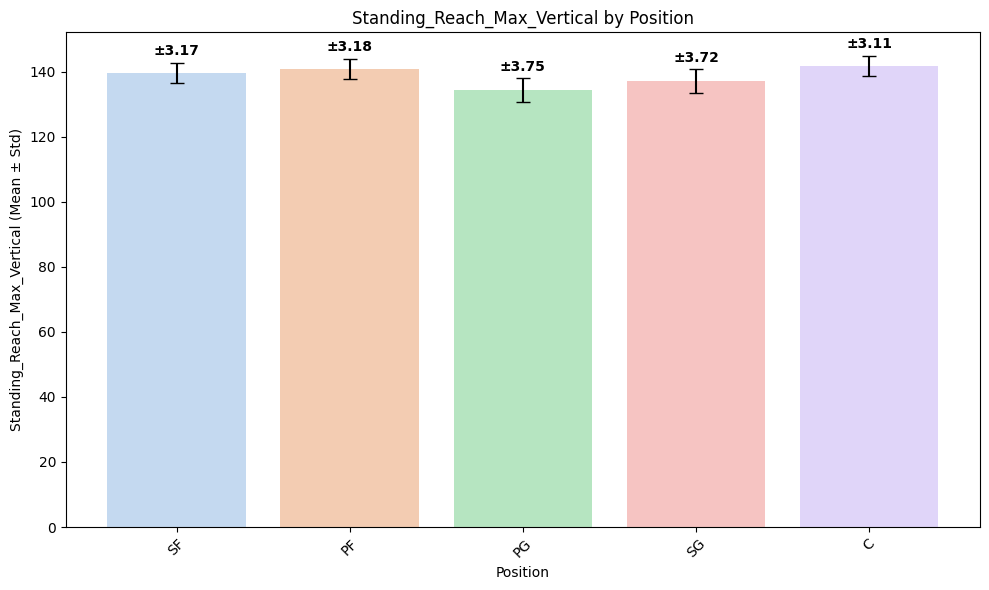

shape: (5, 3)
┌──────────┬─────────────────────────────────┬─────────────────────────────────┐
│ Position ┆ Standing_Reach_Max_Vertical_me… ┆ Standing_Reach_Max_Vertical_st… │
│ ---      ┆ ---                             ┆ ---                             │
│ str      ┆ f32                             ┆ f32                             │
╞══════════╪═════════════════════════════════╪═════════════════════════════════╡
│ SF       ┆ 139.547745                      ┆ 3.168736                        │
│ PF       ┆ 140.792328                      ┆ 3.176418                        │
│ PG       ┆ 134.289078                      ┆ 3.753733                        │
│ SG       ┆ 137.068497                      ┆ 3.719856                        │
│ C        ┆ 141.703293                      ┆ 3.11311                         │
└──────────┴─────────────────────────────────┴─────────────────────────────────┘


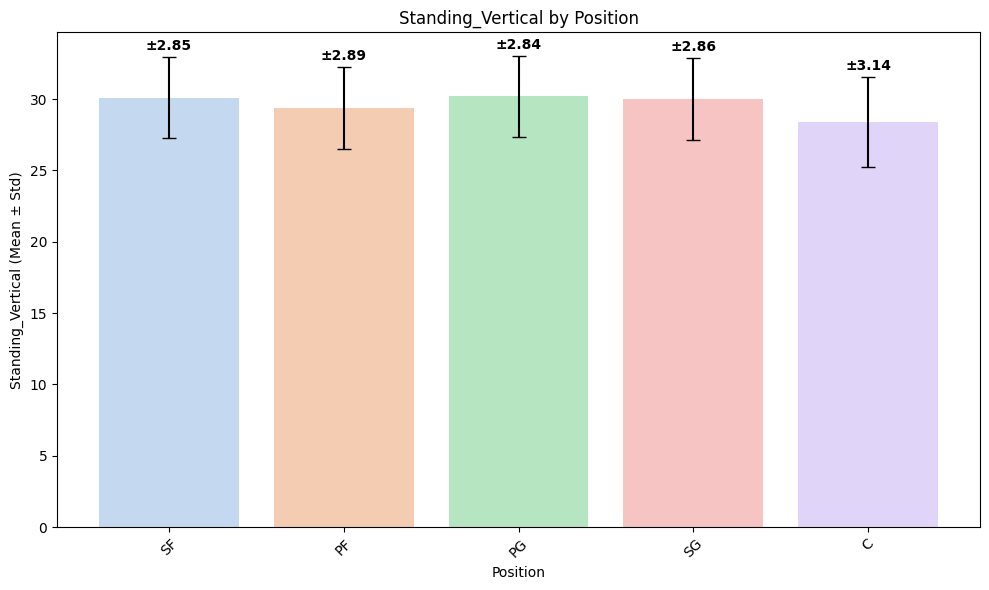

shape: (5, 3)
┌──────────┬────────────────────────┬───────────────────────┐
│ Position ┆ Standing_Vertical_mean ┆ Standing_Vertical_std │
│ ---      ┆ ---                    ┆ ---                   │
│ str      ┆ f32                    ┆ f32                   │
╞══════════╪════════════════════════╪═══════════════════════╡
│ SF       ┆ 30.088425              ┆ 2.849911              │
│ PF       ┆ 29.363914              ┆ 2.889952              │
│ PG       ┆ 30.185354              ┆ 2.840714              │
│ SG       ┆ 29.989862              ┆ 2.862582              │
│ C        ┆ 28.401409              ┆ 3.142398              │
└──────────┴────────────────────────┴───────────────────────┘


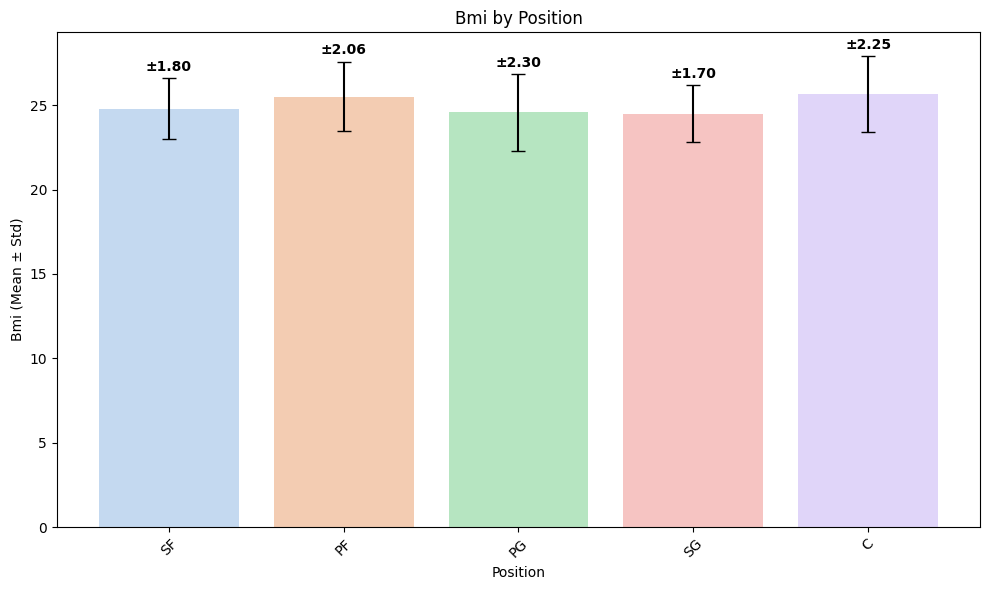

shape: (5, 3)
┌──────────┬───────────┬──────────┐
│ Position ┆ Bmi_mean  ┆ Bmi_std  │
│ ---      ┆ ---       ┆ ---      │
│ str      ┆ f32       ┆ f32      │
╞══════════╪═══════════╪══════════╡
│ SF       ┆ 24.797955 ┆ 1.798122 │
│ PF       ┆ 25.510836 ┆ 2.06159  │
│ PG       ┆ 24.56642  ┆ 2.296232 │
│ SG       ┆ 24.496414 ┆ 1.703393 │
│ C        ┆ 25.669384 ┆ 2.248242 │
└──────────┴───────────┴──────────┘


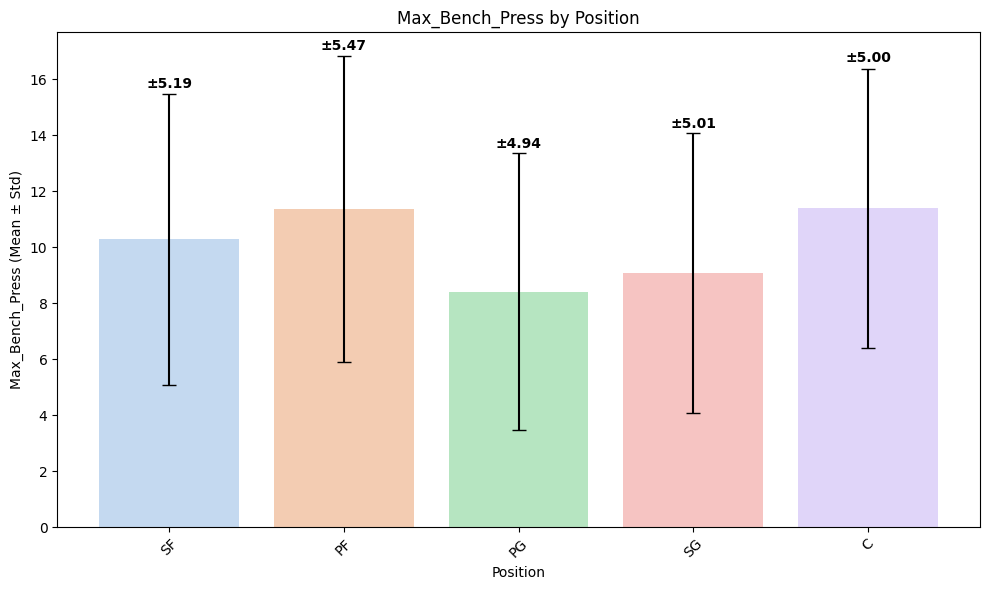

shape: (5, 3)
┌──────────┬──────────────────────┬─────────────────────┐
│ Position ┆ Max_Bench_Press_mean ┆ Max_Bench_Press_std │
│ ---      ┆ ---                  ┆ ---                 │
│ str      ┆ f32                  ┆ f32                 │
╞══════════╪══════════════════════╪═════════════════════╡
│ SF       ┆ 10.283898            ┆ 5.194096            │
│ PF       ┆ 11.371542            ┆ 5.468189            │
│ PG       ┆ 8.4153               ┆ 4.940546            │
│ SG       ┆ 9.072519             ┆ 5.009425            │
│ C        ┆ 11.389221            ┆ 4.996204            │
└──────────┴──────────────────────┴─────────────────────┘


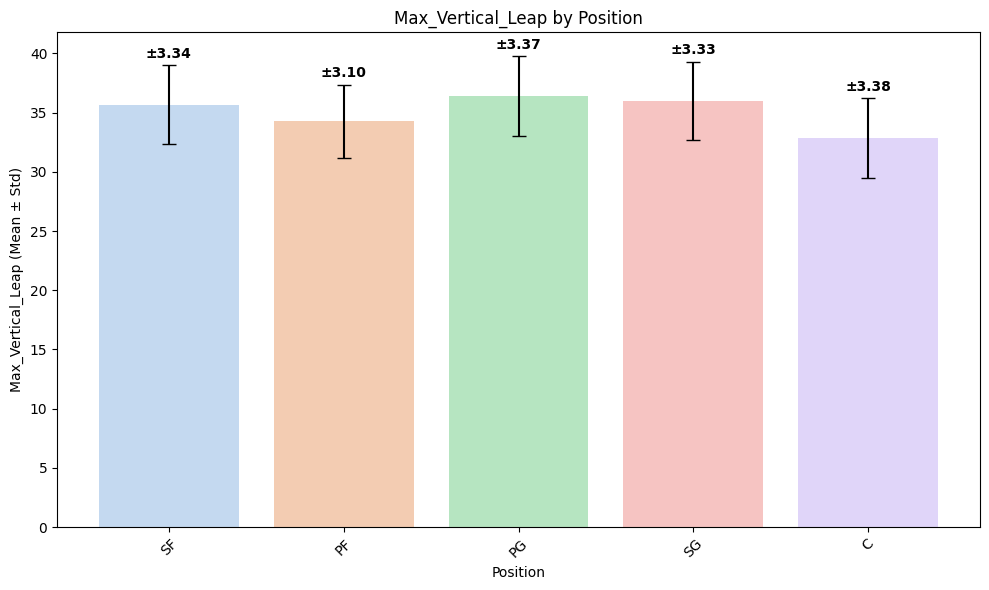

shape: (5, 3)
┌──────────┬────────────────────────┬───────────────────────┐
│ Position ┆ Max_Vertical_Leap_mean ┆ Max_Vertical_Leap_std │
│ ---      ┆ ---                    ┆ ---                   │
│ str      ┆ f32                    ┆ f32                   │
╞══════════╪════════════════════════╪═══════════════════════╡
│ SF       ┆ 35.664516              ┆ 3.341225              │
│ PF       ┆ 34.273006              ┆ 3.098984              │
│ PG       ┆ 36.418068              ┆ 3.371294              │
│ SG       ┆ 35.986301              ┆ 3.326728              │
│ C        ┆ 32.840374              ┆ 3.381814              │
└──────────┴────────────────────────┴───────────────────────┘


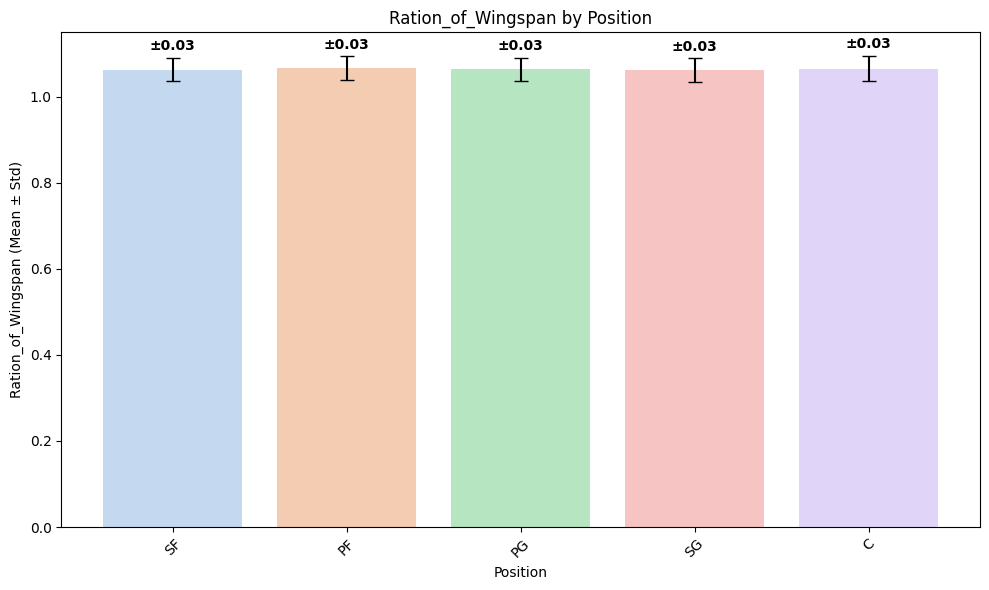

shape: (5, 3)
┌──────────┬─────────────────────────┬────────────────────────┐
│ Position ┆ Ration_of_Wingspan_mean ┆ Ration_of_Wingspan_std │
│ ---      ┆ ---                     ┆ ---                    │
│ str      ┆ f32                     ┆ f32                    │
╞══════════╪═════════════════════════╪════════════════════════╡
│ SF       ┆ 1.062642                ┆ 0.027323               │
│ PF       ┆ 1.065312                ┆ 0.027859               │
│ PG       ┆ 1.062842                ┆ 0.027744               │
│ SG       ┆ 1.061756                ┆ 0.027473               │
│ C        ┆ 1.065041                ┆ 0.029333               │
└──────────┴─────────────────────────┴────────────────────────┘


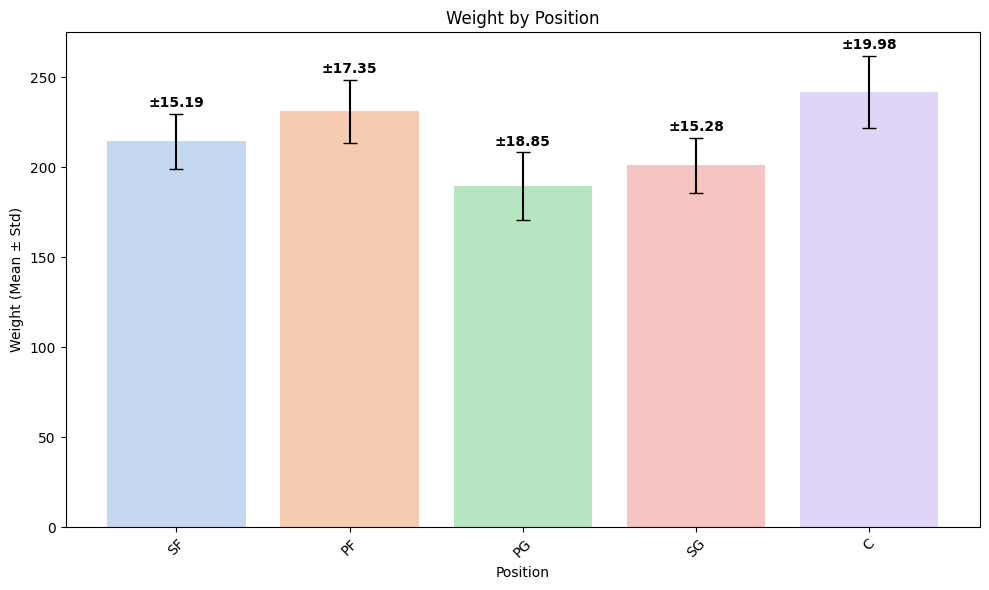

shape: (5, 3)
┌──────────┬─────────────┬────────────┐
│ Position ┆ Weight_mean ┆ Weight_std │
│ ---      ┆ ---         ┆ ---        │
│ str      ┆ f32         ┆ f32        │
╞══════════╪═════════════╪════════════╡
│ SF       ┆ 214.393066  ┆ 15.188764  │
│ PF       ┆ 230.881668  ┆ 17.346436  │
│ PG       ┆ 189.295898  ┆ 18.845734  │
│ SG       ┆ 200.966492  ┆ 15.281934  │
│ C        ┆ 241.795898  ┆ 19.976648  │
└──────────┴─────────────┴────────────┘


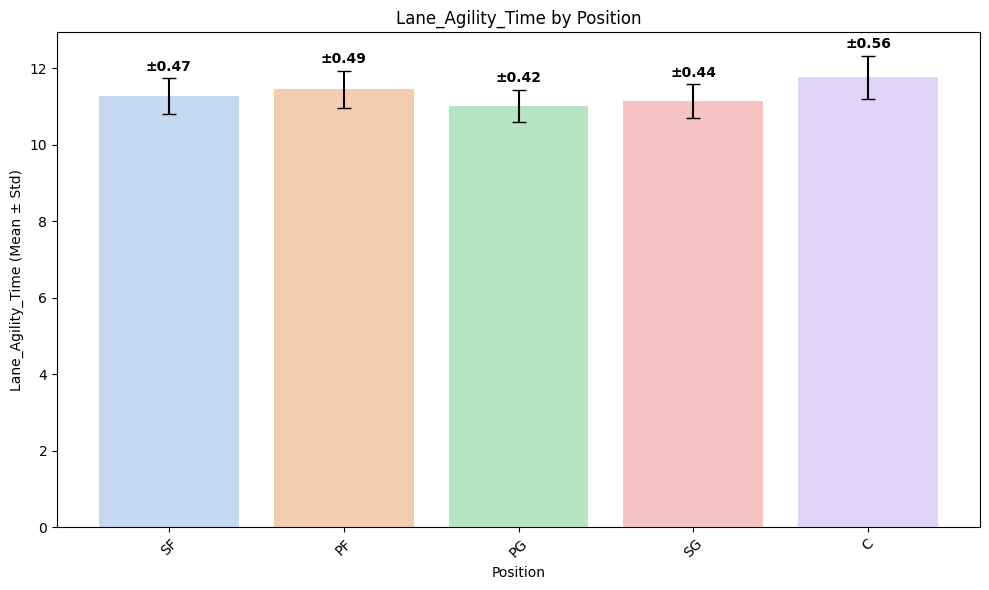

shape: (5, 3)
┌──────────┬────────────────────────┬───────────────────────┐
│ Position ┆ Lane_Agility_Time_mean ┆ Lane_Agility_Time_std │
│ ---      ┆ ---                    ┆ ---                   │
│ str      ┆ f32                    ┆ f32                   │
╞══════════╪════════════════════════╪═══════════════════════╡
│ SF       ┆ 11.277265              ┆ 0.472817              │
│ PF       ┆ 11.450554              ┆ 0.488786              │
│ PG       ┆ 11.022996              ┆ 0.420151              │
│ SG       ┆ 11.139034              ┆ 0.441489              │
│ C        ┆ 11.767265              ┆ 0.560862              │
└──────────┴────────────────────────┴───────────────────────┘


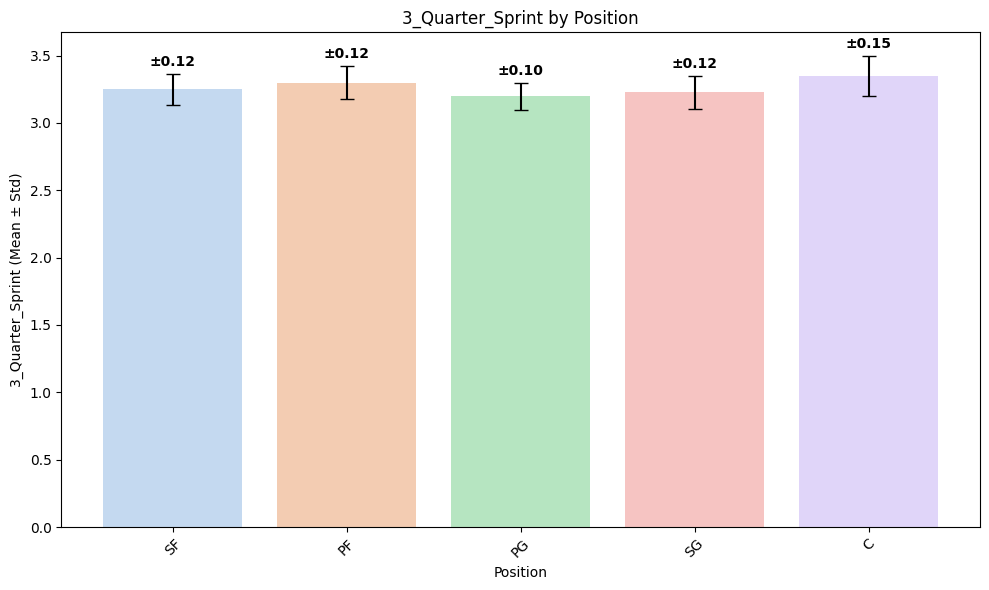

shape: (5, 3)
┌──────────┬───────────────────────┬──────────────────────┐
│ Position ┆ 3_Quarter_Sprint_mean ┆ 3_Quarter_Sprint_std │
│ ---      ┆ ---                   ┆ ---                  │
│ str      ┆ f32                   ┆ f32                  │
╞══════════╪═══════════════════════╪══════════════════════╡
│ SF       ┆ 3.248474              ┆ 0.117179             │
│ PF       ┆ 3.299784              ┆ 0.124093             │
│ PG       ┆ 3.197471              ┆ 0.101282             │
│ SG       ┆ 3.227253              ┆ 0.122121             │
│ C        ┆ 3.348113              ┆ 0.149306             │
└──────────┴───────────────────────┴──────────────────────┘


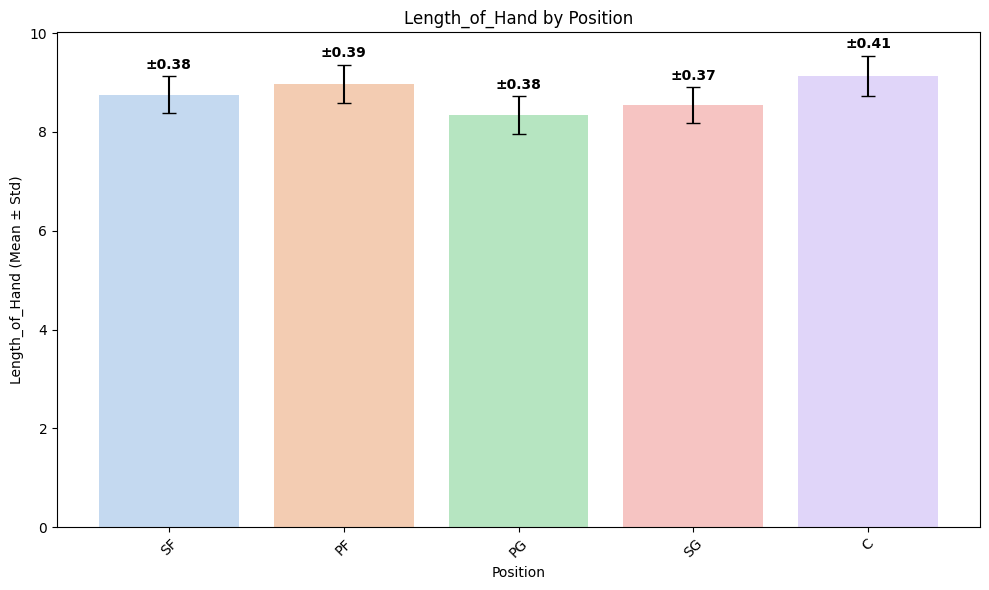

shape: (5, 3)
┌──────────┬─────────────────────┬────────────────────┐
│ Position ┆ Length_of_Hand_mean ┆ Length_of_Hand_std │
│ ---      ┆ ---                 ┆ ---                │
│ str      ┆ f32                 ┆ f32                │
╞══════════╪═════════════════════╪════════════════════╡
│ SF       ┆ 8.752315            ┆ 0.376637           │
│ PF       ┆ 8.973176            ┆ 0.38852            │
│ PG       ┆ 8.348266            ┆ 0.382802           │
│ SG       ┆ 8.540798            ┆ 0.366655           │
│ C        ┆ 9.134482            ┆ 0.406139           │
└──────────┴─────────────────────┴────────────────────┘


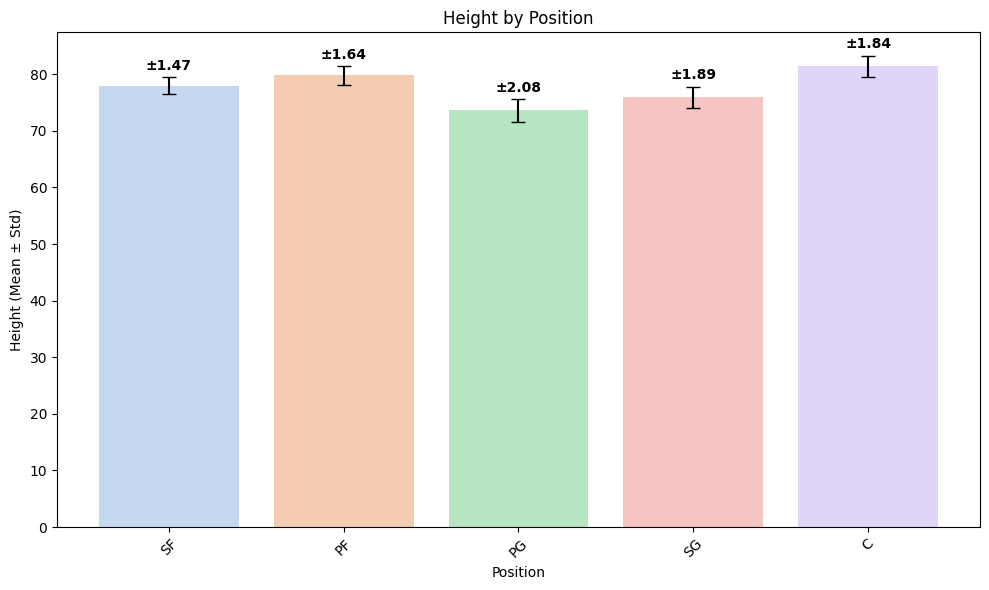

shape: (5, 3)
┌──────────┬─────────────┬────────────┐
│ Position ┆ Height_mean ┆ Height_std │
│ ---      ┆ ---         ┆ ---        │
│ str      ┆ f32         ┆ f32        │
╞══════════╪═════════════╪════════════╡
│ SF       ┆ 77.985283   ┆ 1.472926   │
│ PF       ┆ 79.799202   ┆ 1.635164   │
│ PG       ┆ 73.614204   ┆ 2.076422   │
│ SG       ┆ 75.949295   ┆ 1.888225   │
│ C        ┆ 81.414703   ┆ 1.839901   │
└──────────┴─────────────┴────────────┘


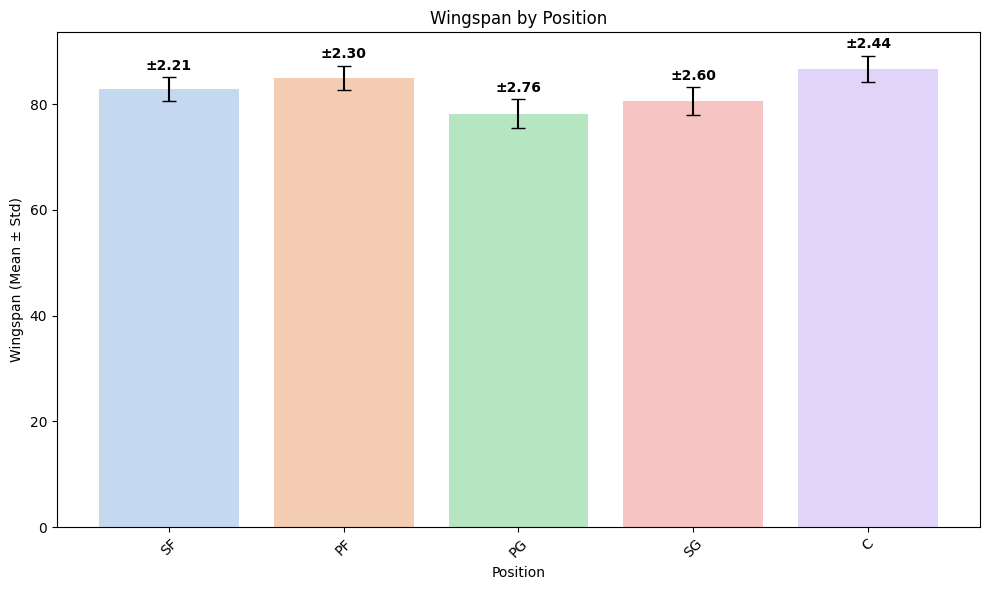

shape: (5, 3)
┌──────────┬───────────────┬──────────────┐
│ Position ┆ Wingspan_mean ┆ Wingspan_std │
│ ---      ┆ ---           ┆ ---          │
│ str      ┆ f32           ┆ f32          │
╞══════════╪═══════════════╪══════════════╡
│ SF       ┆ 82.856422     ┆ 2.20706      │
│ PF       ┆ 84.994591     ┆ 2.302653     │
│ PG       ┆ 78.233398     ┆ 2.764105     │
│ SG       ┆ 80.62912      ┆ 2.603145     │
│ C        ┆ 86.691864     ┆ 2.440395     │
└──────────┴───────────────┴──────────────┘


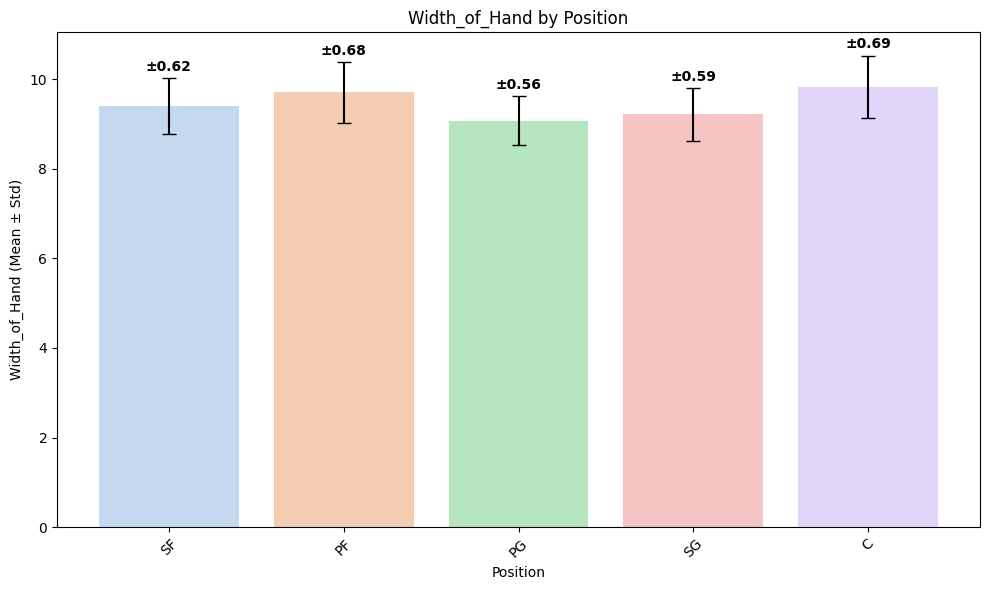

shape: (5, 3)
┌──────────┬────────────────────┬───────────────────┐
│ Position ┆ Width_of_Hand_mean ┆ Width_of_Hand_std │
│ ---      ┆ ---                ┆ ---               │
│ str      ┆ f32                ┆ f32               │
╞══════════╪════════════════════╪═══════════════════╡
│ SF       ┆ 9.409267           ┆ 0.617728          │
│ PF       ┆ 9.711597           ┆ 0.67772           │
│ PG       ┆ 9.081508           ┆ 0.557094          │
│ SG       ┆ 9.219108           ┆ 0.58941           │
│ C        ┆ 9.835177           ┆ 0.690162          │
└──────────┴────────────────────┴───────────────────┘


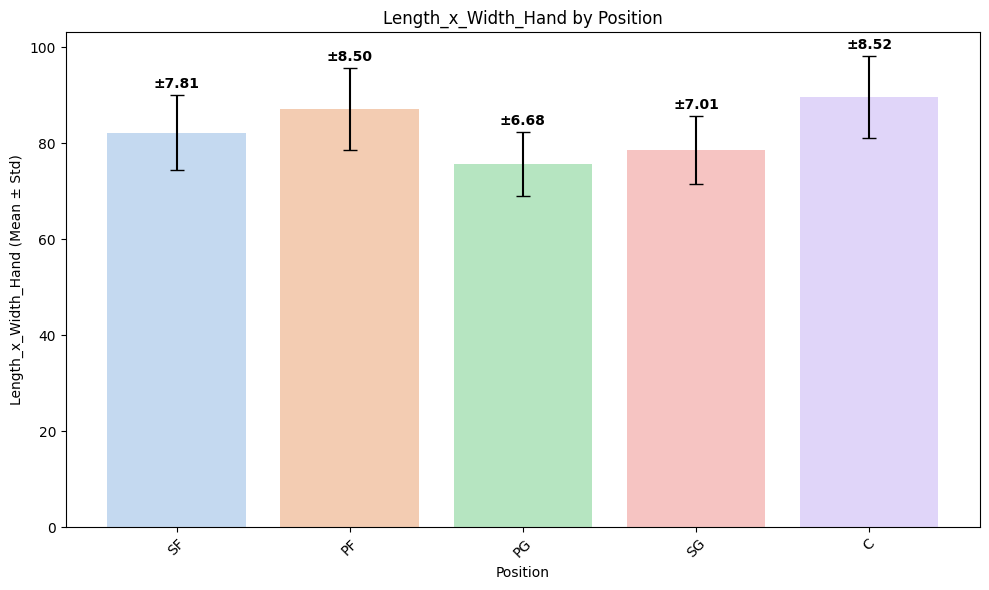

shape: (5, 3)
┌──────────┬──────────────────────────┬─────────────────────────┐
│ Position ┆ Length_x_Width_Hand_mean ┆ Length_x_Width_Hand_std │
│ ---      ┆ ---                      ┆ ---                     │
│ str      ┆ f32                      ┆ f32                     │
╞══════════╪══════════════════════════╪═════════════════════════╡
│ SF       ┆ 82.202751                ┆ 7.808844                │
│ PF       ┆ 87.096138                ┆ 8.50385                 │
│ PG       ┆ 75.654305                ┆ 6.682992                │
│ SG       ┆ 78.623276                ┆ 7.012119                │
│ C        ┆ 89.703407                ┆ 8.515203                │
└──────────┴──────────────────────────┴─────────────────────────┘


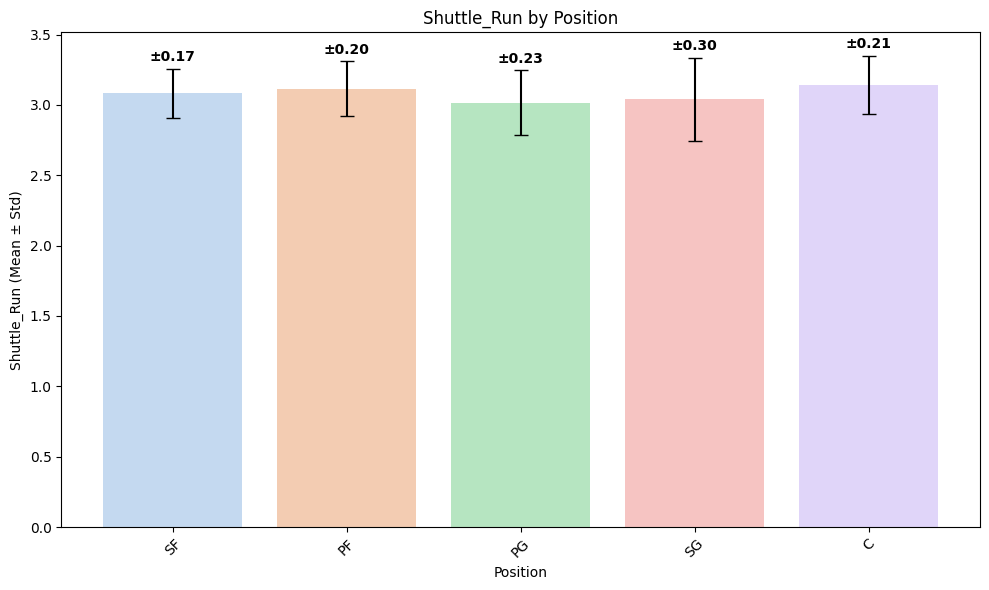

shape: (5, 3)
┌──────────┬──────────────────┬─────────────────┐
│ Position ┆ Shuttle_Run_mean ┆ Shuttle_Run_std │
│ ---      ┆ ---              ┆ ---             │
│ str      ┆ f32              ┆ f32             │
╞══════════╪══════════════════╪═════════════════╡
│ SF       ┆ 3.082609         ┆ 0.174834        │
│ PF       ┆ 3.115858         ┆ 0.197338        │
│ PG       ┆ 3.016923         ┆ 0.231105        │
│ SG       ┆ 3.040513         ┆ 0.296474        │
│ C        ┆ 3.142728         ┆ 0.205984        │
└──────────┴──────────────────┴─────────────────┘


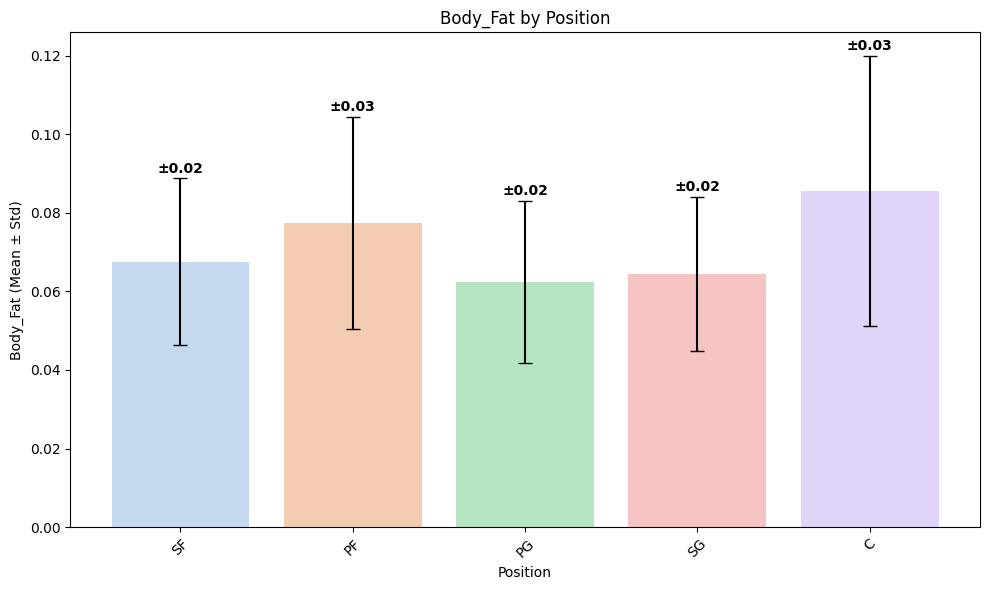

shape: (5, 3)
┌──────────┬───────────────┬──────────────┐
│ Position ┆ Body_Fat_mean ┆ Body_Fat_std │
│ ---      ┆ ---           ┆ ---          │
│ str      ┆ f32           ┆ f32          │
╞══════════╪═══════════════╪══════════════╡
│ SF       ┆ 0.067588      ┆ 0.021223     │
│ PF       ┆ 0.077416      ┆ 0.027044     │
│ PG       ┆ 0.062449      ┆ 0.020696     │
│ SG       ┆ 0.064493      ┆ 0.019594     │
│ C        ┆ 0.08562       ┆ 0.034372     │
└──────────┴───────────────┴──────────────┘


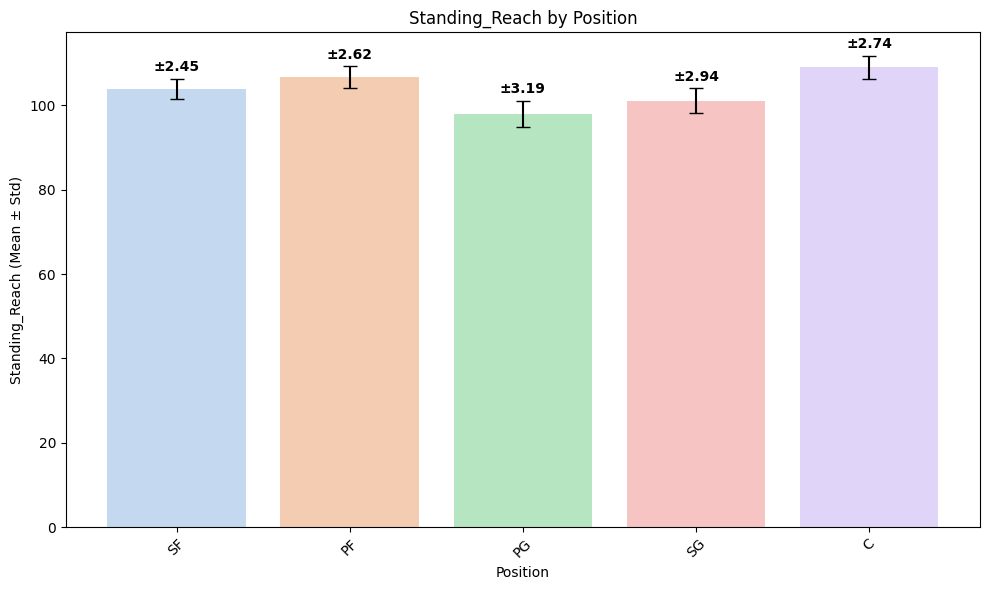

shape: (5, 3)
┌──────────┬─────────────────────┬────────────────────┐
│ Position ┆ Standing_Reach_mean ┆ Standing_Reach_std │
│ ---      ┆ ---                 ┆ ---                │
│ str      ┆ f32                 ┆ f32                │
╞══════════╪═════════════════════╪════════════════════╡
│ SF       ┆ 103.927406          ┆ 2.446338           │
│ PF       ┆ 106.668297          ┆ 2.622063           │
│ PG       ┆ 97.974541           ┆ 3.193079           │
│ SG       ┆ 101.121246          ┆ 2.941894           │
│ C        ┆ 109.020821          ┆ 2.744162           │
└──────────┴─────────────────────┴────────────────────┘


In [204]:
combine_stats = df_wide_view_positions.select(pl.exclude(pl.String)).columns

def plot_stats_by_position(col: str, df: pl.DataFrame):
    plt.figure(figsize=(10, 6))
    # Create a bar plot with error bars
    # Using seaborn's barplot to get mean and standard deviation
    # Note: Seaborn's barplot automatically calculates the mean and standard deviation
    # but we will add error bars manually for better control
    ax = sns.barplot(
        df_summary,
        x="Position",
        y=f"{col}_mean",
        capsize=5,
        alpha=0.7,
        palette="pastel",
        hue="Position",
    )
    
    # Add error bars manually using matplotlib
    x_coords = range(len(df_summary))
    means = df_summary[f"{col}_mean"].to_list()
    stds = df_summary[f"{col}_std"].to_list()
    
    ax.errorbar(x_coords, means, yerr=stds, fmt='none', c='black', capsize=5, lw=1.5)

      # Add std text on top of each bar
    for x, y, std in zip(x_coords, means, stds):
        offset = y * 0.01 # Slightly above the error bar
        ax.text(
            x,
            y + std + offset,
            f"±{std:.2f}",
            ha="center",
            va="bottom",
            fontsize=10,
            color="black",
            fontweight="bold"
        )

    ax.set_ylabel(f"{col.replace('_', ' ')} (Mean ± Std)")
    ax.set_title(f"{col.replace('_', ' ')} by Position")
    ax.set_xticks(x_coords)

    plt.ylabel(f"{col} (Mean ± Std)")
    plt.title(f"{col} by Position")
    plt.xticks(rotation=45)
    plt.tight_layout()
    temp = visualization_path / f"bivariate"
    temp.mkdir(parents=True, exist_ok=True)
    plt.savefig(temp / f"Bivariate_{col}_by_Position.png")
    plt.show()
    
    print(df_summary.select("Position", f"{col}_mean", f"{col}_std"))


for col in combine_stats:
    plot_stats_by_position(col, df_summary)


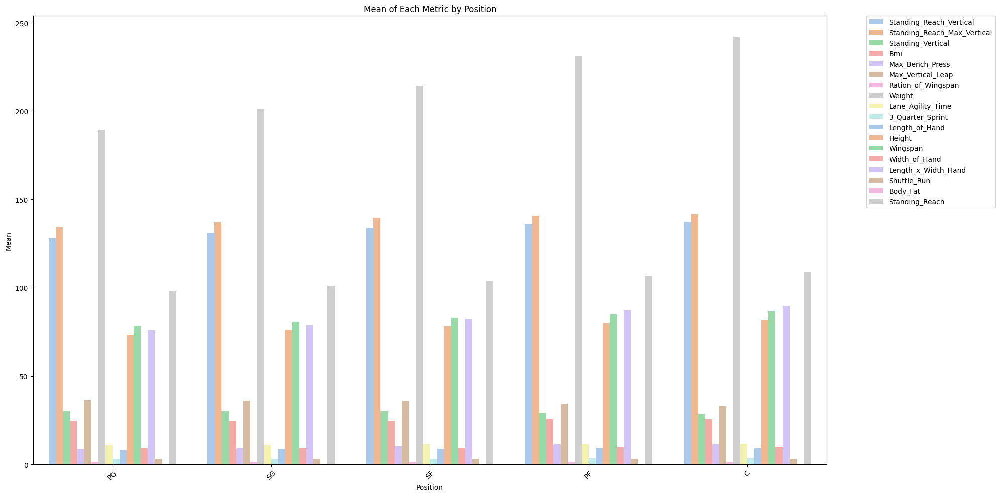

In [205]:
# Melt the wide dataframe into long format for seaborn
df_melted = df_summary.unpivot(
    index=["Position"],
    on=[col for col in df_summary.columns if col.endswith("_mean")],
    variable_name="Metric",
    value_name="Mean"
)

df_melted = df_melted.with_columns(
    pl.col("Metric").str.replace("_mean$", "")
)
plt.figure(figsize=(20, 10))
sns.barplot(data=df_melted, x="Position", y="Mean", hue="Metric", palette="pastel",
        order=["PG", "SG", "SF", "PF", "C"] )
plt.xticks(rotation=45)
plt.title("Mean of Each Metric by Position")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
temp = visualization_path / f"bivariate"
temp.mkdir(parents=True, exist_ok=True)
plt.savefig(temp / "Mean_Metric_by_Position.png")
plt.show()


The previous graphic was difficult to interpret due to the number of metrics and overlapping bars. To provide clearer insights, we will use pairplots to visualize the distribution and relationships of each combine stat by player position. Pairplots allow us to compare multiple features simultaneously, making it easier to identify patterns and differences across positions for key physical and performance metrics.

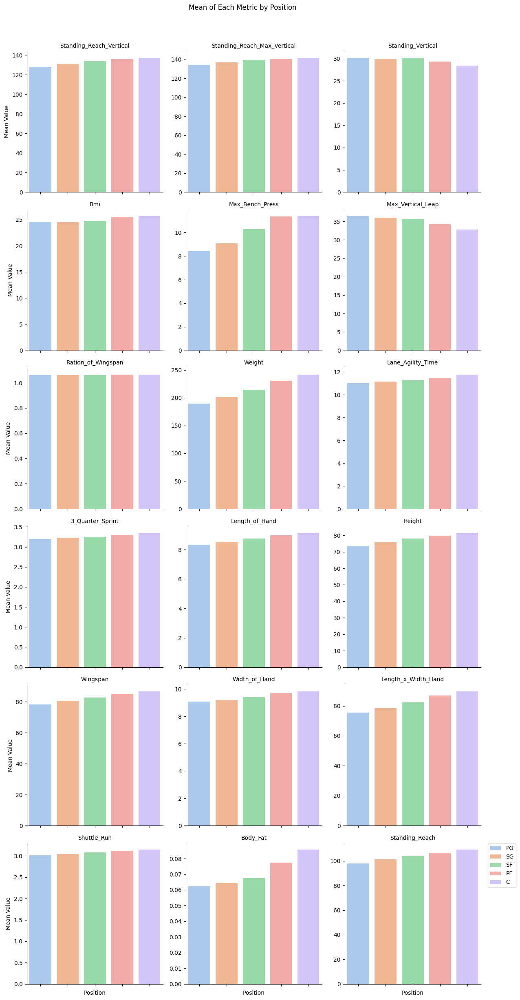

In [206]:
positions_order = ["PG", "SG", "SF", "PF", "C"]

g = sns.FacetGrid(df_melted, col="Metric", col_wrap=3, sharey=False, sharex=False, height=4)

# Map barplot with hue=Position, order specified for both x and hue
g.map_dataframe(
    sns.barplot,
    x="Position",
    y="Mean",
    hue="Position",
    order=positions_order,
    hue_order=positions_order,
    dodge=False,      # bars grouped together, not side-by-side
    palette="pastel",
    legend=True     
    
)
g.set_titles("{col_name}")
g.set_axis_labels("Position", "Mean Value")
g.fig.suptitle("Mean of Each Metric by Position", y=1.02)
# Remove x-tick labels to avoid clutter
for ax in g.axes.flatten():
    ax.set_xticklabels([])
plt.tight_layout()
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
temp = visualization_path / f"bivariate"
temp.mkdir(parents=True, exist_ok=True)

plt.savefig(temp / "Bivariate_Stats_by_Positions.png")
plt.show()


In [ ]:
from scipy.stats import f_oneway, ttest_ind
import polars as pl

def combine_stat_tests_by_position(df: pl.DataFrame, stats=None, position_col="Position"):
    """
    Perform ANOVA and pairwise t-tests for each combine stat across positions.
    Returns a summary DataFrame with p-values for ANOVA and t-tests.
    """
    if stats is None:
        stats = df.select(pl.exclude([pl.String, pl.Boolean])).columns

    positions = df[position_col].unique().to_list()
    results = []

    for stat in stats:
        # Prepare data for ANOVA
        groups = [df.filter(pl.col(position_col) == pos)[stat].drop_nulls().to_numpy() for pos in positions]
        # Only run ANOVA if there are at least two groups with data
        if sum(len(g) > 1 for g in groups) >= 2:
            anova_p = f_oneway(*groups).pvalue
        else:
            anova_p = None

        # Pairwise t-tests
        for i in range(len(positions)):
            for j in range(i + 1, len(positions)):
                g1 = groups[i]
                g2 = groups[j]
                if len(g1) > 1 and len(g2) > 1:
                    ttest_p = ttest_ind(g1, g2, nan_policy='omit').pvalue
                else:
                    ttest_p = None
                results.append({
                    "Stat": stat,
                    "Position1": positions[i],
                    "Position2": positions[j],
                    "ANOVA_p": anova_p,
                    "TTest_p": ttest_p
                })
    return pl.from_dicts(results)

stat_tests_df = combine_stat_tests_by_position(df_wide_view_positions)

display(stat_tests_df.select("Stat", "ANOVA_p").unique(["Stat"]).filter(pl.col("ANOVA_p") < 0.05).sort("ANOVA_p"))
position_df = stat_tests_df.drop("ANOVA_p") \
    .filter(pl.col("TTest_p") < 0.05) \
    .sort("TTest_p") \
    .with_columns(
        (pl.col("Position1") + " vs " + pl.col("Position2")).alias("Position_Comparison")
    )
position_df = position_df.drop("Position1", "Position2").select("Stat", "Position_Comparison", "TTest_p")
position_df.pivot(
    index="Position_Comparison",
    values="TTest_p",
    on="Stat"
).sort("Position_Comparison").fill_null(1.0)  # Fill nulls with 1.0 for no significant difference

Stat,ANOVA_p
str,f64
"""Weight""",0.0
"""Lane_Agility_Time""",0.0
"""Standing_Reach_Vertical""",0.0
"""Wingspan""",0.0
"""Length_x_Width_Hand""",0.0
…,…
"""Body_Fat""",8.5285e-30
"""Bmi""",5.4932e-19
"""Standing_Vertical""",1.4934e-12


Position_Comparison,Height,Standing_Reach,Wingspan,Weight,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Length_of_Hand,Lane_Agility_Time,Length_x_Width_Hand,3_Quarter_Sprint,Max_Vertical_Leap,Width_of_Hand,Body_Fat,Bmi,Standing_Vertical,Max_Bench_Press,Shuttle_Run
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""C vs PF""",1.9816e-27,1.4857e-24,2.1863e-17,2.0016e-12,5.5743e-7,0.001102,0.000135,1.4347e-11,0.003986,0.000055,5.7684e-7,1.0,0.002694,1.0,0.000284,1.0,1.0
"""C vs PG""",2.7487e-180,5.2218e-168,5.8241e-146,2.1480e-118,6.3404e-107,1.9174e-76,2.3781e-49,5.9916e-46,1.8515e-44,1.8721e-31,5.6089e-26,2.9111e-23,1.7459e-16,5.9015e-8,5.6287e-10,4.4829e-8,0.000076
"""PG vs PF""",1.7848e-186,8.1710e-165,9.4472e-144,5.8312e-118,1.8524e-108,5.1831e-79,1.5842e-45,5.7789e-25,2.7431e-39,2.6275e-23,2.5945e-14,4.1717e-21,9.5232e-12,7.0029e-8,0.00082,1.2870e-8,0.000262
"""SF vs C""",9.0987e-95,2.4842e-87,1.0329e-67,1.6603e-62,9.6594e-31,6.9798e-14,4.1375e-18,1.8821e-24,2.0821e-16,1.8983e-16,1.1380e-19,2.3899e-9,5.5806e-12,2.5615e-7,3.8639e-10,0.033137,0.019655
"""SF vs PF""",6.0096e-47,2.1121e-41,3.9265e-33,6.5876e-37,1.1288e-14,9.7665e-7,2.1996e-9,0.000008,5.7696e-10,1.3096e-7,7.2751e-8,0.000001,0.000002,0.000001,0.00151,0.024791,1.0
"""SF vs PG""",8.3419e-125,8.4906e-102,4.4975e-85,7.5107e-60,8.1376e-75,4.6899e-56,1.2217e-22,1.5596e-10,6.3594e-17,1.3719e-7,0.009392,9.9487e-8,0.006595,1.0,1.0,0.000217,0.010443
"""SG vs C""",9.0119e-160,1.5965e-148,9.6976e-124,4.8605e-123,1.3519e-74,1.0967e-44,1.1904e-42,1.8301e-42,9.8488e-39,7.4675e-24,2.7750e-25,3.4282e-20,1.1658e-18,1.1513e-13,1.0415e-9,0.000004,0.003674
"""SG vs PF""",8.6896e-135,6.9557e-119,1.1478e-100,2.6755e-106,2.0961e-64,1.0953e-39,8.8774e-34,1.5610e-17,2.2326e-31,4.2082e-14,6.9809e-12,1.2181e-17,5.7146e-12,1.1696e-13,0.004381,8.7968e-7,0.009232
"""SG vs PG""",1.8829e-45,6.3029e-36,3.3019e-28,4.1324e-18,3.7782e-23,4.9190e-18,1.2584e-7,0.001419,0.000009,0.001894,1.0,0.013612,1.0,1.0,1.0,1.0,1.0


### Insights from ANOVA and t-tests on NBA Draft Combine Stat Comparisons

Statistical tests reveal several important differences in combine metrics across NBA positions:

- **Physical Attributes Vary Strongly by Position:** ANOVA and pairwise t-tests show extremely significant differences (p < 0.001) in Height, Standing Reach, Wingspan, and Weight between positions. Centers (C) and Power Forwards (PF) are consistently taller, heavier, and possess greater reach than Guards (PG, SG), confirming expected positional archetypes.

- **Hand Measurements Distinguish Bigs from Guards:** Metrics like Length_x_Width_Hand, Width_of_Hand, and Length_of_Hand are significantly higher for bigs (C, PF) compared to guards, with p-values often < 1e-10. This suggests hand size is a notable differentiator by position.

- **Athleticism and Speed Metrics:** Max Vertical Leap and Standing Vertical are higher for guards and wings (PG, SG, SF) than for bigs, indicating greater explosive leaping ability among perimeter players. Agility stats (Lane Agility Time, Shuttle Run, 3_Quarter_Sprint) also show significant differences, with guards generally posting better times.

- **Body Composition:** Body Fat and BMI show moderate but significant differences, with guards tending to be leaner than forwards and centers.

- **Statistically Robust Differences:** Nearly all combine metrics have at least one pairwise positional comparison with p < 0.05, indicating that physical and athletic traits are reliably distinct across NBA roles.

**Conclusion:**  
NBA Draft Combine data robustly differentiates player positions on physical, athletic, and body composition metrics. These differences are statistically significant and align with the demands of each role, supporting the use of combine stats for scouting and player evaluation.

### Season vs Combine Stats

In [208]:
numeric_cols = df_wide_view_positions.select([pl.col(pl.Float32), pl.col(pl.Float64), pl.col(pl.Int64)]).columns

df_summary = df_wide_view.group_by("Season").agg(
    [
        *(pl.col(col).mean().alias(f"{col}_mean") for col in numeric_cols),
        *(pl.col(col).std().alias(f"{col}_std") for col in numeric_cols)
    ]
)
df_summary

Season,Standing_Reach_Vertical_mean,Standing_Reach_Max_Vertical_mean,Standing_Vertical_mean,Bmi_mean,Max_Bench_Press_mean,Max_Vertical_Leap_mean,Ration_of_Wingspan_mean,Weight_mean,Lane_Agility_Time_mean,3_Quarter_Sprint_mean,Length_of_Hand_mean,Height_mean,Wingspan_mean,Width_of_Hand_mean,Length_x_Width_Hand_mean,Shuttle_Run_mean,Body_Fat_mean,Standing_Reach_mean,Standing_Reach_Vertical_std,Standing_Reach_Max_Vertical_std,Standing_Vertical_std,Bmi_std,Max_Bench_Press_std,Max_Vertical_Leap_std,Ration_of_Wingspan_std,Weight_std,Lane_Agility_Time_std,3_Quarter_Sprint_std,Length_of_Hand_std,Height_std,Wingspan_std,Width_of_Hand_std,Length_x_Width_Hand_std,Shuttle_Run_std,Body_Fat_std,Standing_Reach_std
str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""2010-11""",133.125,138.733337,27.375,25.607693,11.372093,32.944443,1.065115,224.594238,11.598887,3.321111,8.798077,78.456734,83.57692,9.669229,85.028854,null,0.078558,105.605766,4.360399,3.905998,3.036838,2.411886,5.41173,3.501984,0.027318,28.033371,0.57683,0.143894,0.500094,2.913256,3.988199,0.679544,9.077496,null,0.033394,4.574371
"""2007-08""",132.546661,137.166672,29.306667,25.121054,12.16,33.926666,1.062434,214.89473,11.615869,3.332027,null,77.440788,82.269737,null,null,null,0.068145,103.263161,4.927977,4.639237,3.207775,1.699907,5.5411,3.380882,0.029989,25.333813,0.512617,0.123477,null,3.412201,4.196181,null,null,null,0.024239,4.990974
"""2012-13""",132.845459,137.490906,30.527273,25.374998,9.849056,35.172726,1.060267,219.898331,11.34717,3.359074,8.8625,77.98333,82.683334,9.541663,84.569992,null,0.072817,102.26667,4.832253,4.273617,2.517381,1.987898,5.375858,3.185933,0.027485,24.954533,0.536557,0.134069,0.449635,3.04586,3.901017,0.759637,9.814263,null,0.022139,4.620759
"""2016-17""",133.527023,138.675674,31.067568,23.99592,null,36.216217,1.064592,208.183701,11.178647,3.304325,8.65625,78.0,83.010201,9.220832,79.750008,2.948158,0.0703125,102.581635,5.17331,4.303126,3.093816,3.895776,null,3.340701,0.022442,37.402401,0.465243,0.119432,0.433396,3.651127,3.615634,0.673814,8.194108,0.515552,0.023839,5.085054
"""2019-20""",132.86792,139.07547,29.547171,24.587303,7.854167,35.754719,1.063422,210.911118,11.149999,3.29566,8.7421875,77.609375,82.519531,9.42656,82.484375,3.157359,0.05819,103.507812,4.830941,4.513225,2.932353,2.025841,4.98077,3.411833,0.028006,23.383997,0.539897,0.125675,0.575576,3.527915,4.147648,0.675476,10.266098,0.177028,0.017472,5.245173
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""2025-26""",132.610291,138.507355,28.977942,24.351389,null,34.875,1.049014,212.488876,11.227942,3.158824,8.78125,78.246529,82.0625,9.563886,84.140274,3.002941,null,103.611115,4.581635,4.226332,2.795831,1.626366,null,3.391577,0.026457,23.905823,0.485874,0.183852,0.494579,3.460922,3.823056,0.692882,9.268934,0.119664,null,4.710807
"""2002-03""",132.075348,136.452057,28.157534,25.224689,10.220779,32.534248,1.055432,217.074081,11.637808,3.270416,null,77.65432,81.959877,null,null,null,null,103.962959,5.438847,4.935813,3.033238,1.929996,5.613947,3.315922,0.028819,27.836027,0.653736,0.107748,null,3.614979,4.347495,null,null,null,null,5.093364
"""2023-24""",133.765305,139.214279,30.397959,24.571936,null,35.846939,1.058579,210.564911,11.161633,3.223878,8.596491,77.635101,82.173676,9.389472,80.76667,3.147778,null,103.385963,3.699806,3.338538,2.571842,2.059885,null,2.848984,0.025143,20.379755,0.382793,0.188346,0.442584,2.229149,3.092475,0.700939,9.240542,0.150901,null,3.438253


In [209]:
# Melt the wide dataframe into long format for seaborn
df_melted = df_summary.unpivot(
    index=["Season"],
    on=[col for col in df_summary.columns if col.endswith("_mean")],
    variable_name="Metric",
    value_name="Mean"
)

df_melted = df_melted.with_columns(
    pl.col("Metric").str.replace("_mean$", "")
).sort("Season")

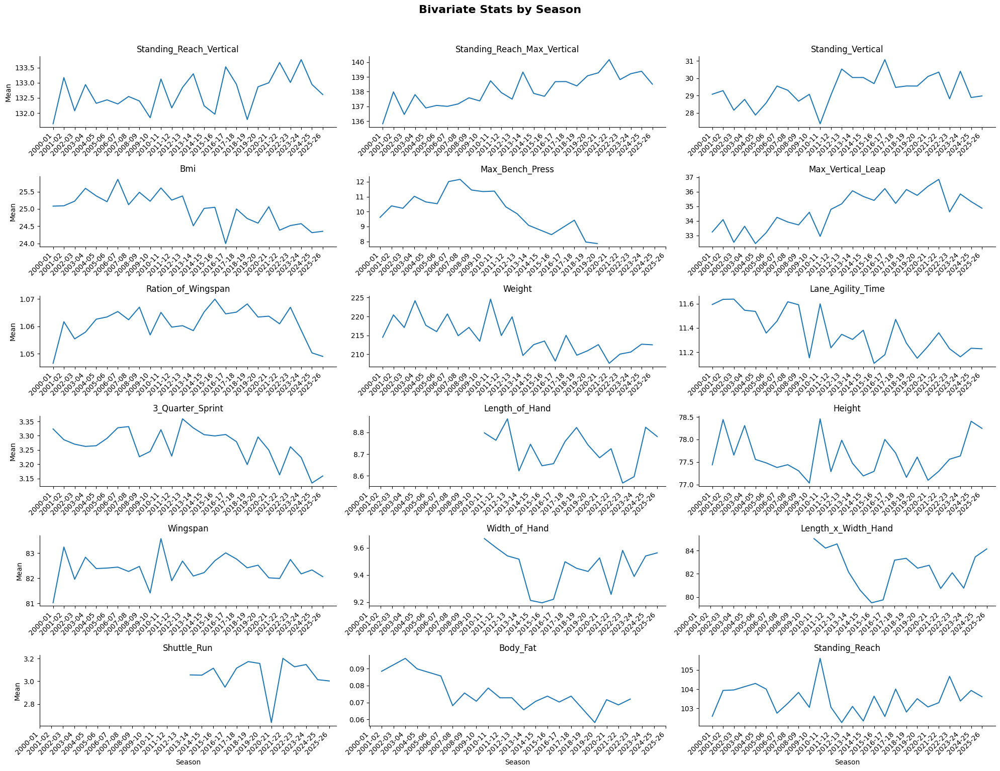

In [210]:
seasons = sorted(df_melted["Season"].unique())

g = sns.FacetGrid(
    df_melted,
    col="Metric",
    col_wrap=3,
    sharey=False,
    sharex=False,
    height=4
)

g.map_dataframe(
    sns.lineplot,
    x="Season",
    y="Mean",
)

for ax in g.axes.flatten():
    ticks = ax.get_xticks()
    ax.set_xticks(ticks)
    ax.set_xticklabels(seasons, rotation=45, ha='right')
    ax.set_title(ax.get_title().replace("Metric = ", ""))

g.fig.set_size_inches(20, 15)
g.fig.suptitle("Bivariate Stats by Season", fontsize=16, weight='bold', y=1.02)
plt.subplots_adjust(top=0.92)  # Make room for the suptitle
plt.tight_layout()
temp = visualization_path / f"bivariate"
temp.mkdir(parents=True, exist_ok=True)
plt.savefig(temp / "Bivariate_Stats_by_Season_Lineplots.png")
plt.show()



## Bivariate Analysis Summary: NBA Draft Combine

### Numerical vs Numerical

The bivariate analysis of NBA Draft Combine data reveals strong interrelationships among physical and performance metrics. Features such as Height, Wingspan, Standing Reach, and Weight are highly correlated, indicating that taller players tend to have longer wingspans, greater standing reach, and higher body mass. These physical attributes also show robust positive correlations with key NBA performance metrics—most notably, Total Rebound Percentage (TRB%), Defensive Rebound Percentage (DRB%), Offensive Rebound Percentage (ORB%), and Block Percentage (BLK%). For example, players with greater height and wingspan consistently achieve higher rebound and block rates, underscoring the predictive value of these combine measurements for on-court success.

**Statistical tests (t-tests, ANOVA, Mann-Whitney) confirm these relationships are highly significant:**  
- Height, Standing Reach, Wingspan, and Weight all show extremely low p-values and strong Pearson correlations (often > 0.7) between each other.
- Athletic metrics like Max Vertical Leap and Standing Vertical are tightly coupled (r ≈ 0.84), and hand measurements (Length_x_Width_Hand, Width_of_Hand, Length_of_Hand) are also strongly correlated (r > 0.8).
- Nearly all tested feature pairs with p-values < 0.05 indicate meaningful differences or associations, supporting the reliability of combine metrics for distinguishing player physical profiles.

### Numerical vs "Categorical" (Season & Position)

#### By Position

When stratified by position (PG, SG, SF, PF, C), clear differences emerge in physical and athletic profiles. Centers (C) and Power Forwards (PF) exhibit the highest averages in Height, Wingspan, Standing Reach, and Weight, reflecting the demands of their roles near the basket. Guards (PG, SG) are generally shorter and lighter, with lower combine metrics in these categories. Performance metrics such as rebounding and blocking also vary by position, with bigs (PF, C) dominating these areas, while guards excel in agility and speed-related stats.

**Statistical tests show these positional differences are robust:**  
- ANOVA and pairwise t-tests reveal extremely significant differences (p < 0.001) in Height, Standing Reach, Wingspan, Weight, and hand measurements between positions.
- Guards tend to have higher vertical leap and agility scores, while bigs have superior size and reach.
- Nearly all combine metrics have at least one pairwise positional comparison with p < 0.05, indicating that physical and athletic traits are reliably distinct across NBA roles.

#### By Season

Examining combine metrics across draft seasons reveals subtle trends in player profiles over time. While the average physical attributes remain relatively stable, certain metrics—such as vertical leap and agility—show slight improvements in more recent years, possibly reflecting advances in training and athlete development. Participation rates and the distribution of combine measurements fluctuate by season, highlighting changes in draft class composition and evolving league standards.

### Key Takeaways

- Physical attributes measured at the combine are strongly predictive of NBA performance, especially in rebounding and blocking.
- Statistical tests confirm that these relationships and positional differences are highly significant and robust.
- Positional analysis shows centers and forwards possess superior size and reach, while guards excel in speed and agility.
- Seasonal trends suggest incremental improvements in athleticism, with some variability in combine participation and measurement distributions.
- These insights support the use of combine data for scouting, player development, and forecasting NBA success.

## Draft Combine Stats vs NBA Performance


This section explores how key physical attributes measured at the NBA Draft Combine—Wingspan, Height, and Standing Reach—compare among top NBA performers. We analyze their relationships with important NBA performance metrics such as Total Rebound Percentage (TRB%), Defensive Rebound Percentage (DRB%), Offensive Rebound Percentage (ORB%), and Block Percentage (BLK%).

**Key questions addressed:**
- Do players with greater wingspan, height, or standing reach achieve higher rebound and block rates?
- How do these physical traits differ between All-Star players and others?
- Are standout combine measurements associated with NBA accolades and top performance?

Visualizations below include scatterplots, pairplots, and boxplots to highlight the strongest correlations and distribution differences. These insights help reveal which physical traits are most predictive of NBA success and recognition.

### Construct query to grab combine data with nba data

In [211]:
query = """
SELECT 
    p.name as Player, 
    s.label as Season,
    po.name as Position,
    nba_stat.name as NBA_Stat,
    psv.value as NBA_Value, 
    
    combine_stat.name as Combine_Stat,
    csv.value as Combine_Value, 
     
    a.allstar as AllStar,
    a.all_defense_team as Defense_Team,
    a.all_nba_team as All_NBA_Team,
    a.mvp_rank as MVP_Rank,
    a.dpoy_rank as DPOY_Rank

from nba_data.main.player_stat_values psv
JOIN nba_data.main.players p on psv.player_id == p.player_id
JOIN nba_data.main.player_positions pp on pp.player_id == p.player_id
JOIN nba_data.main.positions po on po.position_id == pp.position_id
JOIN nba_data.main.award_info a on a.player_id == p.player_id
JOIN nba_data.main.combine_stat_values csv on csv.player_id == p.player_id
JOIN nba_data.main.seasons s on psv.season_id == s.season_id
JOIN nba_data.main.stats nba_stat on nba_stat.stat_id == psv.stat_id
JOIN nba_data.main.stats combine_stat on combine_stat.stat_id == csv.stat_id 
"""

with get_duckdb_connection() as con:
    df_nba_combined = pl.from_arrow(con.execute(query).arrow()).lazy()
    df_nba_combined.collect().columns

Connected to: /Users/rashe/PycharmProjects/PredictingNBACareers/data/refined_raw_data/nba_data.duckdb


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [212]:
df_nba_combined.collect().head()

Player,Season,Position,NBA_Stat,NBA_Value,Combine_Stat,Combine_Value,AllStar,Defense_Team,All_NBA_Team,MVP_Rank,DPOY_Rank
str,str,str,str,f32,str,f32,bool,i32,i32,i32,i32
"""Trevor Ariza""","""2007-08""","""SG""","""eFG%""",0.526,"""Width_of_Hand""",null,false,0,0,0,0
"""Nick Collison""","""2007-08""","""C""","""2PA""",8.2,"""3_Quarter_Sprint""",3.28,false,0,0,0,0
"""Matt Carroll""","""2007-08""","""SG""","""PTS""",9.0,"""Standing_Reach_Max_Vertical""",132.0,false,0,0,0,0
"""Ronnie Brewer""","""2007-08""","""SG""","""AST""",1.8,"""Standing_Vertical""",35.0,false,0,0,0,0
"""Brian Scalabrine""","""2007-08""","""C""","""FGA""",2.0,"""Wingspan""",81.75,false,0,0,0,0


In [213]:
df = df_nba_combined.with_columns([
    (pl.col("Player") + "_" + pl.col("Season")).alias("Player_Season")
])

In [214]:
nba_wide = (
    df.collect().select(["Player_Season", "NBA_Stat", "NBA_Value"])
      .pivot(
          values="NBA_Value",
          index="Player_Season",
          on="NBA_Stat",
          aggregate_function="first"  # Assuming no duplicates
      )
)

In [215]:
combine_wide = (
    df.collect().select(["Player_Season", "Combine_Stat", "Combine_Value"])
      .pivot(
          values="Combine_Value",
          index="Player_Season",
          on="Combine_Stat",
          aggregate_function="first"
      )
)

In [216]:
combine_wide

Player_Season,Width_of_Hand,3_Quarter_Sprint,Standing_Reach_Max_Vertical,Standing_Vertical,Wingspan,Max_Vertical_Leap,Length_of_Hand,Bmi,Max_Bench_Press,Body_Fat,Height,Shuttle_Run,Standing_Reach_Vertical,Length_x_Width_Hand,Standing_Reach,Weight,Ration_of_Wingspan,Lane_Agility_Time
str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""Trevor Ariza_2007-08""",null,3.29,139.5,29.5,86.0,32.0,null,22.6,8.0,0.08,79.0,null,137.0,null,107.5,201.0,1.089,11.63
"""Nick Collison_2007-08""",null,3.28,141.0,28.0,85.5,33.0,null,27.5,8.0,0.17,80.75,null,136.0,null,108.0,255.0,1.059,11.62
"""Matt Carroll_2007-08""",null,3.35,132.0,29.0,78.5,33.5,null,24.5,13.0,0.067,77.0,null,127.5,null,98.5,207.0,1.019,11.11
"""Ronnie Brewer_2007-08""",null,3.14,144.5,35.0,83.25,41.0,null,25.9,19.0,0.05,77.75,null,138.5,null,103.5,223.0,1.071,11.32
"""Brian Scalabrine_2007-08""",null,3.47,136.0,27.0,81.75,30.5,null,26.0,14.0,0.136,80.75,null,132.5,null,105.5,241.0,1.012,11.75
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""Marcus Thornton_2009-10""",8.5,3.02,140.5,34.5,79.75,43.0,8.25,22.9,3.0,0.053,73.75,2.88,132.0,70.099998,97.5,177.399994,1.081,10.78
"""Chris Duhon_2009-10""",null,3.14,133.0,31.5,78.5,35.0,null,26.200001,7.0,0.067,72.0,null,129.5,null,98.0,193.0,1.09,10.45
"""Rasual Butler_2009-10""",null,3.29,143.0,31.5,84.0,37.5,null,22.4,10.0,null,78.75,null,137.0,null,105.5,198.0,1.067,11.54


In [217]:
combined_wide = nba_wide.join(combine_wide, on="Player_Season", how="inner")

In [218]:
combined_wide = combined_wide.with_columns(
    pl.col("Player_Season").str.split_exact("_", 1).alias("split")
).unnest("split").rename({"field_0": "Player", "field_1": "Season"}).drop("Player_Season")

In [219]:
combined_wide

eFG%,2PA,PTS,AST,FGA,2P,TOV,GS,2P%,G,FG%,ORB,3PA,BLK,3P,FT,MP,PF,FT%,STL,FG,FTA,3P%,DRB,TRB,TS%,USG%,OWS,BLK%,AST%,OBPM,ORB%,WS,DRB%,FTr,STL%,DWS,BPM,TRB%,3PAr,VORP,DBPM,TOV%,WS/48,PER,Trp-Dbl,Width_of_Hand,3_Quarter_Sprint,Standing_Reach_Max_Vertical,Standing_Vertical,Wingspan,Max_Vertical_Leap,Length_of_Hand,Bmi,Max_Bench_Press,Body_Fat,Height,Shuttle_Run,Standing_Reach_Vertical,Length_x_Width_Hand,Standing_Reach,Weight,Ration_of_Wingspan,Lane_Agility_Time,Player,Season
f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,str,str
0.526,118.0,5.5,1.3,3.9,1.8,23.0,3.0,0.542,35.0,0.507,0.9,0.5,0.3,5.0,1.4,15.6,1.3,0.653,0.9,69.0,2.1,0.278,2.2,3.1,0.568,15.6,0.9,1.5,11.8,0.4,6.4,1.8,15.4,0.551,2.9,0.9,2.8,11.1,0.132,0.7,2.3,12.0,0.157,16.1,0.0,null,3.29,139.5,29.5,86.0,32.0,null,22.6,8.0,0.08,79.0,null,137.0,null,107.5,201.0,1.089,11.63,"""Trevor Ariza""","""2007-08"""
0.502,8.2,9.8,1.4,8.2,4.1,118.0,35.0,0.504,78.0,0.502,254.0,0.0,0.8,0.0,1.6,28.5,3.2,0.737,0.6,322.0,2.1,0.0,6.1,9.4,0.537,16.200001,2.2,1.9,7.9,-1.2,12.5,4.5,23.299999,0.261,1.1,2.3,-1.4,17.9,0.003,0.3,-0.2,14.2,0.098,15.0,0.0,null,3.28,141.0,28.0,85.5,33.0,null,27.5,8.0,0.17,80.75,null,136.0,null,108.0,255.0,1.059,11.62,"""Nick Collison""","""2007-08"""
0.517,4.4,9.0,0.9,589.0,1.8,0.7,18.0,0.422,80.0,0.428,0.4,3.0,0.2,1.3,1.4,2016.0,2.3,0.804,0.6,3.2,138.0,0.436,193.0,2.8,0.554,16.1,1.9,0.7,5.8,-1.2,1.9,3.0,11.1,0.234,1.2,1.0,-2.0,6.4,0.409,0.0,-0.8,8.2,0.071,10.7,0.0,null,3.35,132.0,29.0,78.5,33.5,null,24.5,13.0,0.067,77.0,null,127.5,null,98.5,207.0,1.019,11.11,"""Matt Carroll""","""2007-08"""
0.567,7.7,12.0,1.8,8.3,343.0,0.9,76.0,0.587,76.0,0.558,1.3,0.7,0.3,0.1,2.6,27.5,1.4,0.759,129.0,4.7,3.4,0.22,1.6,218.0,0.612,17.5,5.4,0.7,9.7,2.2,5.7,7.8,7.0,0.405,3.2,2.4,3.8,6.4,0.079,3.1,1.6,8.5,0.178,18.4,0.0,null,3.14,144.5,35.0,83.25,41.0,null,25.9,19.0,0.05,77.75,null,138.5,null,103.5,223.0,1.071,11.32,"""Ronnie Brewer""","""2007-08"""
0.388,1.0,88.0,0.8,2.0,0.3,0.5,9.0,0.292,48.0,0.309,0.5,1.0,0.2,0.3,0.3,512.0,1.3,0.75,0.2,0.6,20.0,0.326,57.0,1.6,0.428,11.7,-0.3,1.3,11.2,-3.8,5.4,0.6,12.5,0.213,0.9,0.9,-2.8,9.2,0.489,-0.1,1.0,20.200001,0.057,5.1,0.0,null,3.47,136.0,27.0,81.75,30.5,null,26.0,14.0,0.136,80.75,null,132.5,null,105.5,241.0,1.012,11.75,"""Brian Scalabrine""","""2007-08"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.517,570.0,1057.0,1.6,883.0,3.8,76.0,17.0,0.493,73.0,0.451,1.0,4.3,0.2,117.0,144.0,1872.0,127.0,0.814,58.0,398.0,177.0,0.374,139.0,211.0,0.55,25.299999,3.1,0.4,10.3,2.3,4.4,4.0,8.9,0.2,1.6,0.9,0.9,6.6,0.354,1.4,-1.4,7.3,0.103,17.4,0.0,8.5,3.02,140.5,34.5,79.75,43.0,8.25,22.9,3.0,0.053,73.75,2.88,132.0,70.099998,97.5,177.399994,1.081,10.78,"""Marcus Thornton""","""2009-10"""
0.472,193.0,494.0,378.0,451.0,78.0,110.0,59.0,0.404,67.0,0.373,28.0,258.0,3.0,90.0,68.0,2072.0,83.0,0.716,59.0,168.0,95.0,0.349,150.0,178.0,0.501,13.1,1.5,0.1,25.9,-1.2,1.5,1.9,8.4,0.211,1.5,0.5,-2.5,4.9,0.572,-0.3,-1.3,18.200001,0.045,10.7,0.0,null,3.14,133.0,31.5,78.5,35.0,null,26.200001,7.0,0.067,72.0,null,129.5,null,98.0,193.0,1.09,10.45,"""Chris Duhon""","""2009-10"""
0.493,438.0,979.0,1.4,870.0,2.6,79.0,64.0,0.482,82.0,0.409,39.0,5.3,0.8,145.0,122.0,2702.0,121.0,0.841,0.4,356.0,145.0,0.336,201.0,2.9,0.524,17.0,1.8,1.9,6.8,-0.8,1.7,2.7,8.7,0.167,0.7,0.9,-1.9,5.1,0.497,0.1,-1.1,7.8,0.048,10.7,0.0,null,3.29,143.0,31.5,84.0,37.5,null,22.4,10.0,null,78.75,null,137.0,null,105.5,198.0,1.067,11.54,"""Rasual Butler""","""2009-10"""


In [220]:
correlation_matrix = (
    combined_wide
    .drop(["Player", "Season"])  # drop non-numeric
    .drop_nulls()
    .corr()
)

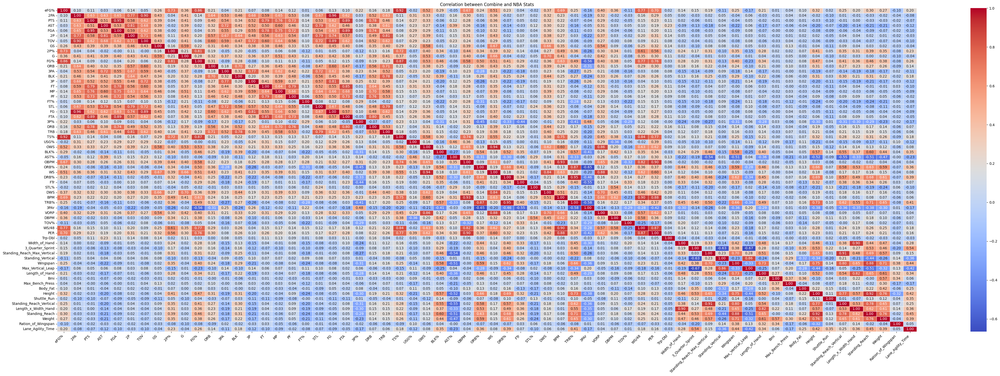

In [221]:
plt.figure(figsize=(45, 15))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", 
            cmap="coolwarm", linewidths=0.5,
            xticklabels=correlation_matrix.columns,
            yticklabels=correlation_matrix.columns
            )

plt.title("Correlation between Combine and NBA Stats")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Correlation_between_Combine_and_NBA_Stats.png") 
plt.show()

In [222]:
# Drop self-correlations and flatten
corr_long = (
    correlation_matrix
    .unpivot(
        variable_name="Feature1",
        value_name="Correlation"
    ).with_columns([
        pl.repeat(correlation_matrix.columns, correlation_matrix.height).explode().alias("Feature2")
    ])

)
corr_filtered = (
    corr_long
    .filter(pl.col("Feature1") != pl.col("Feature2")) # remove self pairs
    .filter(pl.col("Feature1") < pl.col("Feature2")) # locks in on upper triangle
)

top_corr = corr_filtered.with_columns(
    pl.col("Correlation").abs().alias("AbsCorrelation")
)
# Absolute value and threshold
top_corr = top_corr.filter(top_corr["AbsCorrelation"] > 0.5)

top_corr

Feature1,Correlation,Feature2,AbsCorrelation
str,f64,str,f64
"""2PA""",0.631952,"""PTS""",0.631952
"""2PA""",0.628109,"""AST""",0.628109
"""2PA""",0.646309,"""FGA""",0.646309
"""2PA""",0.903426,"""TOV""",0.903426
"""2PA""",0.644959,"""ORB""",0.644959
…,…,…,…
"""Standing_Reach""",0.685468,"""Standing_Reach_Max_Vertical""",0.685468
"""Standing_Reach""",0.879329,"""Wingspan""",0.879329
"""Standing_Reach""",0.780195,"""Standing_Reach_Vertical""",0.780195


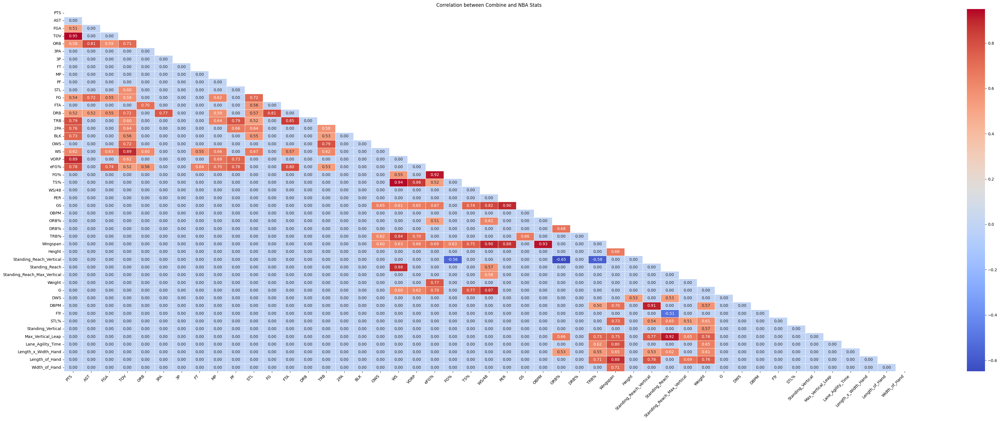

In [223]:
pivot_corr = top_corr.pivot(index="Feature1", on="Feature2", values="Correlation").drop("Feature1")
pivot_corr = pivot_corr.fill_null(0)
mask = np.triu(np.ones_like(pivot_corr, dtype=bool))

plt.figure(figsize=(40, 15))
sns.heatmap(pivot_corr, annot=True, fmt=".2f", 
            cmap="coolwarm", linewidths=0.5,
            xticklabels=pivot_corr.columns,
            yticklabels=pivot_corr.columns,
            mask=mask
            )

plt.title("Correlation between Combine and NBA Stats")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Correlation_between_Combine_and_NBA_Stats_50pct_Threshold.png")
plt.show()

In [224]:
combine_wide.columns

['Player_Season',
 'Width_of_Hand',
 '3_Quarter_Sprint',
 'Standing_Reach_Max_Vertical',
 'Standing_Vertical',
 'Wingspan',
 'Max_Vertical_Leap',
 'Length_of_Hand',
 'Bmi',
 'Max_Bench_Press',
 'Body_Fat',
 'Height',
 'Shuttle_Run',
 'Standing_Reach_Vertical',
 'Length_x_Width_Hand',
 'Standing_Reach',
 'Weight',
 'Ration_of_Wingspan',
 'Lane_Agility_Time']

In [225]:
top_10_corr = top_corr.filter(
    pl.col("Feature2").is_in(combine_wide.columns) & ~pl.col("Feature1").is_in(combine_wide.columns)
).sort("AbsCorrelation", descending=True).head(10)
top_10_corr

Feature1,Correlation,Feature2,AbsCorrelation
str,f64,str,f64
"""DRB%""",0.690049,"""Height""",0.690049
"""DRB%""",0.675119,"""Standing_Reach""",0.675119
"""TRB%""",0.66212,"""Wingspan""",0.66212
"""TRB%""",0.654096,"""Weight""",0.654096
"""ORB%""",0.627057,"""Standing_Reach""",0.627057
"""DRB%""",0.621384,"""Wingspan""",0.621384
"""DRB%""",0.611113,"""Weight""",0.611113
"""BLK%""",0.604842,"""Standing_Reach""",0.604842
"""ORB%""",0.593768,"""Wingspan""",0.593768


# Visualizing Relationships Between NBA Combine and NBA Performance Stats

This section explores how physical attributes measured at the NBA Draft Combine relate to key NBA performance metrics. Using scatterplots and pairplots, we visualize the strongest correlations between combine stats (such as Height, Wingspan, Standing Reach, and Weight) and NBA outcomes (including Total Rebound %, Defensive Rebound %, Offensive Rebound %, and Block %).

**Key analyses include:**
- Pairwise scatterplots for the top 10 most correlated combine/NBA stat pairs.
- Regression lines and correlation coefficients to highlight linear relationships.
- Focused scatterplots for specific relationships, such as Height vs. Defensive Rebound %, Standing Reach vs. Defensive Rebound %, and Total Rebound % vs. Height.

These visualizations help reveal which physical traits are most predictive of NBA performance, providing actionable insights for scouting and player development.

In [226]:
combined_wide.head()

eFG%,2PA,PTS,AST,FGA,2P,TOV,GS,2P%,G,FG%,ORB,3PA,BLK,3P,FT,MP,PF,FT%,STL,FG,FTA,3P%,DRB,TRB,TS%,USG%,OWS,BLK%,AST%,OBPM,ORB%,WS,DRB%,FTr,STL%,DWS,BPM,TRB%,3PAr,VORP,DBPM,TOV%,WS/48,PER,Trp-Dbl,Width_of_Hand,3_Quarter_Sprint,Standing_Reach_Max_Vertical,Standing_Vertical,Wingspan,Max_Vertical_Leap,Length_of_Hand,Bmi,Max_Bench_Press,Body_Fat,Height,Shuttle_Run,Standing_Reach_Vertical,Length_x_Width_Hand,Standing_Reach,Weight,Ration_of_Wingspan,Lane_Agility_Time,Player,Season
f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,str,str
0.526,118.0,5.5,1.3,3.9,1.8,23.0,3.0,0.542,35.0,0.507,0.9,0.5,0.3,5.0,1.4,15.6,1.3,0.653,0.9,69.0,2.1,0.278,2.2,3.1,0.568,15.6,0.9,1.5,11.8,0.4,6.4,1.8,15.4,0.551,2.9,0.9,2.8,11.1,0.132,0.7,2.3,12.0,0.157,16.1,0.0,null,3.29,139.5,29.5,86.0,32.0,null,22.6,8.0,0.08,79.0,null,137.0,null,107.5,201.0,1.089,11.63,"""Trevor Ariza""","""2007-08"""
0.502,8.2,9.8,1.4,8.2,4.1,118.0,35.0,0.504,78.0,0.502,254.0,0.0,0.8,0.0,1.6,28.5,3.2,0.737,0.6,322.0,2.1,0.0,6.1,9.4,0.537,16.200001,2.2,1.9,7.9,-1.2,12.5,4.5,23.299999,0.261,1.1,2.3,-1.4,17.9,0.003,0.3,-0.2,14.2,0.098,15.0,0.0,null,3.28,141.0,28.0,85.5,33.0,null,27.5,8.0,0.17,80.75,null,136.0,null,108.0,255.0,1.059,11.62,"""Nick Collison""","""2007-08"""
0.517,4.4,9.0,0.9,589.0,1.8,0.7,18.0,0.422,80.0,0.428,0.4,3.0,0.2,1.3,1.4,2016.0,2.3,0.804,0.6,3.2,138.0,0.436,193.0,2.8,0.554,16.1,1.9,0.7,5.8,-1.2,1.9,3.0,11.1,0.234,1.2,1.0,-2.0,6.4,0.409,0.0,-0.8,8.2,0.071,10.7,0.0,null,3.35,132.0,29.0,78.5,33.5,null,24.5,13.0,0.067,77.0,null,127.5,null,98.5,207.0,1.019,11.11,"""Matt Carroll""","""2007-08"""
0.567,7.7,12.0,1.8,8.3,343.0,0.9,76.0,0.587,76.0,0.558,1.3,0.7,0.3,0.1,2.6,27.5,1.4,0.759,129.0,4.7,3.4,0.22,1.6,218.0,0.612,17.5,5.4,0.7,9.7,2.2,5.7,7.8,7.0,0.405,3.2,2.4,3.8,6.4,0.079,3.1,1.6,8.5,0.178,18.4,0.0,null,3.14,144.5,35.0,83.25,41.0,null,25.9,19.0,0.05,77.75,null,138.5,null,103.5,223.0,1.071,11.32,"""Ronnie Brewer""","""2007-08"""
0.388,1.0,88.0,0.8,2.0,0.3,0.5,9.0,0.292,48.0,0.309,0.5,1.0,0.2,0.3,0.3,512.0,1.3,0.75,0.2,0.6,20.0,0.326,57.0,1.6,0.428,11.7,-0.3,1.3,11.2,-3.8,5.4,0.6,12.5,0.213,0.9,0.9,-2.8,9.2,0.489,-0.1,1.0,20.200001,0.057,5.1,0.0,null,3.47,136.0,27.0,81.75,30.5,null,26.0,14.0,0.136,80.75,null,132.5,null,105.5,241.0,1.012,11.75,"""Brian Scalabrine""","""2007-08"""


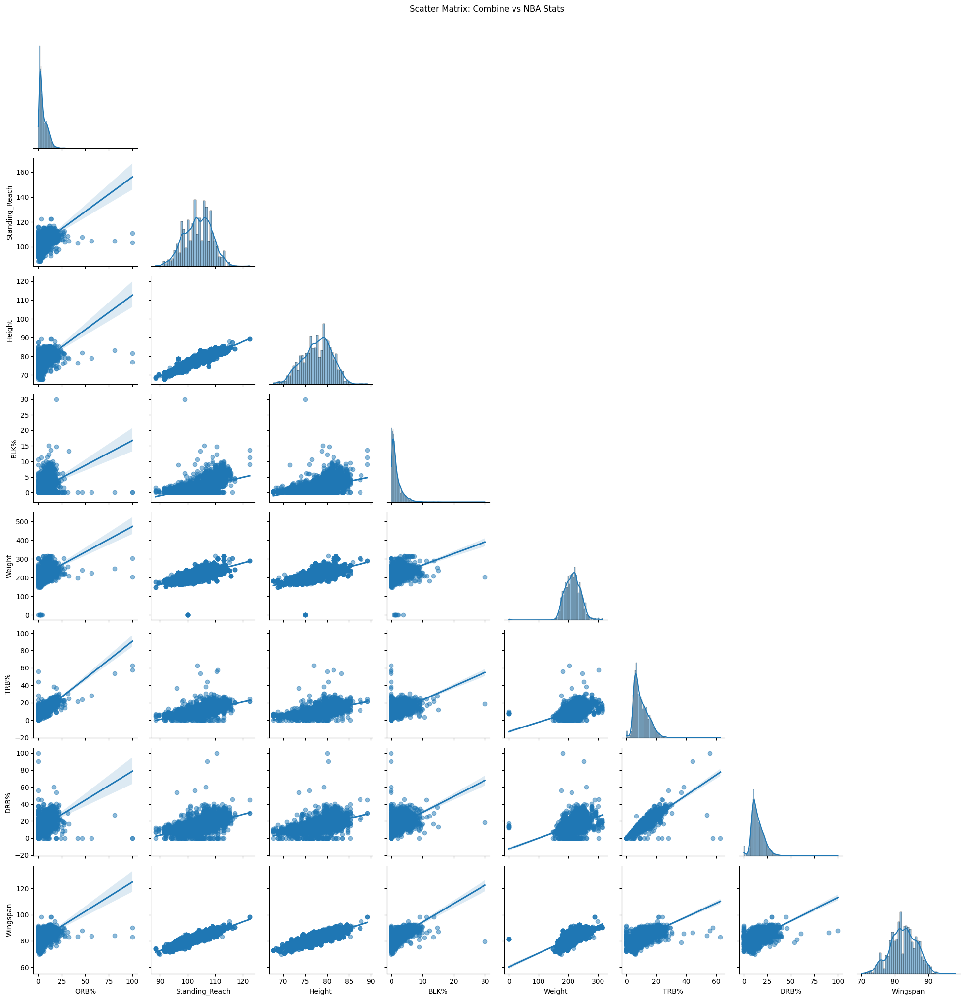

In [227]:
def corrfunc(x, y, **kws):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.annotate(f"r = {r:.2f}", xy=(.5, .5), xycoords=ax.transAxes,
                ha='center', va='center', fontsize=10)


# Make a pairplot between top 10 correlated features
features_to_plot = (
    pl.concat([
        top_10_corr["Feature1"].alias("value"),
        top_10_corr["Feature2"].alias("value")
    ], how="vertical")
    .unique()
    .to_list()
)

g = sns.PairGrid(combined_wide[features_to_plot].to_pandas(), corner=True)
g.map_lower(sns.regplot, scatter_kws={'alpha': 0.5})
g.map_diag(sns.histplot, kde=True)
g.map_upper(corrfunc)
plt.suptitle("Scatter Matrix: Combine vs NBA Stats", y=1.02)
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Scatter_Matrix_Combine_vs_NBA_Stats.png")
plt.show()

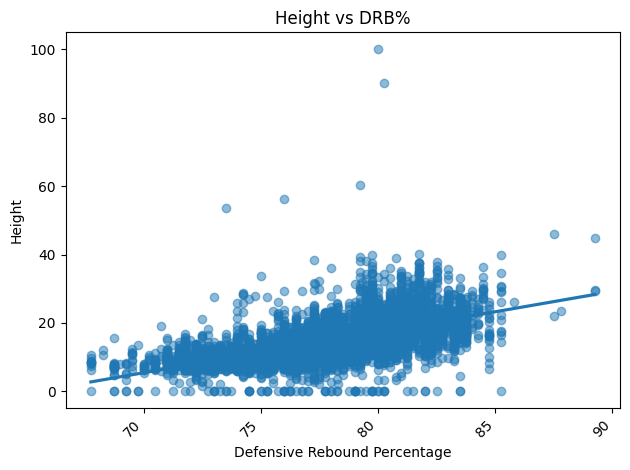

In [228]:
sns.regplot(data=combined_wide, x="Height", y="DRB%", scatter_kws={"alpha":0.5})
plt.title("Height vs DRB%")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.ylabel("Height")
plt.xlabel("Defensive Rebound Percentage")
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Height_vs_DRB_Percentage.png")
plt.show()


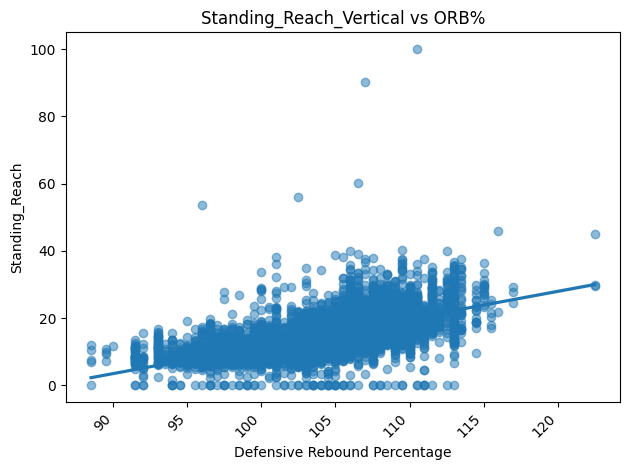

In [229]:
sns.regplot(data=combined_wide, x="Standing_Reach", y="DRB%", scatter_kws={"alpha":0.5})
plt.title("Standing_Reach_Vertical vs ORB%")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.ylabel("Standing_Reach")
plt.xlabel("Defensive Rebound Percentage")
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Standing_Reach_vs_DRB_Percentage.png")
plt.show()

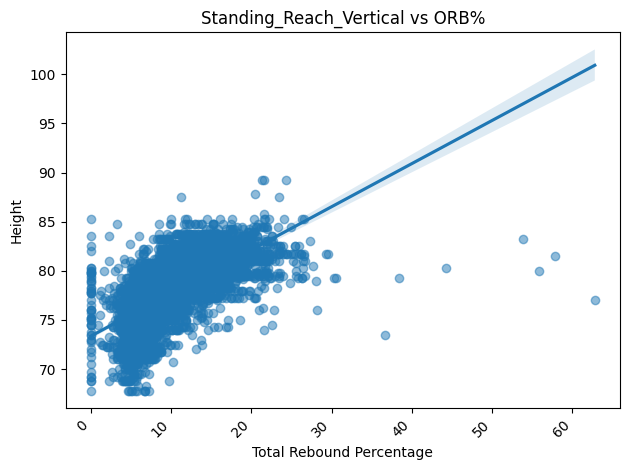

In [230]:
sns.regplot(data=combined_wide, x="TRB%", y="Height", scatter_kws={"alpha":0.5})
plt.title("Standing_Reach_Vertical vs ORB%")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.ylabel("Height")
plt.xlabel("Total Rebound Percentage")
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "TRB_Percentage_vs_Height.png")
plt.show()

# We have our columns that are strongly correlated! Let's dig deeper

We want to compare our physical attributes with top performers. Below, we use boxplots to visualize outliers and distributions for key combine metrics that show strong correlations with NBA performance. Specifically, we focus on attributes like Wingspan, Height, Standing Reach, Weight, and their relationships with rebounding and block percentages (TRB%, DRB%, ORB%, BLK%).

The following analysis uses the `top_performers` dataframe, which includes players' combine stats and flags for "Height Above Median", "Wingspan Above Median", "Standing Reach Above Median". By splitting the data on these flags, we can see how physical advantages translate to on-court performance.

Boxplots below illustrate:
- Block Percentage (BLK%) by Height Above Median
- Offensive Rebound Percentage (ORB%) by Height Above Median
- Defensive Rebound Percentage (DRB%) by Height Above Median
- Total Rebound Percentage (TRB%) by Height Above Median
- Defensive/Offensive/Total Rebound Percentage and Block Percentage by Wingspan Above Median
- Defensive/Offensive/Total Rebound Percentage and Block Percentage by Standing Reach Above Median

These visualizations help highlight how standout physical traits are associated with higher performance in key NBA metrics.

In [231]:
top_performers = combined_wide[features_to_plot + ["Player", "Season"]]
top_performers = top_performers.with_columns([
    (pl.col("Height") > top_performers["Height"].median()).alias("Height Above Median"),
    (pl.col("Wingspan") > top_performers["Wingspan"].median()).alias("Wingspan Above Median"),
    (pl.col("Standing_Reach") > top_performers["Standing_Reach"].median()).alias("Standing Reach Above Median"),
])

In [232]:
def plot_box_by_group(df, x, y, title, fig_name, figsize=(20, 10), folder_name="bivariate_nba"):
    plt.figure(figsize=figsize)
    sns.boxplot(x=x, y=y, data=df, 
                palette="pastel",
                hue=x)

    plt.title(title)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    temp = visualization_path / folder_name
    temp.mkdir(parents=True, exist_ok=True)
    plt.savefig(temp / fig_name)
    plt.show()

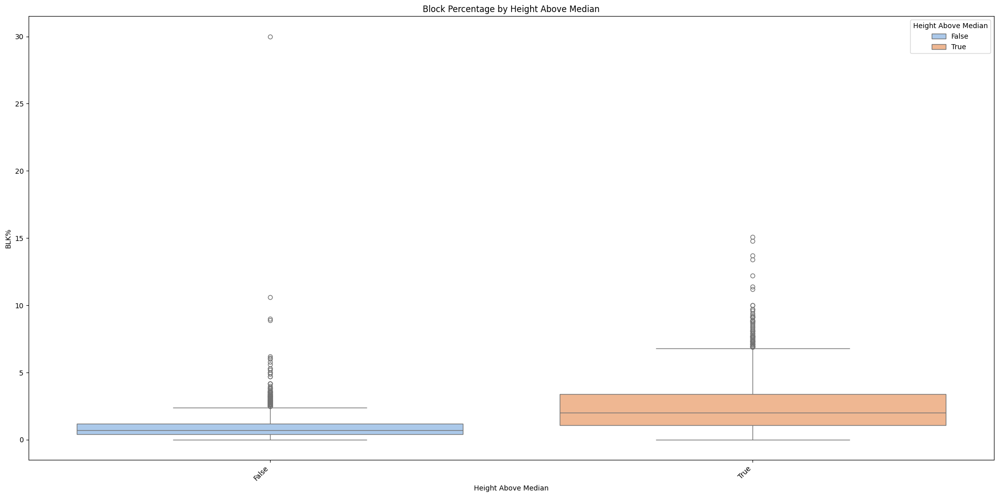

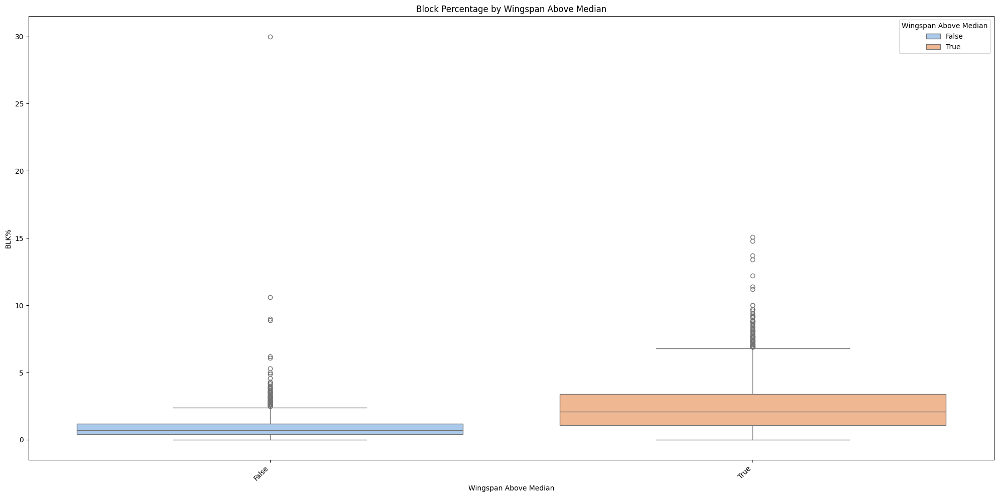

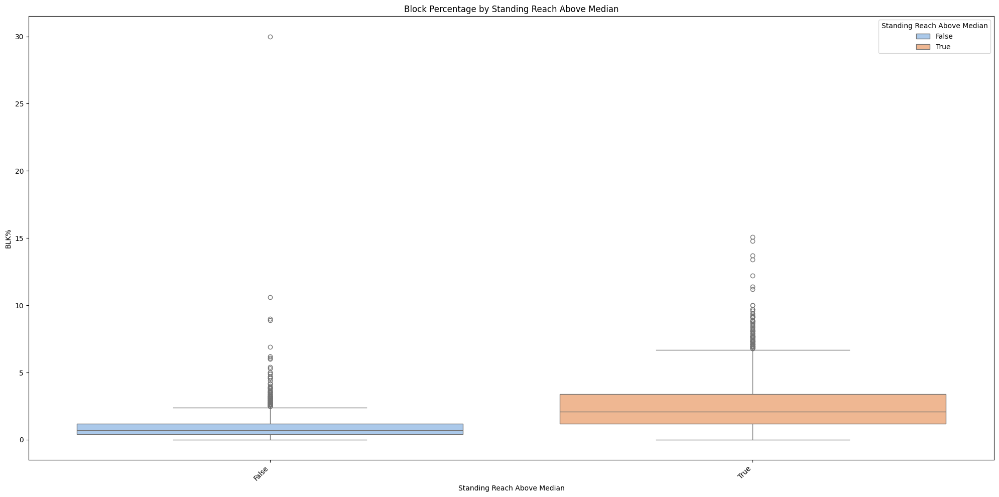

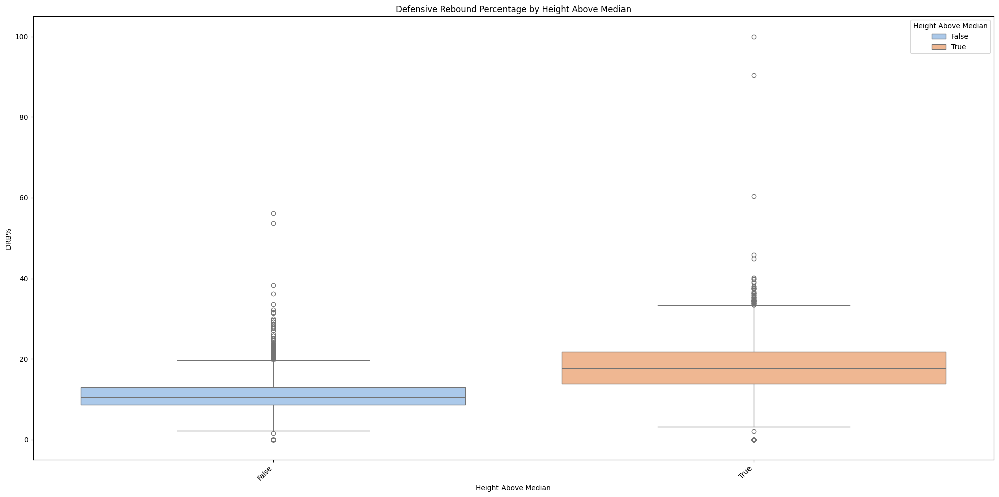

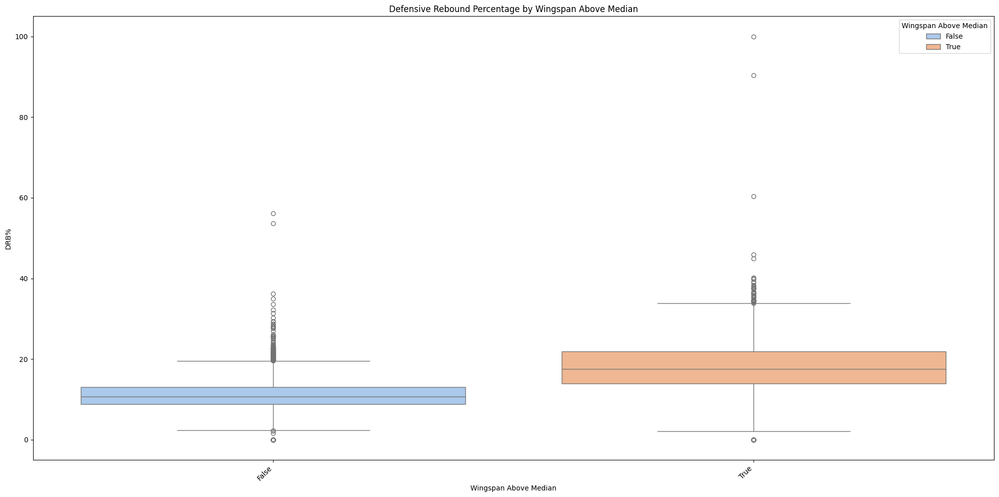

...

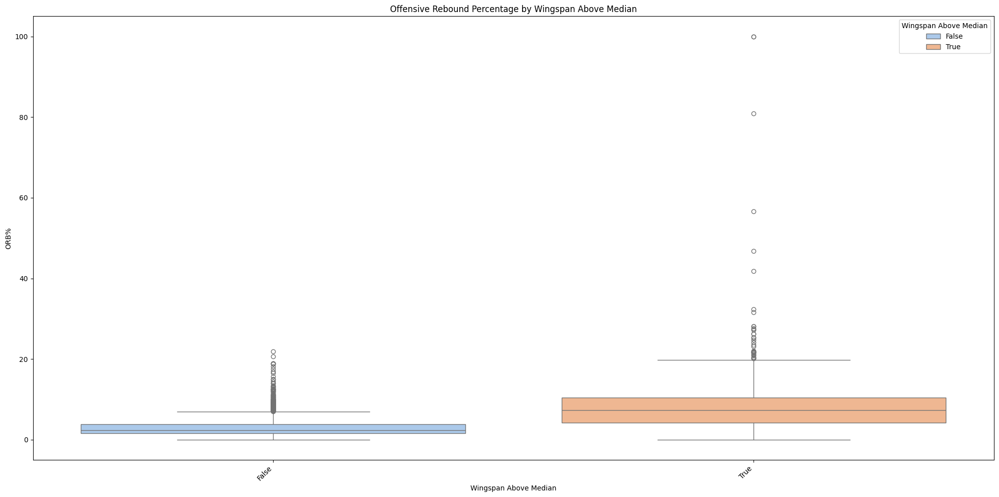

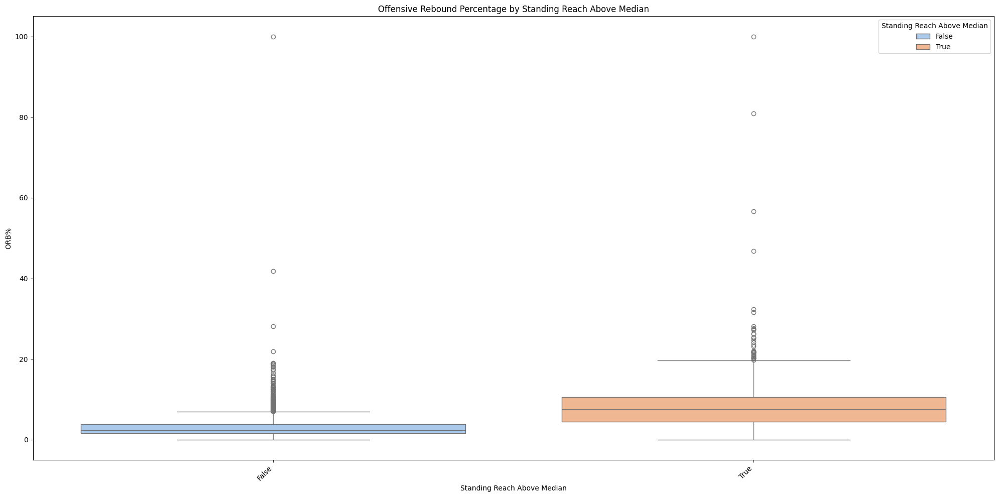

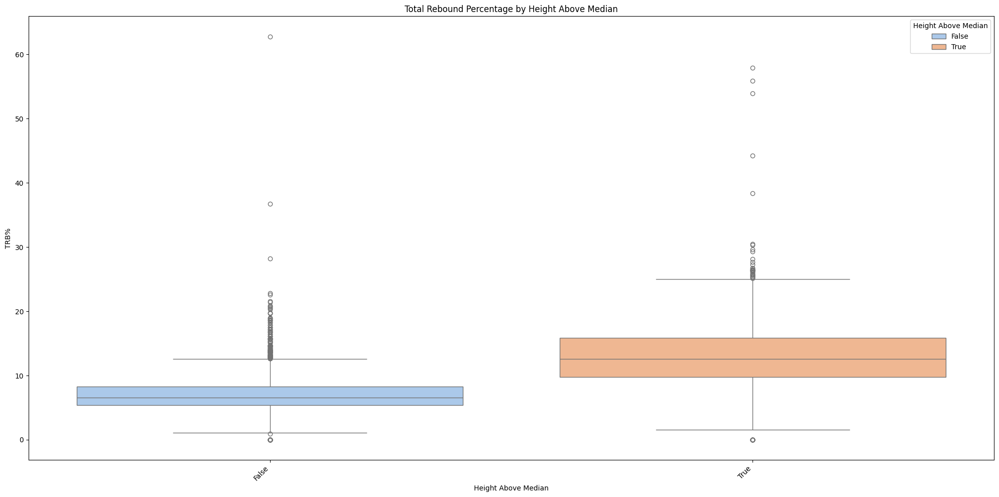

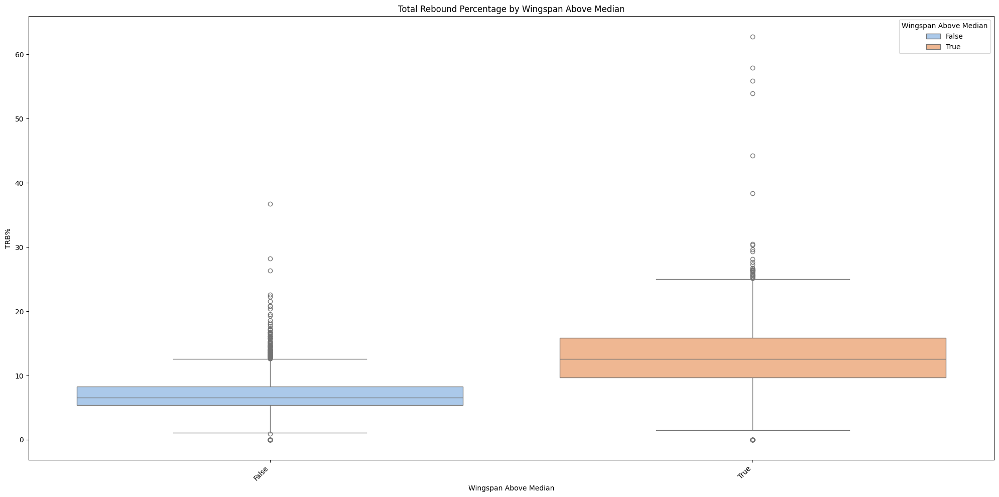

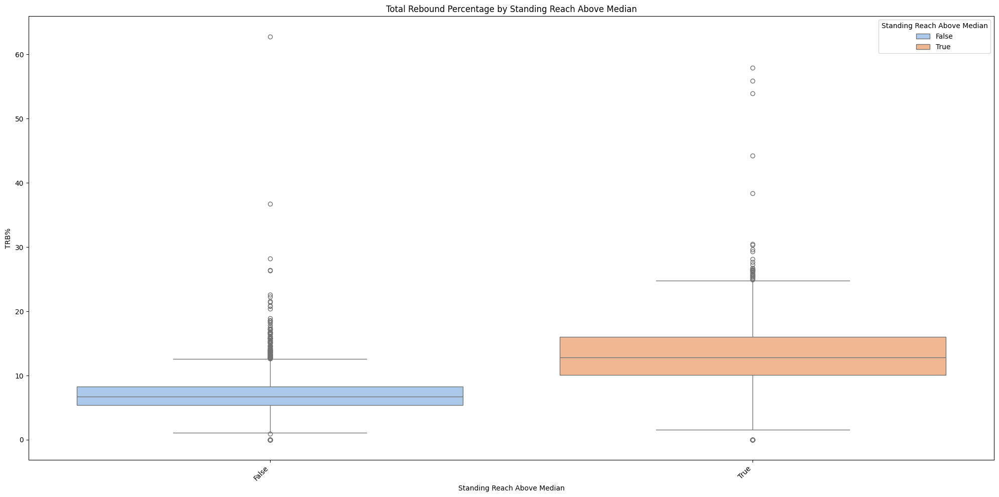

In [233]:
plotting_dict = {
    "Block Percentage by Height Above Median": {
        "x": "Height Above Median",
        "y": "BLK%",
        "title": "Block Percentage by Height Above Median",
        "fig_name": "Block_Percentage_by_Height_Above_Median.png"
    },
    "Block Percentage by Wingspan Above Median": {
        "x": "Wingspan Above Median",
        "y": "BLK%",
        "title": "Block Percentage by Wingspan Above Median",
        "fig_name": "Block_Percentage_by_Wingspan_Above_Median.png"
    },
    "Block Percentage by Standing Reach Above Median": {
        "x": "Standing Reach Above Median",
        "y": "BLK%",
        "title": "Block Percentage by Standing Reach Above Median",
        "fig_name": "Block_Percentage_by_Standing_Reach_Above_Median.png"
    },
    "Defensive Rebound Percentage by Height Above Median": {
        "x": "Height Above Median",
        "y": "DRB%",
        "title": "Defensive Rebound Percentage by Height Above Median",
        "fig_name": "Defensive_Rebound_Percentage_by_Height_Above_Median.png"
    },
    "Defensive Rebound Percentage by Wingspan Above Median": {
        "x": "Wingspan Above Median",
        "y": "DRB%",
        "title": "Defensive Rebound Percentage by Wingspan Above Median",
        "fig_name": "Defensive_Rebound_Percentage_by_Wingspan_Above_Median.png"
    },
    "Defensive Rebound Percentage by Standing Reach Above Median": {
        "x": "Standing Reach Above Median",
        "y": "DRB%",
        "title": "Defensive Rebound Percentage by Standing Reach Above Median",
        "fig_name": "Defensive_Rebound_Percentage_by_Standing_Reach_Above_Median.png"
    },
    "Offensive Rebound Percentage by Height Above Median": {
        "x": "Height Above Median",
        "y": "ORB%",
        "title": "Offensive Rebound Percentage by Height Above Median",
        "fig_name": "Offensive_Rebound_Percentage_by_Height_Above_Median.png"
    },
    "Offensive Rebound Percentage by Wingspan Above Median": {
        "x": "Wingspan Above Median",
        "y": "ORB%",
        "title": "Offensive Rebound Percentage by Wingspan Above Median",
        "fig_name": "Offensive_Rebound_Percentage_by_Wingspan_Above_Median.png"
    },
    "Offensive Rebound Percentage by Standing Reach Above Median": {
        "x": "Standing Reach Above Median",
        "y": "ORB%",
        "title": "Offensive Rebound Percentage by Standing Reach Above Median",
        "fig_name": "Offensive_Rebound_Percentage_by_Standing_Reach_Above_Median.png"
    },
    "Total Rebound Percentage by Height Above Median": {
        "x": "Height Above Median",
        "y": "TRB%",
        "title": "Total Rebound Percentage by Height Above Median",
        "fig_name": "Total_Rebound_Percentage_by_Height_Above_Median.png"
    },
    "Total Rebound Percentage by Wingspan Above Median": {
        "x": "Wingspan Above Median",
        "y": "TRB%",
        "title": "Total Rebound Percentage by Wingspan Above Median",
        "fig_name": "Total_Rebound_Percentage_by_Wingspan_Above_Median.png"
    },
    "Total Rebound Percentage by Standing Reach Above Median": {
        "x": "Standing Reach Above Median",
        "y": "TRB%",
        "title": "Total Rebound Percentage by Standing Reach Above Median",
        "fig_name": "Total_Rebound_Percentage_by_Standing_Reach_Above_Median.png"
    }

}

for plot_name, plot_info in plotting_dict.items():
    plot_box_by_group(
        df=top_performers.drop_nulls(),
        x=plot_info["x"],
        y=plot_info["y"],
        title=plot_info["title"],
        fig_name=plot_info["fig_name"],
        folder_name="bivariate_nba"
    )

In [234]:
from scipy.stats import ttest_ind, mannwhitneyu, pearsonr

def stat_tests_combine_vs_nba(df, combine_features, nba_features):
    """
    Perform statistical tests (t-test, Mann-Whitney, Pearson correlation)
    for each pair of combine stat and NBA stat.
    Returns a Polars DataFrame with results.
    """
    results = []
    for combine_col in combine_features:
        for nba_col in nba_features:
            x = df.select(combine_col).drop_nulls().to_numpy()
            y = df.select(nba_col).drop_nulls().to_numpy()
            # Only run if both columns have >1 non-null values
            if len(x) > 1 and len(y) > 1:
                # Align lengths for tests (use intersection of non-null indices)
                mask = (~df[combine_col].is_null()) & (~df[nba_col].is_null())
                x_aligned = df[combine_col].filter(mask).to_numpy()
                y_aligned = df[nba_col].filter(mask).to_numpy()
                if len(x_aligned) > 1 and len(y_aligned) > 1:
                    t_stat, p_ttest = ttest_ind(x_aligned, y_aligned, nan_policy='omit')
                    u_stat, p_mw = mannwhitneyu(x_aligned, y_aligned, alternative='two-sided')
                    corr, _ = pearsonr(x_aligned, y_aligned)
                    results.append({
                        "combine_stat": combine_col,
                        "nba_stat": nba_col,
                        "t_stat": t_stat,
                        "p_value_ttest": p_ttest,
                        "u_stat": u_stat,
                        "p_value_mannwhitney": p_mw,
                        "pearson_corr": corr
                    })
    return pl.from_dicts(results)

# Example usage:
# nba_stat_cols = top_10_corr["Feature1"].unique().to_list()
# combine_stat_cols = top_10_corr["Feature2"].unique().to_list()
nba_stat_cols = nba_wide.drop("Player_Season").columns
combine_stat_cols = combine_wide.drop("Player_Season").columns

stat_tests_nba_vs_combine = stat_tests_combine_vs_nba(combined_wide, combine_stat_cols, nba_stat_cols)
# Getting 
stat_tests_nba_vs_combine = stat_tests_nba_vs_combine.sort(by=pl.col("pearson_corr").abs(), descending=True).filter((pl.col("p_value_ttest") < 0.05) & (pl.col("pearson_corr").abs() > 0.5))
display(stat_tests_nba_vs_combine)
display(stat_tests_nba_vs_combine["nba_stat"].unique().sort())
display(stat_tests_nba_vs_combine["combine_stat"].unique().sort())

combine_stat,nba_stat,t_stat,p_value_ttest,u_stat,p_value_mannwhitney,pearson_corr
str,str,f64,f64,f64,f64,f64
"""Standing_Reach""","""TRB%""",1046.523751,0.0,3.5557369e7,0.0,0.666231
"""Height""","""TRB%""",886.003595,0.0,3.5557369e7,0.0,0.655619
"""Wingspan""","""TRB%""",891.559364,0.0,3.5700625e7,0.0,0.650975
"""Standing_Reach""","""DRB%""",847.35986,0.0,3.5556e7,0.0,0.61129
"""Height""","""DRB%""",669.894966,0.0,3.5545443e7,0.0,0.601812
…,…,…,…,…,…,…
"""Standing_Reach_Vertical""","""AST%""",867.78174,0.0,2.7499536e7,0.0,-0.52404
"""Standing_Reach_Max_Vertical""","""TRB%""",1431.164418,0.0,2.7384289e7,0.0,0.519501
"""Weight""","""DRB%""",568.10282,0.0,3.5456e7,0.0,0.518962


nba_stat
str
"""AST%"""
"""BLK%"""
"""DRB%"""
"""ORB%"""
"""TRB%"""


combine_stat
str
"""Height"""
"""Standing_Reach"""
"""Standing_Reach_Max_Vertical"""
"""Standing_Reach_Vertical"""
"""Weight"""
"""Wingspan"""


### Insights from Statistical Tests: Combine Stats vs NBA Performance

The statistical tests performed above provide strong evidence that key physical attributes measured at the NBA Draft Combine are both highly correlated and statistically significant predictors of NBA performance metrics:

- **Standing Reach, Height, and Wingspan:** These combine metrics show the strongest positive correlations with NBA rebounding stats (TRB%, DRB%, ORB%) and block percentage (BLK%). For example, Standing Reach and TRB% (r ≈ 0.67), Height and TRB% (r ≈ 0.66), and Wingspan and TRB% (r ≈ 0.65) all have high correlation coefficients and extremely low p-values, confirming their predictive power.
- **Weight:** Also displays strong associations with rebounding metrics, reinforcing the importance of size and mass for interior play.
- **Statistical Significance:** All top combine-NBA stat pairs have p-values near zero for both t-tests and Mann-Whitney tests, indicating that these relationships are highly unlikely to be due to chance.
- **Negative Correlations:** Some combine metrics, such as Standing Reach Vertical and AST%, show significant negative correlations, suggesting that certain physical traits may be inversely related to specific performance outcomes.
- **Implications for Scouting and Player Development:** These results validate the use of combine measurements in forecasting NBA success, especially for roles that require rebounding and shot-blocking. Players with above-median height, wingspan, and standing reach consistently outperform their peers in these critical areas.

**Conclusion:**  
Physical attributes measured at the NBA Draft Combine are robust, statistically significant indicators of NBA performance, particularly in rebounding and defense. These findings support their use in player evaluation, draft strategy, and long-term development planning.

## Time to Compare with NBA Awards

Below we make some boxplots to see how the physical combine stats relate to the NBA awards.

We will visualize how key combine metrics (Height, Wingspan, Standing Reach, Weight) are distributed among players who received NBA accolades such as All-Star selections, All-NBA Team, Defensive Team, and MVP/DPOY rankings. These plots help reveal whether standout physical attributes are associated with higher chances of earning major NBA honors.

The following analysis uses the `combined_award` dataframe, which merges combine stats with award indicators for each player-season. For each award category, we compare the distributions of combine metrics between award recipients and non-recipients using boxplots.

**Key questions addressed:**
- Do All-Stars tend to have higher combine measurements?
- Are Defensive Team or All-NBA Team members physically different from the rest?
- How do MVP and DPOY rankings relate to combine stats?

This section provides a visual summary of how physical traits may influence or correlate with NBA recognition.

In [235]:
awards = df.collect().select([
    "Player", "Season", "AllStar", "Defense_Team", "MVP_Rank", "All_NBA_Team", "DPOY_Rank"
]).unique(subset=["Player", "Season"])

combined_award = combined_wide.join(awards, on=["Player", "Season"], how="left")
combined_award

eFG%,2PA,PTS,AST,FGA,2P,TOV,GS,2P%,G,FG%,ORB,3PA,BLK,3P,FT,MP,PF,FT%,STL,FG,FTA,3P%,DRB,TRB,TS%,USG%,OWS,BLK%,AST%,OBPM,ORB%,WS,DRB%,FTr,STL%,DWS,BPM,TRB%,3PAr,VORP,DBPM,TOV%,WS/48,PER,Trp-Dbl,Width_of_Hand,3_Quarter_Sprint,Standing_Reach_Max_Vertical,Standing_Vertical,Wingspan,Max_Vertical_Leap,Length_of_Hand,Bmi,Max_Bench_Press,Body_Fat,Height,Shuttle_Run,Standing_Reach_Vertical,Length_x_Width_Hand,Standing_Reach,Weight,Ration_of_Wingspan,Lane_Agility_Time,Player,Season,AllStar,Defense_Team,MVP_Rank,All_NBA_Team,DPOY_Rank
f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,str,str,bool,i32,i32,i32,i32
0.526,118.0,5.5,1.3,3.9,1.8,23.0,3.0,0.542,35.0,0.507,0.9,0.5,0.3,5.0,1.4,15.6,1.3,0.653,0.9,69.0,2.1,0.278,2.2,3.1,0.568,15.6,0.9,1.5,11.8,0.4,6.4,1.8,15.4,0.551,2.9,0.9,2.8,11.1,0.132,0.7,2.3,12.0,0.157,16.1,0.0,null,3.29,139.5,29.5,86.0,32.0,null,22.6,8.0,0.08,79.0,null,137.0,null,107.5,201.0,1.089,11.63,"""Trevor Ariza""","""2007-08""",false,0,0,0,0
0.502,8.2,9.8,1.4,8.2,4.1,118.0,35.0,0.504,78.0,0.502,254.0,0.0,0.8,0.0,1.6,28.5,3.2,0.737,0.6,322.0,2.1,0.0,6.1,9.4,0.537,16.200001,2.2,1.9,7.9,-1.2,12.5,4.5,23.299999,0.261,1.1,2.3,-1.4,17.9,0.003,0.3,-0.2,14.2,0.098,15.0,0.0,null,3.28,141.0,28.0,85.5,33.0,null,27.5,8.0,0.17,80.75,null,136.0,null,108.0,255.0,1.059,11.62,"""Nick Collison""","""2007-08""",false,0,0,0,0
0.517,4.4,9.0,0.9,589.0,1.8,0.7,18.0,0.422,80.0,0.428,0.4,3.0,0.2,1.3,1.4,2016.0,2.3,0.804,0.6,3.2,138.0,0.436,193.0,2.8,0.554,16.1,1.9,0.7,5.8,-1.2,1.9,3.0,11.1,0.234,1.2,1.0,-2.0,6.4,0.409,0.0,-0.8,8.2,0.071,10.7,0.0,null,3.35,132.0,29.0,78.5,33.5,null,24.5,13.0,0.067,77.0,null,127.5,null,98.5,207.0,1.019,11.11,"""Matt Carroll""","""2007-08""",false,0,0,0,0
0.567,7.7,12.0,1.8,8.3,343.0,0.9,76.0,0.587,76.0,0.558,1.3,0.7,0.3,0.1,2.6,27.5,1.4,0.759,129.0,4.7,3.4,0.22,1.6,218.0,0.612,17.5,5.4,0.7,9.7,2.2,5.7,7.8,7.0,0.405,3.2,2.4,3.8,6.4,0.079,3.1,1.6,8.5,0.178,18.4,0.0,null,3.14,144.5,35.0,83.25,41.0,null,25.9,19.0,0.05,77.75,null,138.5,null,103.5,223.0,1.071,11.32,"""Ronnie Brewer""","""2007-08""",false,0,0,0,0
0.388,1.0,88.0,0.8,2.0,0.3,0.5,9.0,0.292,48.0,0.309,0.5,1.0,0.2,0.3,0.3,512.0,1.3,0.75,0.2,0.6,20.0,0.326,57.0,1.6,0.428,11.7,-0.3,1.3,11.2,-3.8,5.4,0.6,12.5,0.213,0.9,0.9,-2.8,9.2,0.489,-0.1,1.0,20.200001,0.057,5.1,0.0,null,3.47,136.0,27.0,81.75,30.5,null,26.0,14.0,0.136,80.75,null,132.5,null,105.5,241.0,1.012,11.75,"""Brian Scalabrine""","""2007-08""",false,0,0,0,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.517,570.0,1057.0,1.6,883.0,3.8,76.0,17.0,0.493,73.0,0.451,1.0,4.3,0.2,117.0,144.0,1872.0,127.0,0.814,58.0,398.0,177.0,0.374,139.0,211.0,0.55,25.299999,3.1,0.4,10.3,2.3,4.4,4.0,8.9,0.2,1.6,0.9,0.9,6.6,0.354,1.4,-1.4,7.3,0.103,17.4,0.0,8.5,3.02,140.5,34.5,79.75,43.0,8.25,22.9,3.0,0.053,73.75,2.88,132.0,70.099998,97.5,177.399994,1.081,10.78,"""Marcus Thornton""","""2009-10""",false,0,0,0,0
0.472,193.0,494.0,378.0,451.0,78.0,110.0,59.0,0.404,67.0,0.373,28.0,258.0,3.0,90.0,68.0,2072.0,83.0,0.716,59.0,168.0,95.0,0.349,150.0,178.0,0.501,13.1,1.5,0.1,25.9,-1.2,1.5,1.9,8.4,0.211,1.5,0.5,-2.5,4.9,0.572,-0.3,-1.3,18.200001,0.045,10.7,0.0,null,3.14,133.0,31.5,78.5,35.0,null,26.200001,7.0,0.067,72.0,null,129.5,null,98.0,193.0,1.09,10.45,"""Chris Duhon""","""2009-10""",false,0,0,0,0
0.493,438.0,979.0,1.4,870.0,2.6,79.0,64.0,0.482,82.0,0.409,39.0,5.3,0.8,145.0,122.0,2702.0,121.0,0.841,0.4,356.0,145.0,0.336,201.0,2.9,0.524,17.0,1.8,1.9,6.8,-0.8,1.7,2.7,8.7,0.167,0.7,0.9,-1.9,5.1,0.497,0.1,-1.1,7.8,0.048,10.7,0.0,null,3.29,143.0,31.5,84.0,37.5,null,22.4,10.0,null,78.75,null,137.0,null,105.5,198.0,1.067,11.54,"""Rasual Butler""","""2009-10""",false,0,0,0,0


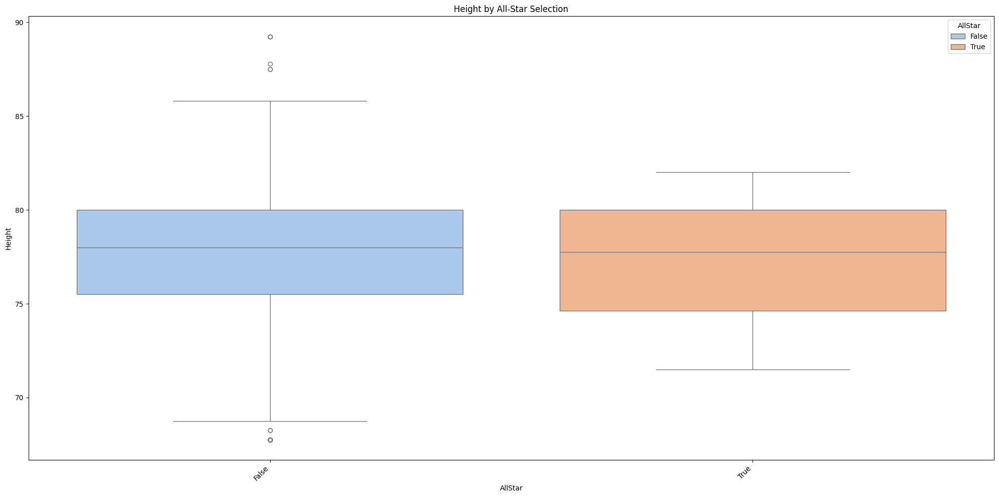

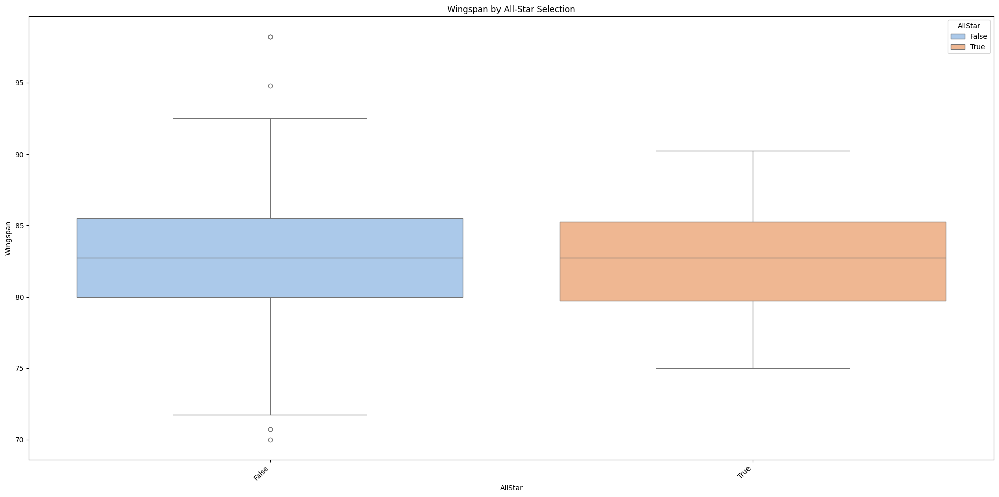

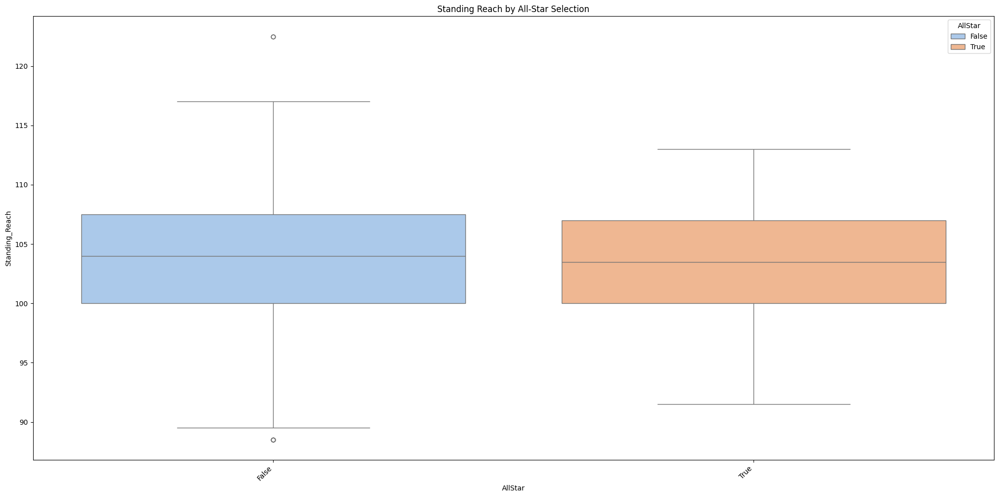

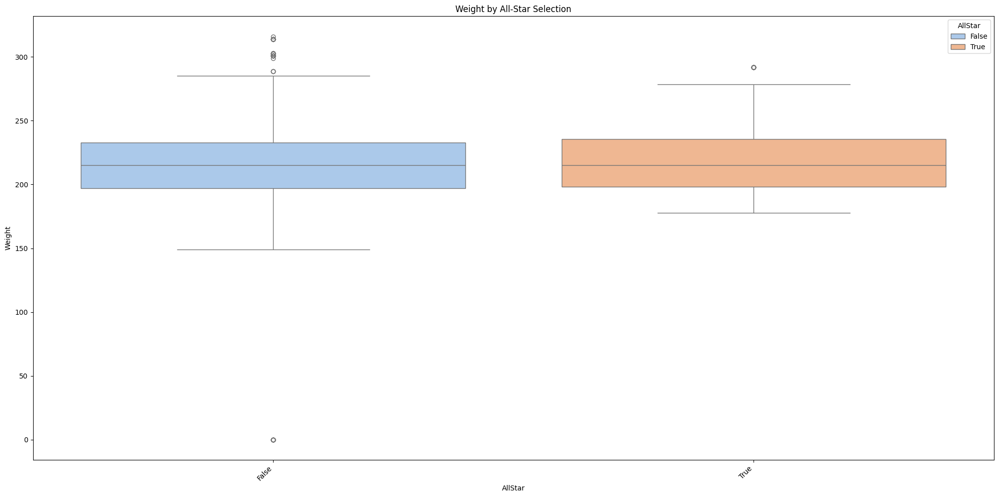

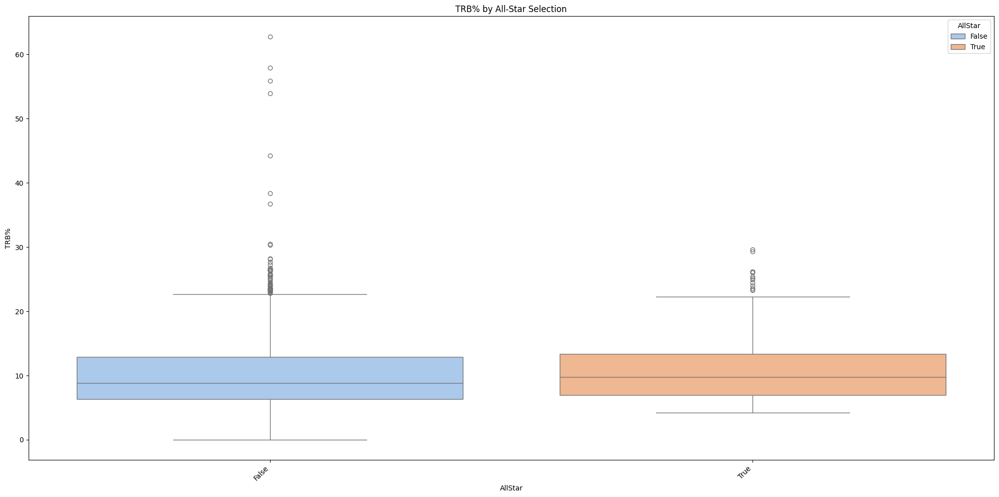

...

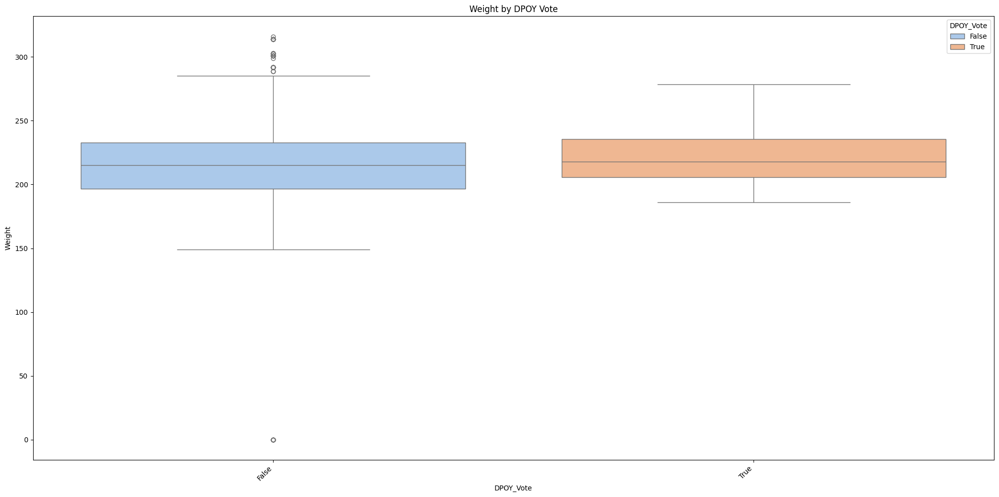

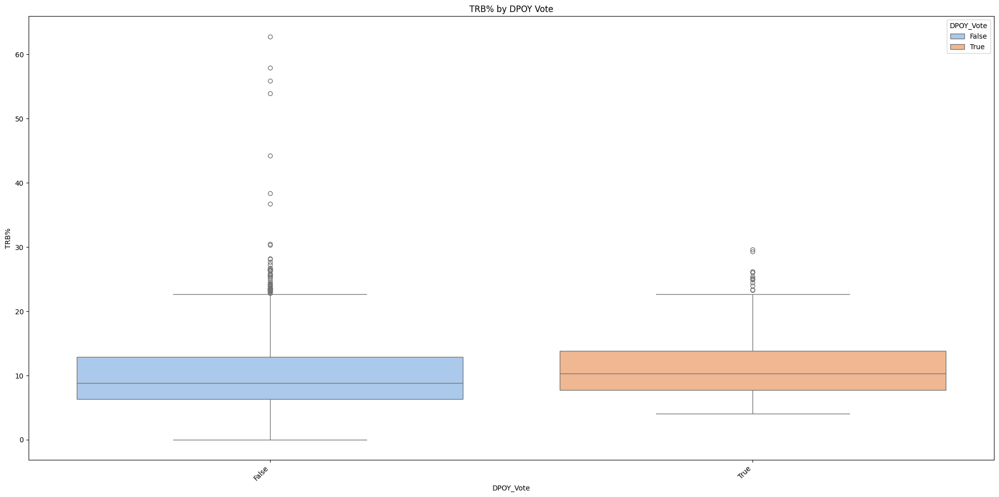

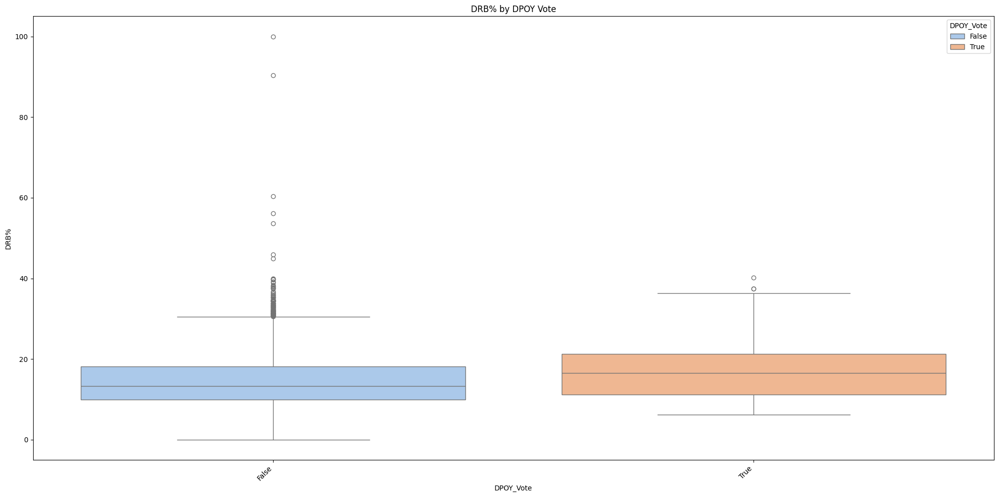

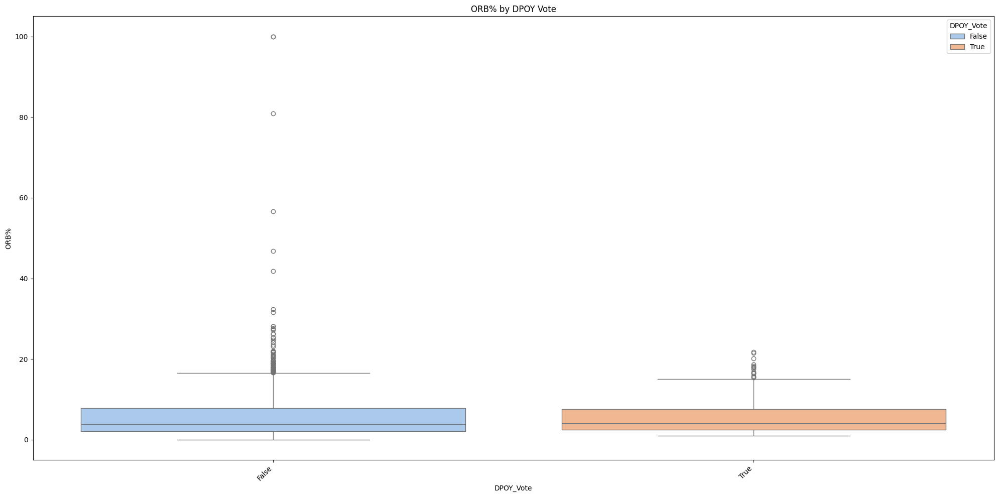

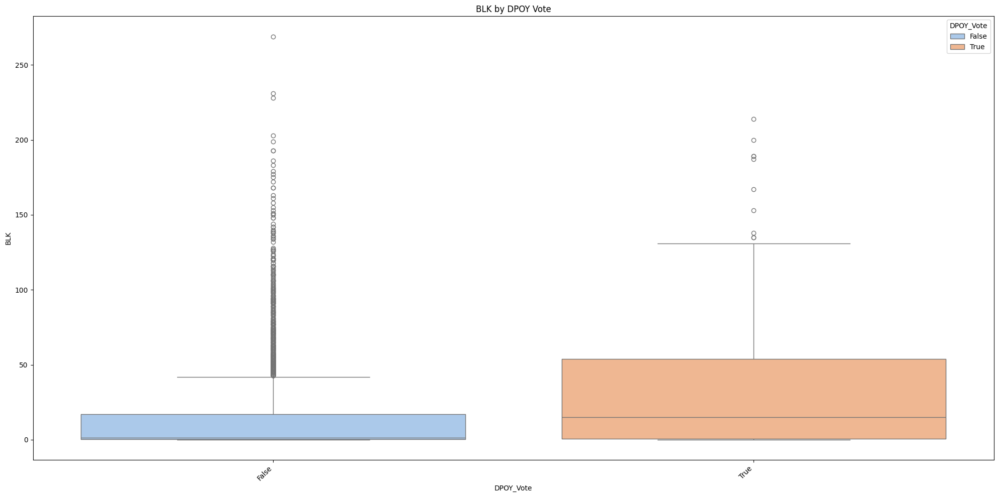

In [236]:
plotting_dict = {
    "Height by AllStar": {
        "x": "AllStar",
        "y": "Height",
        "title": "Height by All-Star Selection",
        "fig_name": "Height_by_AllStar.png"
    },
    "Wingspan by AllStar": {
        "x": "AllStar",
        "y": "Wingspan",
        "title": "Wingspan by All-Star Selection",
        "fig_name": "Wingspan_by_AllStar.png"
    },
    "Standing Reach by AllStar": {
        "x": "AllStar",
        "y": "Standing_Reach",
        "title": "Standing Reach by All-Star Selection",
        "fig_name": "Standing_Reach_by_AllStar.png"
    },
    "Weight by AllStar": {
        "x": "AllStar",
        "y": "Weight",
        "title": "Weight by All-Star Selection",
        "fig_name": "Weight_by_AllStar.png"
    },
    "TRB% by AllStar": {
        "x": "AllStar",
        "y": "TRB%",
        "title": "TRB% by All-Star Selection",
        "fig_name": "TRB%_by_AllStar.png"
    },
    "DRB% by AllStar": {
        "x": "AllStar",
        "y": "DRB%",
        "title": "DRB% by All-Star Selection",
        "fig_name": "DRB%_by_AllStar.png"
    },
    "ORB% by AllStar": {
        "x": "AllStar",
        "y": "ORB%",
        "title": "ORB% by All-Star Selection",
        "fig_name": "ORB%_by_AllStar.png"
    },
    "BLK by AllStar": {
        "x": "AllStar",
        "y": "BLK",
        "title": "BLK by All-Star Selection",
        "fig_name": "BLK_by_AllStar.png"
    },
    "Height by Defense Team": {
        "x": "Defense_Team",
        "y": "Height",
        "title": "Height by Defensive Team Selection",
        "fig_name": "Height_by_Defense_Team.png"
    },
    "Wingspan by Defense Team": {
        "x": "Defense_Team",
        "y": "Wingspan",
        "title": "Wingspan by Defensive Team Selection",
        "fig_name": "Wingspan_by_Defense_Team.png"
    },
    "Standing Reach by Defense Team": {
        "x": "Defense_Team",
        "y": "Standing_Reach",
        "title": "Standing Reach by Defensive Team Selection",
        "fig_name": "Standing_Reach_by_Defense_Team.png"
    },
    "Weight by Defense Team": {
        "x": "Defense_Team",
        "y": "Weight",
        "title": "Weight by Defensive Team Selection",
        "fig_name": "Weight_by_Defense_Team.png"
    },
    "TRB% by Defense Team": {
        "x": "Defense_Team",
        "y": "TRB%",
        "title": "TRB% by Defensive Team Selection",
        "fig_name": "TRB%_by_Defense_Team.png"
    },
    "DRB% by Defense Team": {
        "x": "Defense_Team",
        "y": "DRB%",
        "title": "DRB% by Defensive Team Selection",
        "fig_name": "DRB%_by_Defense_Team.png"
    },
    "ORB% by Defense Team": {
        "x": "Defense_Team",
        "y": "ORB%",
        "title": "ORB% by Defensive Team Selection",
        "fig_name": "ORB%_by_Defense_Team.png"
    },
    "BLK by Defense Team": {
        "x": "Defense_Team",
        "y": "BLK",
        "title": "BLK by Defensive Team Selection",
        "fig_name": "BLK_by_Defense_Team.png"
    },
    "Height by All NBA Team": {
        "x": "All_NBA_Team",
        "y": "Height",
        "title": "Height by All-NBA Team Selection",
        "fig_name": "Height_by_All_NBA_Team.png"
    },
    "Wingspan by All NBA Team": {
        "x": "All_NBA_Team",
        "y": "Wingspan",
        "title": "Wingspan by All-NBA Team Selection",
        "fig_name": "Wingspan_by_All_NBA_Team.png"
    },
    "Standing Reach by All NBA Team": {
        "x": "All_NBA_Team",
        "y": "Standing_Reach",
        "title": "Standing Reach by All-NBA Team Selection",
        "fig_name": "Standing_Reach_by_All_NBA_Team.png"
    },
    "Weight by All NBA Team": {
        "x": "All_NBA_Team",
        "y": "Weight",
        "title": "Weight by All-NBA Team Selection",
        "fig_name": "Weight_by_All_NBA_Team.png"
    },
    "TRB% by All NBA Team": {
        "x": "All_NBA_Team",
        "y": "TRB%",
        "title": "TRB% by All-NBA Team Selection",
        "fig_name": "TRB%_by_All_NBA_Team.png"
    },
    "DRB% by All NBA Team": {
        "x": "All_NBA_Team",
        "y": "DRB%",
        "title": "DRB% by All-NBA Team Selection",
        "fig_name": "DRB%_by_All_NBA_Team.png"
    },
    "ORB% by All NBA Team": {
        "x": "All_NBA_Team",
        "y": "ORB%",
        "title": "ORB% by All-NBA Team Selection",
        "fig_name": "ORB%_by_All_NBA_Team.png"
    },
    "BLK by All NBA Team": {
        "x": "All_NBA_Team",
        "y": "BLK",
        "title": "BLK by All-NBA Team Selection",
        "fig_name": "BLK_by_All_NBA_Team.png"
    },
    "Height by MVP Vote": {
        "x": "MVP_Vote",
        "y": "Height",
        "title": "Height by MVP Vote",
        "fig_name": "Height_by_MVP_Vote.png"
    },
    "Wingspan by MVP Vote": {
        "x": "MVP_Vote",
        "y": "Wingspan",
        "title": "Wingspan by MVP Vote",
        "fig_name": "Wingspan_by_MVP_Vote.png"
    },
    "Standing Reach by MVP Vote": {
        "x": "MVP_Vote",
        "y": "Standing_Reach",
        "title": "Standing Reach by MVP Vote",
        "fig_name": "Standing_Reach_by_MVP_Vote.png"
    },
    "Weight by MVP Vote": {
        "x": "MVP_Vote",
        "y": "Weight",
        "title": "Weight by MVP Vote",
        "fig_name": "Weight_by_MVP_Vote.png"
    },
    "TRB% by MVP Vote": {
        "x": "MVP_Vote",
        "y": "TRB%",
        "title": "TRB% by MVP Vote",
        "fig_name": "TRB%_by_MVP_Vote.png"
    },
    "DRB% by MVP Vote": {
        "x": "MVP_Vote",
        "y": "DRB%",
        "title": "DRB% by MVP Vote",
        "fig_name": "DRB%_by_MVP_Vote.png"
    },
    "ORB% by MVP Vote": {
        "x": "MVP_Vote",
        "y": "ORB%",
        "title": "ORB% by MVP Vote",
        "fig_name": "ORB%_by_MVP_Vote.png"
    },
    "BLK by MVP Vote": {
        "x": "MVP_Vote",
        "y": "BLK",
        "title": "BLK by MVP Vote",
        "fig_name": "BLK_by_MVP_Vote.png"
    },
    "Height by DPOY Vote": {
        "x": "DPOY_Vote",
        "y": "Height",
        "title": "Height by DPOY Vote",
        "fig_name": "Height_by_DPOY_Vote.png"
    },
    "Wingspan by DPOY Vote": {
        "x": "DPOY_Vote",
        "y": "Wingspan",
        "title": "Wingspan by DPOY Vote",
        "fig_name": "Wingspan_by_DPOY_Vote.png"
    },
    "Standing Reach by DPOY Vote": {
        "x": "DPOY_Vote",
        "y": "Standing_Reach",
        "title": "Standing Reach by DPOY Vote",
        "fig_name": "Standing_Reach_by_DPOY_Vote.png"
    },
    "Weight by DPOY Vote": {
        "x": "DPOY_Vote",
        "y": "Weight",
        "title": "Weight by DPOY Vote",
        "fig_name": "Weight_by_DPOY_Vote.png"
    },
    "TRB% by DPOY Vote": {
        "x": "DPOY_Vote",
        "y": "TRB%",
        "title": "TRB% by DPOY Vote",
        "fig_name": "TRB%_by_DPOY_Vote.png"
    },
    "DRB% by DPOY Vote": {
        "x": "DPOY_Vote",
        "y": "DRB%",
        "title": "DRB% by DPOY Vote",
        "fig_name": "DRB%_by_DPOY_Vote.png"
    },
    "ORB% by DPOY Vote": {
        "x": "DPOY_Vote",
        "y": "ORB%",
        "title": "ORB% by DPOY Vote",
        "fig_name": "ORB%_by_DPOY_Vote.png"
    },
    "BLK by DPOY Vote": {
        "x": "DPOY_Vote",
        "y": "BLK",
        "title": "BLK by DPOY Vote",
        "fig_name": "BLK_by_DPOY_Vote.png"
    }
}

temp = combined_award.with_columns(
    (pl.col("DPOY_Rank") > 0).alias("DPOY_Vote")
)
temp = temp.with_columns(
    (pl.col("MVP_Rank") > 0).alias("MVP_Vote")
)

for plot_name, plot_info in plotting_dict.items():
    plot_box_by_group(
        df=temp,
        x=plot_info["x"],
        y=plot_info["y"],
        title=plot_info["title"],
        fig_name=plot_info["fig_name"],
        folder_name="nba_awards_bivariate"
    )

## Pairplot Analysis: NBA Awards, NBA Stats, and Combine Stats

Below, we use pairplots to visually explore the relationships between NBA Awards, NBA performance metrics, and NBA Combine physical attributes. This approach allows us to:

- Compare distributions and correlations among key combine stats (Height, Wingspan, Standing Reach, Weight) and NBA stats (TRB%, DRB%, ORB%, BLK%).
- Examine how award indicators (All-Star, All-NBA Team, Defensive Team, MVP/DPOY rankings) relate to both physical and performance metrics.
- Identify patterns and outliers among top performers and award recipients.

Pairplots provide a comprehensive view of how physical traits and on-court performance interact, and how these factors may influence the likelihood of earning major NBA accolades.

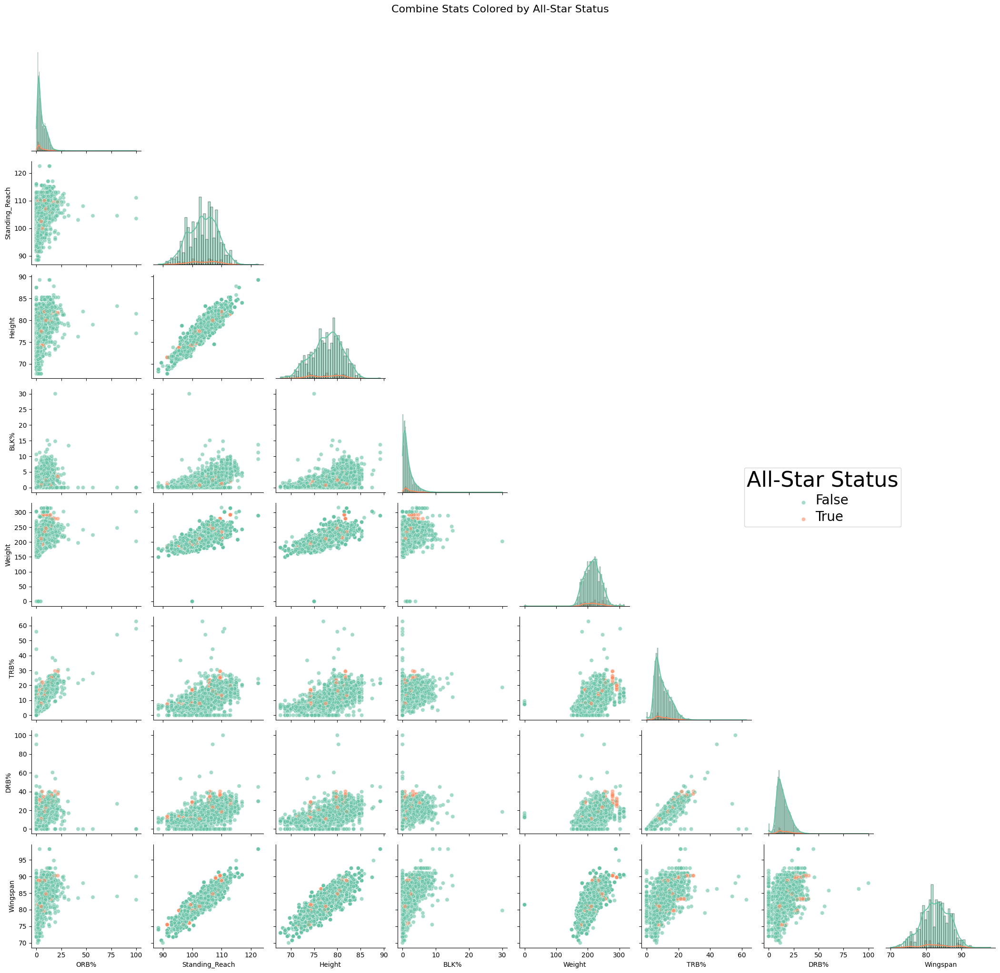

In [237]:
# Select combine stats + award
df_plot = combined_award.filter(pl.col("AllStar").is_not_null()).select(features_to_plot + ["AllStar"]).to_pandas()

# Convert AllStar to string for coloring
df_plot["AllStar"] = df_plot["AllStar"].astype(str)

# Create the PairGrid
g = sns.PairGrid(df_plot, vars=features_to_plot, hue="AllStar", palette="Set2", corner=True)
g.map_lower(sns.scatterplot, alpha=0.6)
g.map_diag(sns.histplot, kde=True)
g.add_legend(title="All-Star Status")
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.5))
    g.legend.set_frame_on(True)
    g.legend.set_title("All-Star Status", prop={'size': 32})
    for text in g.legend.get_texts():
        text.set_fontsize(20)

plt.suptitle("Combine Stats Colored by All-Star Status", y=1.02, fontsize=16)
plt.tight_layout()
temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "PairGrid_Combine_Stats_AllStar_Status.png")
plt.show()


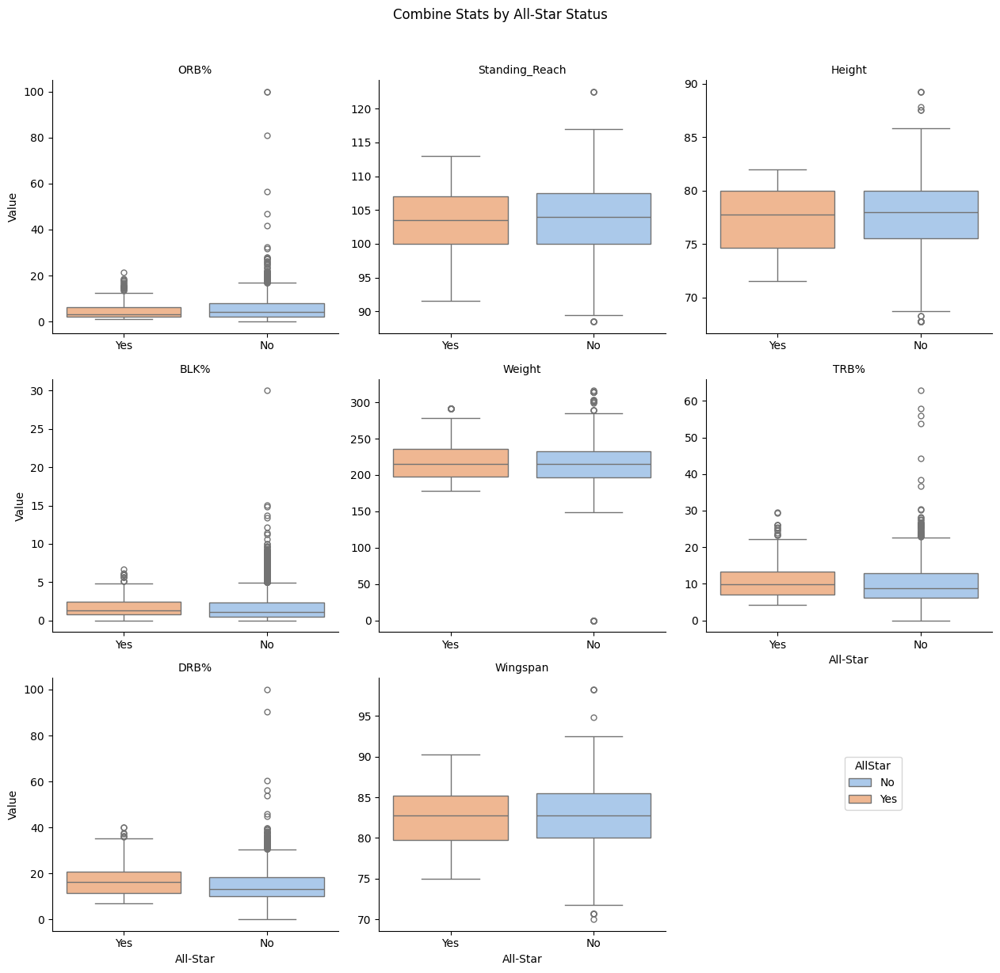

In [238]:

# Select combine stats and AllStar flag
df_plot = combined_award.select(features_to_plot + ["AllStar"]).to_pandas()
df_plot["AllStar"] = df_plot["AllStar"].map({True: "Yes", False: "No"})

# Melt to long format for faceting
df_melted = df_plot.melt(id_vars="AllStar", var_name="Stat", value_name="Value")

g = sns.catplot(
    data=df_melted,
    x="AllStar", y="Value",
    col="Stat", col_wrap=3,
    kind="box",
    order=["Yes", "No"],
    height=4, sharey=False,
    sharex=False,
    fill=True,
    palette="pastel",
    legend=True,
    hue="AllStar"
)

g.set_titles("{col_name}")
g.set_axis_labels("All-Star", "Value")
g.fig.suptitle("Combine Stats by All-Star Status", y=1.02)
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.2))
    g.legend.set_frame_on(True)
plt.tight_layout()
temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Combine_Stats_by_AllStar_Status.png")
plt.show()



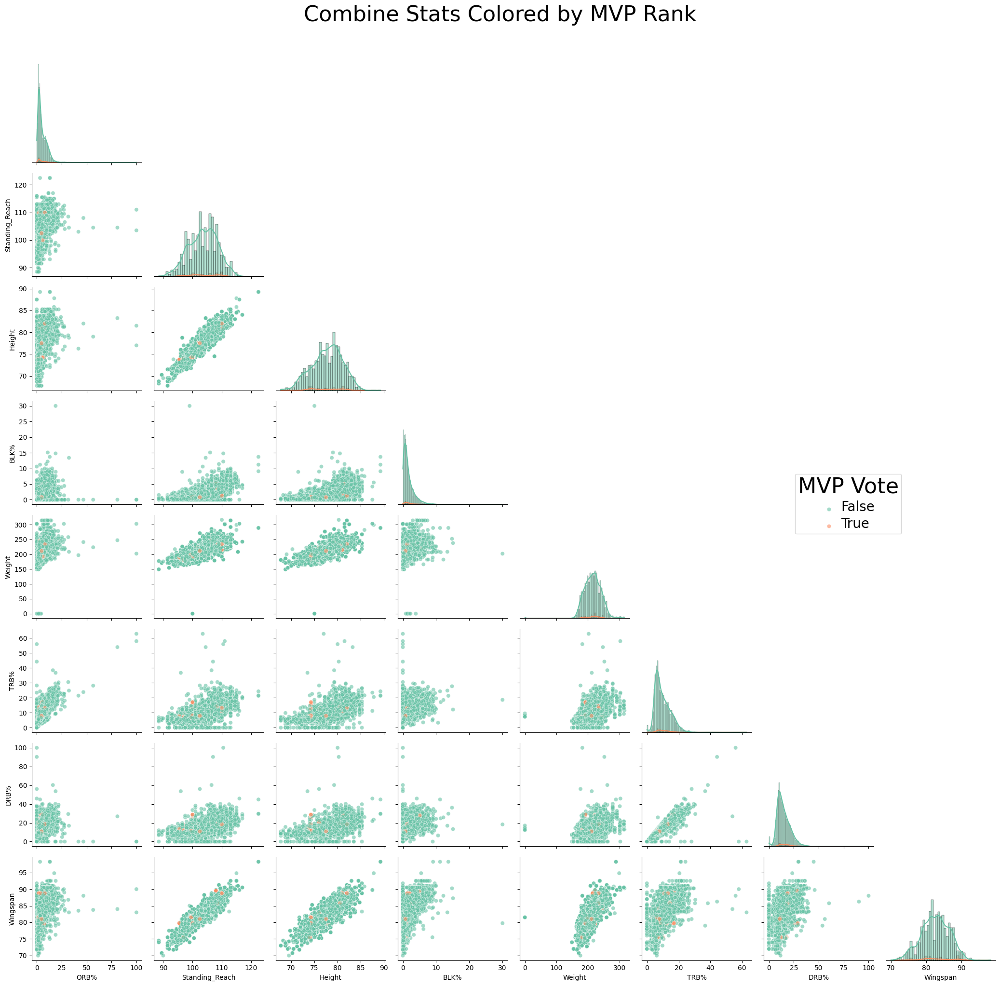

In [239]:
# Select combine stats + award
df_plot = combined_award.with_columns(
    (pl.col("MVP_Rank") > 0).alias("MVP_Vote")
)
df_plot = df_plot.filter(pl.col("MVP_Vote").is_not_null()).select(features_to_plot + ["MVP_Vote"]).to_pandas()

# Convert MVP_Rank to string for coloring
df_plot["MVP_Vote"] = df_plot["MVP_Vote"].astype(str)



# Create the PairGrid
g = sns.PairGrid(df_plot, vars=features_to_plot, hue="MVP_Vote", palette="Set2", corner=True)
g.map_lower(sns.scatterplot, alpha=0.6)
g.map_diag(sns.histplot, kde=True)
g.add_legend(title="MVP Vote")
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.5))
    g.legend.set_frame_on(True)
    g.legend.set_title("MVP Vote", prop={'size': 32})
    for text in g.legend.get_texts():
        text.set_fontsize(20)
plt.suptitle("Combine Stats Colored by MVP Rank", y=1.02, fontsize=32)
plt.tight_layout()
temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "PairGrid_Combine_Stats_by_MVP_Vote.png")
plt.show()

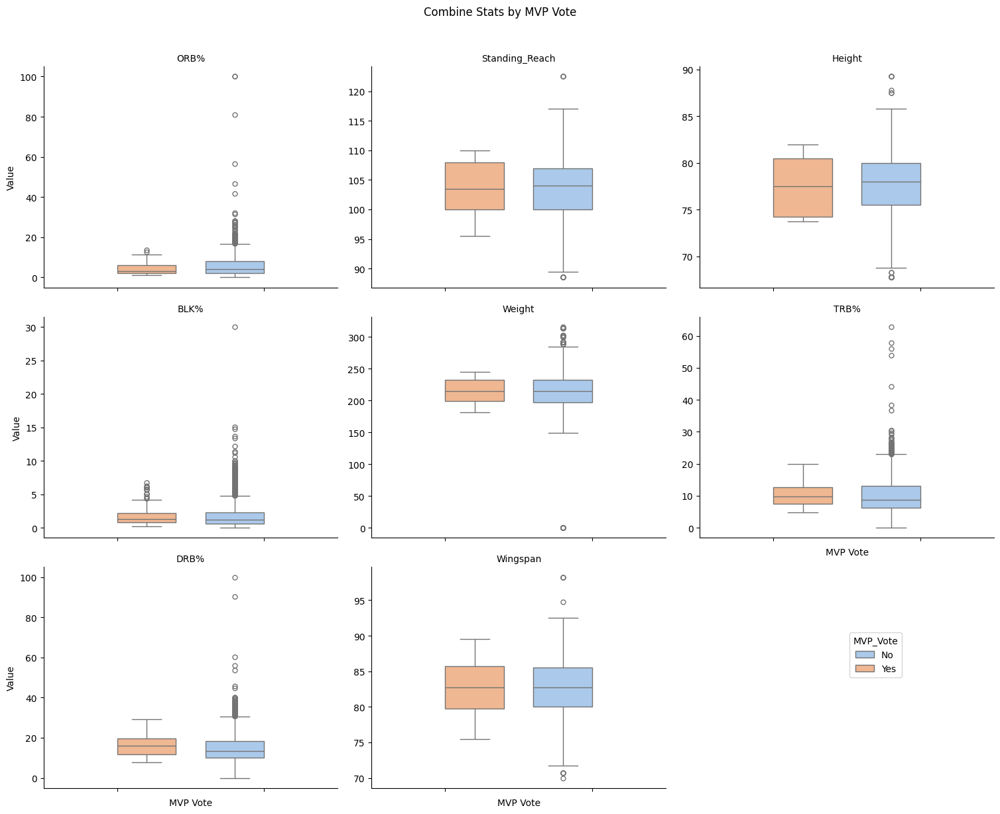

In [240]:

# Select combine stats + award
df_plot = combined_award.with_columns(
    (pl.col("MVP_Rank") > 0).alias("MVP_Vote")
)
df_plot = df_plot.filter(pl.col("MVP_Vote").is_not_null()).select(features_to_plot + ["MVP_Vote"]).to_pandas()

df_plot["MVP_Vote"] = df_plot["MVP_Vote"].map({True: "Yes", False: "No"})

# Melt to long format for faceting
df_melted = df_plot.melt(id_vars="MVP_Vote", var_name="Stat", value_name="Value")

g = sns.catplot(
    data=df_melted,
    x="MVP_Vote", y="Value",
    col="Stat", col_wrap=3,
    kind="box",
    order=["Yes", "No"],
    height=4,
    palette="pastel",
    legend=True,  # Disable legend for now
    dodge=True,  # Bars will be side-by-side instead of stacked
    aspect=1.2,  # Adjust aspect ratio for better spacing
    sharey=False,  
    sharex=False,
    fill=True,
    hue="MVP_Vote",  # Use hue to color by MVP_Vote
)

g.set_titles("{col_name}")
g.set_axis_labels("MVP Vote", "Value")
g.fig.suptitle("Combine Stats by MVP Vote", y=1.02)
# Remove x-tick labels to avoid clutter
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.2))
    g.legend.set_frame_on(True)
for ax in g.axes.flatten():
    ax.set_xticklabels([])

temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Combine_Stats_by_MVP_Vote.png")
plt.tight_layout()
plt.show()

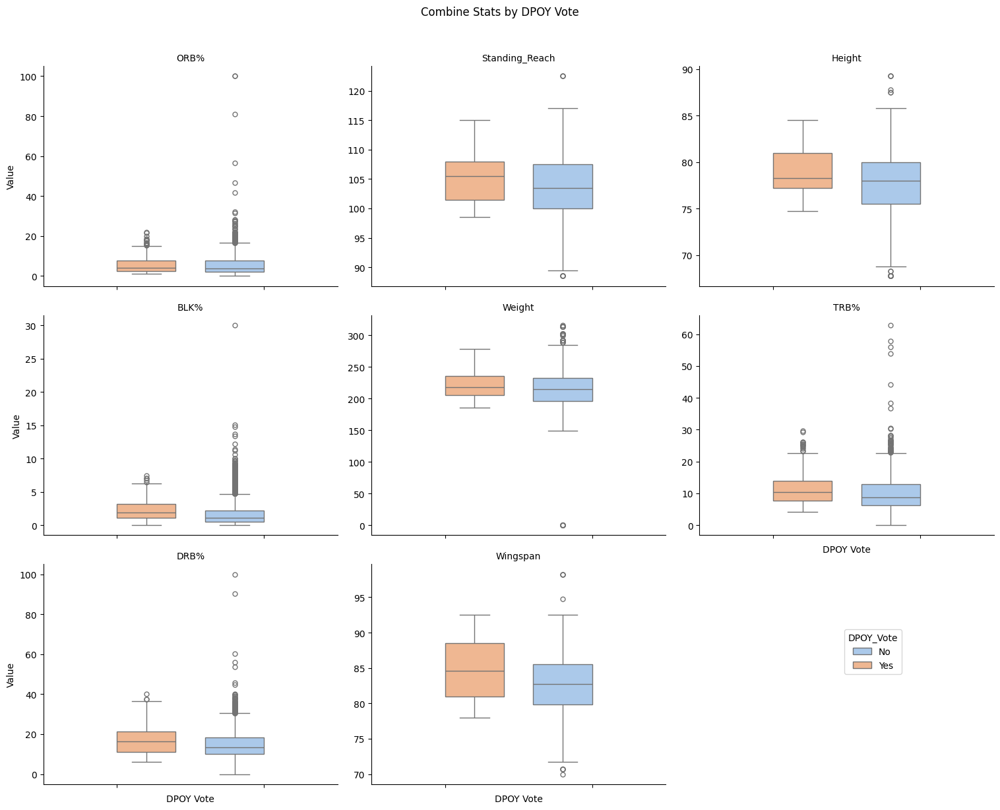

In [241]:
# Select combine stats + award
df_plot = combined_award.with_columns(
    (pl.col("DPOY_Rank") > 0).alias("DPOY_Vote")
)
df_plot = df_plot.filter(pl.col("DPOY_Vote").is_not_null()).select(features_to_plot + ["DPOY_Vote"]).to_pandas()

df_plot["DPOY_Vote"] = df_plot["DPOY_Vote"].map({True: "Yes", False: "No"})

# Melt to long format for faceting
df_melted = df_plot.melt(id_vars="DPOY_Vote", var_name="Stat", value_name="Value")

g = sns.catplot(
    data=df_melted,
    x="DPOY_Vote", y="Value",
    col="Stat", col_wrap=3,
    kind="box",
    order=["Yes", "No"],
    height=4,
    palette="pastel",
    legend=True,  # Disable legend for now
    dodge=True,  # Bars will be side-by-side instead of stacked
    aspect=1.2,  # Adjust aspect ratio for better spacing
    sharey=False,  
    sharex=False,
    fill=True,
    hue="DPOY_Vote",  # Use hue to color by DPOY_Vote
)

g.set_titles("{col_name}")
g.set_axis_labels("DPOY Vote", "Value")
g.fig.suptitle("Combine Stats by DPOY Vote", y=1.02)
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.2))
    g.legend.set_frame_on(True)
for ax in g.axes.flatten():
    ax.set_xticklabels([])
temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Combine_Stats_by_DPOY_Vote.png")
plt.tight_layout()
plt.show()

In [242]:
df_plot.describe()

,ORB%,Standing_Reach,Height,BLK%,Weight,TRB%,DRB%,Wingspan
count,5985.000000,5965.000000,5965.000000,5985.000000,5961.000000,5985.000000,5985.000000,5977.000000
mean,5.375556,103.666199,77.739693,1.669490,215.347488,10.012314,14.654504,82.612358
std,4.743802,4.867866,3.283775,1.666693,26.489700,4.919827,6.510092,3.936244
min,0.000000,88.500000,67.750000,0.000000,0.000000,0.000000,0.000000,70.000000
25%,2.100000,100.000000,75.500000,0.600000,197.000000,6.400000,10.100000,80.000000
50%,3.900000,104.000000,78.000000,1.200000,215.000000,8.800000,13.400000,82.750000
75%,7.900000,107.500000,80.000000,2.300000,233.000000,13.000000,18.400000,85.500000
max,100.000000,122.500000,89.250000,30.000000,316.000000,62.799999,100.000000,98.250000


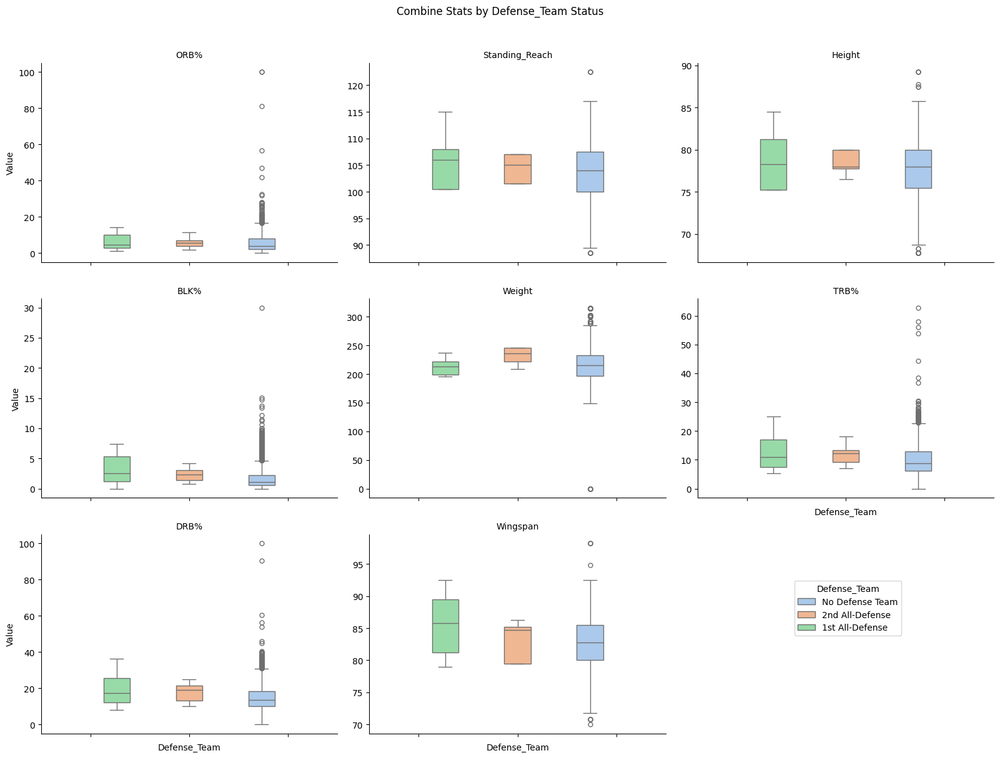

In [243]:
# Select combine stats and AllStar flag
df_plot = combined_award.select(features_to_plot + ["Defense_Team"]).to_pandas()
df_plot["Defense_Team"] = df_plot["Defense_Team"].map({0: "No Defense Team", 1: "1st All-Defense", 2: "2nd All-Defense"})

# Melt to long format for faceting
df_melted = df_plot.melt(id_vars="Defense_Team", var_name="Stat", value_name="Value")

g = sns.catplot(
    data=df_melted,
    x="Defense_Team", y="Value",
    col="Stat", col_wrap=3,
    kind="box",
    order=["1st All-Defense", "2nd All-Defense", "No Defense Team"],
    height=4, sharey=False,
    sharex=False,
    fill=True,
    palette="pastel",
    legend=True,  # Disable legend for now
    dodge=True,  # Bars will be side-by-side instead of stacked
    aspect=1.2,  # Adjust aspect ratio for better spacing
    hue="Defense_Team",  # Use hue to color by Defense_Team
)

g.set_titles("{col_name}")
g.set_axis_labels("Defense_Team", "Value")
g.fig.suptitle("Combine Stats by Defense_Team Status", y=1.02)
plt.tight_layout()
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.2))
    g.legend.set_frame_on(True)
for ax in g.axes.flatten():
    ax.set_xticklabels([])

temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Combine_Stats_by_Defense_Team.png")
plt.show()

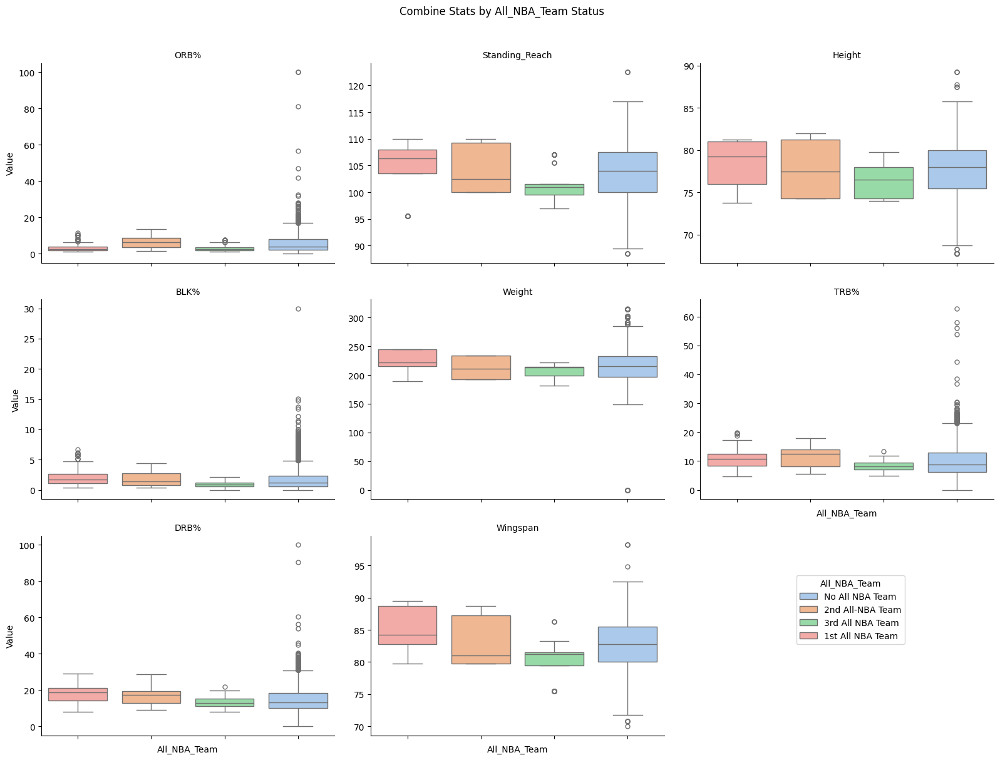

In [244]:
# Select combine stats and AllStar flag
df_plot = combined_award.select(features_to_plot + ["All_NBA_Team"]).to_pandas()
df_plot["All_NBA_Team"] = df_plot["All_NBA_Team"].map({0: "No All NBA Team", 1: "1st All NBA Team", 2: "2nd All-NBA Team", 3: "3rd All NBA Team"})

# Melt to long format for faceting
df_melted = df_plot.melt(id_vars="All_NBA_Team", var_name="Stat", value_name="Value")

g = sns.catplot(
    data=df_melted,
    x="All_NBA_Team", y="Value",
    col="Stat", col_wrap=3,
    kind="box",
    order=["1st All NBA Team", "2nd All-NBA Team", "3rd All NBA Team", "No All NBA Team"],
    height=4, sharey=False,
    sharex=False,
    fill=True,
    hue="All_NBA_Team",  # Use hue to color by All_NBA_Team
    legend=True,  # Enable legend
    aspect=1.2,  # Adjust aspect ratio for better spacing
    palette="pastel"
)

g.set_titles("{col_name}")
g.set_axis_labels("All_NBA_Team", "Value")
g.fig.suptitle("Combine Stats by All_NBA_Team Status", y=1.02)
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.2))
    g.legend.set_frame_on(True)
plt.tight_layout()
for ax in g.axes.flatten():
    ax.set_xticklabels([])

temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Combine_Stats_by_All_NBA_Team.png")
plt.show()

In [245]:
from scipy.stats import ttest_ind, mannwhitneyu, f_oneway
import polars as pl

def stat_tests_numerical_vs_award(df, numerical_cols, award_col):
    """
    Perform statistical tests (t-test, Mann-Whitney, ANOVA) for each numerical column vs award (categorical).
    Returns a Polars DataFrame with results.
    """
    results = []
    # Only keep rows where award_col is not null
    df_award = df.filter(pl.col(award_col).is_not_null())
    # Get unique award values (e.g., True/False, 0/1/2, etc.)
    award_values = df_award[award_col].unique().to_list()
    # Only run if at least two groups
    if len(award_values) < 2:
        return pl.DataFrame()
    for col in numerical_cols:
        # Prepare groups
        groups = [df_award.filter(pl.col(award_col) == val)[col].drop_nulls().to_numpy() for val in award_values]
        # Only run if at least two groups with >1 value
        valid_groups = [g for g in groups if len(g) > 1]
        if len(valid_groups) < 2:
            continue
        # ANOVA
        try:
            anova_p = f_oneway(*valid_groups).pvalue
        except Exception:
            anova_p = None
        # For binary awards, run t-test and Mann-Whitney
        if len(valid_groups) == 2:
            try:
                ttest_p = ttest_ind(valid_groups[0], valid_groups[1], nan_policy='omit').pvalue
            except Exception:
                ttest_p = None
            try:
                mw_p = mannwhitneyu(valid_groups[0], valid_groups[1], alternative='two-sided').pvalue
            except Exception:
                mw_p = None
        else:
            ttest_p = None
            mw_p = None
        results.append({
            "stat": col,
            "award": award_col,
            "anova_p": anova_p,
            "ttest_p": ttest_p,
            "mannwhitney_p": mw_p
        })
    return pl.from_dicts(results)

# Example usage:
numerical_cols = ["Height", "Wingspan", "Standing_Reach", "Weight", "TRB%", "DRB%", "ORB%", "BLK"]
award_cols = ["AllStar", "All_NBA_Team", "Defense_Team", "MVP_Vote", "DPOY_Vote"]

temp = combined_award.with_columns(
    (pl.col("DPOY_Rank").fill_null(0) > 0).alias("DPOY_Vote"),
    (pl.col("MVP_Rank").fill_null(0) > 0).alias("MVP_Vote"),
    pl.col("Defense_Team").fill_null(0).alias("Defense_Team"),
    pl.col("All_NBA_Team").fill_null(0).alias("All_NBA_Team")

)
results = []
for award in award_cols:
    results.append(stat_tests_numerical_vs_award(temp, numerical_cols, award))
stat_award_results = pl.concat(results)

for award in award_cols:
    print(f"Results for {award}:")
    temp = stat_award_results.filter((pl.col("award") == award)).sort(by=pl.col("anova_p")).fill_null(1)
    melted = temp.unpivot(
        index="stat",
        on=["anova_p", "ttest_p", "mannwhitney_p"],
        variable_name="test",
        value_name="p_value"
    )
    melted = melted.filter(pl.col("p_value") < 0.05)
    display(melted.pivot(
        on="stat",
        index="test",
        values="p_value"
    ))

Results for AllStar:


test,BLK,DRB%,TRB%,Weight,ORB%
str,f64,f64,f64,f64,f64
"""anova_p""",9.4496e-28,1.6265e-14,0.000059,0.002094,0.009779
"""ttest_p""",9.4497e-28,1.6266e-14,0.000059,0.002094,0.009779
"""mannwhitney_p""",9.4452e-26,2.9793e-12,0.000042,null,0.016868


Results for All_NBA_Team:


test,BLK,Wingspan,ORB%,DRB%,Standing_Reach,TRB%,Height,Weight
str,f64,f64,f64,f64,f64,f64,f64,f64
"""anova_p""",1.1561e-19,1.5290e-13,3.5617e-7,6.0046e-7,0.000002,0.000334,0.000526,0.00203


Results for Defense_Team:


test,BLK,DRB%,Wingspan,TRB%,Weight,Standing_Reach,Height
str,f64,f64,f64,f64,f64,f64,f64
"""anova_p""",3.3433e-31,3.6973e-9,1.0416e-7,0.000006,0.000008,0.000433,0.006165


Results for MVP_Vote:


test,BLK,DRB%,ORB%,TRB%
str,f64,f64,f64,f64
"""anova_p""",3.7667e-15,0.000744,0.001808,null
"""ttest_p""",3.7667e-15,0.000744,0.001808,null
"""mannwhitney_p""",1.0720e-14,9.2130e-7,0.014748,0.004701


Results for DPOY_Vote:


test,BLK,Wingspan,DRB%,Height,Standing_Reach,TRB%,Weight
str,f64,f64,f64,f64,f64,f64,f64
"""anova_p""",2.7584e-36,7.1179e-13,6.6967e-11,1.5043e-8,2.2556e-8,1.4234e-7,0.000057
"""ttest_p""",2.7584e-36,7.1186e-13,6.6967e-11,1.5044e-8,2.2554e-8,1.4234e-7,0.000057
"""mannwhitney_p""",2.9938e-20,4.4214e-9,2.6399e-9,1.8382e-7,1.8549e-7,6.9296e-7,0.000216


## Key Insights: Statistical Tests Linking Physical Attributes to NBA Defensive Performance

Statistical tests (ANOVA, t-test, Mann-Whitney) confirm that several physical combine metrics—**Block Percentage (BLK)**, **Wingspan**, **Defensive Rebound Percentage (DRB%)**, **Height**, and **Standing Reach**—are highly significant predictors of elite NBA defensive outcomes and recognition:

- **Block Percentage (BLK):** BLK shows extremely low p-values across all tests, indicating a robust statistical difference between DPOY winners and other players. Higher BLK rates are consistently associated with greater height, standing reach, and wingspan.

- **Wingspan:** Statistical tests reveal a strong association between wingspan and both BLK and DRB%. Players with longer wingspans have significantly better defensive stats and are more likely to receive defensive awards.

- **Defensive Rebound Percentage (DRB%):** DRB% is statistically linked to height, standing reach, and wingspan. Taller players with greater reach have significantly higher DRB%, as shown by very low p-values.

- **Height and Standing Reach:** Both metrics yield highly significant p-values in distinguishing defensive award winners. Players with superior height and reach excel in blocking and rebounding, and these differences are statistically robust.

- **NBA Awards:** DPOY winners and All-Defensive Team members consistently rank higher in these physical metrics, with statistical tests confirming the differences are not due to chance.

**Conclusion:**  
Statistical evidence strongly supports that combine-measured physical attributes—especially BLK, wingspan, DRB%, height, and standing reach—are reliable predictors of defensive performance and NBA accolades. These findings validate the use of combine data and statistical testing in scouting and player evaluation.

---

## Summary of Findings

This notebook provides a comprehensive exploratory analysis of NBA Draft Combine data and its relationship with NBA performance and awards, using both visualizations and statistical tests. Key findings include:

- **Data Coverage & Quality:** The dataset covers 1,677 NBA players across multiple seasons, though not all NBA players are represented. Some combine metrics (e.g., Shuttle_Run, Hand measurements, Max_Bench_Press, Body_Fat) have substantial missing values, which may require imputation or exclusion for modeling.

- **Univariate Analysis:** Most physical and athletic metrics (Height, Wingspan, Standing Reach, Vertical Leap) display near-normal distributions and reasonable central tendency. Outliers and data quality issues are present in some features (BMI, Weight, Shuttle_Run), with minimum values of zero likely indicating errors.

- **Bivariate Analysis & Statistical Tests:**  
    - **Correlations:** Strong correlations exist among physical attributes (Height, Wingspan, Standing Reach, Weight) and rebounding/blocking performance (TRB%, DRB%, ORB%, BLK%).  
    - **Statistical Significance:** T-tests, Mann-Whitney, and ANOVA confirm these relationships are highly significant (p-values often < 0.001). For example, Height and Standing Reach are highly correlated with Defensive Rebound Percentage (DRB%), while Wingspan and Weight are linked to Total Rebound Percentage (TRB%) and Block Percentage (BLK%).
    - **Position Differences:** ANOVA and pairwise t-tests reveal extremely significant differences in Height, Standing Reach, Wingspan, and Weight between positions (e.g., Centers vs Guards), confirming expected positional archetypes.
    - **Combine vs NBA Performance:** Statistical tests show that combine metrics are robust predictors of NBA stats, with high correlation coefficients and extremely low p-values for top pairs.

- **Position & Season Trends:** Physical and performance metrics vary by position, with centers and power forwards generally exhibiting higher values in height, wingspan, and rebounding stats. Trends across seasons show some variation in combine attendance and metric averages.

- **Physical Traits & NBA Awards:**  
    - **Boxplots and Pairplots:** Players with above-median physical attributes (Height, Wingspan, Standing Reach) are more likely to achieve higher rebounding/blocking stats and receive NBA accolades (All-Star, All-NBA Team, Defensive Team, MVP/DPOY votes).
    - **Statistical Tests for Awards:** ANOVA, t-tests, and Mann-Whitney confirm that award recipients (especially DPOY and All-Defense) have significantly higher values in key physical and performance metrics (BLK, Wingspan, DRB%, Height, Standing Reach).

- **Visual Insights:** The analysis uses heatmaps, barplots, boxplots, and pairplots to highlight relationships between combine metrics, NBA stats, and awards, providing clear evidence that standout physical traits are associated with superior on-court performance and recognition.

**Conclusion:**  
Physical attributes measured at the NBA Draft Combine—especially Height, Wingspan, and Standing Reach—are strong, statistically significant predictors of rebounding and blocking success in the NBA and are associated with a higher likelihood of earning major awards. Data quality and missingness should be addressed for robust modeling, but the overall relationships are statistically and visually clear.